In [ ]:
# Run all on a standard Google Colab CPU runtime. Data and outputs stay in this notebook.
import os
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['MKL_NUM_THREADS'] = '1'
import base64, copy, gc, hashlib, io, json, pickle, time, zlib
from dataclasses import dataclass
import numpy as np
import pandas as pd
import scipy, sklearn
from scipy.optimize import minimize
from scipy.special import expit, logit, logsumexp
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.cluster import KMeans
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (balanced_accuracy_score, roc_auc_score, f1_score,
                             log_loss, brier_score_loss, confusion_matrix)
from threadpoolctl import threadpool_limits
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter
from IPython.display import display, HTML
get_ipython().run_line_magic('matplotlib', 'inline')
THREAD_LIMIT = threadpool_limits(limits=1)
MAIN = 'Ours'
OUTER_FOLDS, INNER_FOLDS = 5, 3
CV_SEED = 20261107
RATES = [0.0, 0.1, 0.2, 0.4, 0.6]
MECHANISMS = ['MCAR', 'group dropout']
MASK_REPEATS = 3
D, LEVELS = 1024, 32
BOOTSTRAPS = 1000
plt.rcParams.update({
    'figure.dpi': 125, 'figure.facecolor': '#FFFFFF', 'axes.facecolor': '#F7F9FC',
    'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.titlesize': 13,
    'axes.titleweight': 'bold', 'axes.titlepad': 13, 'axes.labelcolor': '#203149',
    'text.color': '#203149', 'xtick.color': '#53657A', 'ytick.color': '#53657A',
    'axes.edgecolor': '#D6DEE8', 'axes.spines.top': False, 'axes.spines.right': False,
    'grid.color': '#DFE6EF', 'grid.alpha': 0.8, 'grid.linewidth': 0.7,
    'legend.frameon': False, 'savefig.bbox': 'tight', 'axes.axisbelow': True})
pd.set_option('display.max_columns', 20)
print('CPU | NumPy', np.__version__, '| scikit-learn', sklearn.__version__)
print(MAIN, '| nested subject-stratified CV:', OUTER_FOLDS, 'x', INNER_FOLDS)


CPU | NumPy 2.1.3 | scikit-learn 1.6.1
Ours | nested subject-stratified CV: 5 x 3


In [ ]:
# WDBC and Statlog Heart only; internal development evaluation.
# UCI CC BY 4.0: doi.org/10.24432/C5DW2B and doi.org/10.24432/C57303
# Heart bytes are embedded and verified; WDBC is bundled with scikit-learn.
EMBEDDED = {'heart': ('f5f3b4204c285bafadd85cb735f38b47689f2be7047feb172dcbeab648110bf9', 'eNqNW1mWHDkI/PcpfIJ5ArTe/2LTJWVJBKB0f9jubJdKGwRBQLb0X/pLP3/y51/5PAnzz9+fnz7/Uhr7Kc/fyPOH/9T2/Nfnkaj8/F1q1oNrep7ov/r3+7WfUfSntGfm+UH+DONKz0fmkHye5C+pwT8zZ71s7nOw6MGpPJ9I//GaYs/cYIk8f6oDfkdq8Pfnuck/tcDMc67WYNlpP2VY9s+eq/6uedq8fzdnzrxnrnvZde65DD0zzcECy96Dyez558DgnucSeYge3M5VrcF8Bn8/OAeX+VNqenDJ6hNfI2nBsqXMZWd9YOrWizUSgWXPZXHVM9O5qmROO2d92mvPc/49uCe9Dm3Mfyrts/wsO/tl5/NVdR/YcozS9IFN85QEp12GmflYWCM9mNbNwse5BF61Bufq7lkIvIrPjN3cszntudgk2jxL2UulvxK7JB3z3DOvTWQzs1q2PoY1Mw3Yc+v7E9aranMuyYz+PPYmqtlz7np/yyXzzUjYLhsObALguee57E7Gq9RgWPa8Z05oYeeryJhnAQyTObjDVrbfeQube04IQ63omWWoPZO3sG2eMqE3o22zmhn3XOC71lUNOO1ysLTaPXe9i3VgkiDcnK8qBgAbfNcyz43l5+5jl9yxSk64QQsrGvQN9IJL1mWeHa7vPJ1AN0f9keYPjOCq2h3DEHrbCu6Antvv5GfZ6M8FI8YEwASnzXXPOAC3lVflW6AryZinCjcUwFBzB7Y+NfZVmXBD57QbmCeXy4H9LJtdfDYxotxPG/fMK1YBler1PhhOu6zBMZLYQPdzYAzhZl0VoCdyI5w5e04i8PF2kCRHYLDvNM0zH03fbKmXZSvzlG1NTF0PloNybNlQ98F9cwEEg2DPMPOaMw9n22tw3598jCQ7Hrb2fKhUuyCJAoNDjznXMD4nRSnWnveODg9jBvSkbDzq8LBt28sl62QGxdEKG5+f02Yg6xMAFcP+mGe+U6miH+dVZQL2r0C/W74tHq9GceaZgn3/3DMczmPbEDlV2HNUCsjL2u3o4FX9GjEQwxZe1epgaA04TF8OWUfQP/zn8zTqO+ZvG5mpDiN73KTFhucHSAgzo47HIHtWG+cwSC58VyHisxoxrOLkZAVI78pDE1yzS25UtAEIewggHFEdd+uEC1xOlQHl20HeYQcL8NaywZMcMfjEdoHYXoAArpkbJjcv2WAQJCu5aEOxkSD9WFgwYNl8carntBOAJ2f4uLI3AdNWpHc+JmSPKZxZmSd5ol+Ty72tU7UoJ5vfWrILkhRSz5bgcKrPEvI9wu47FQVhTVsd1f1EBoUqLDtVTwzU2UuEf5g+S0LJoAXR5vEqGJwWqwDDyToG47J3AvF5HDnI5+4emdlzXqQzTR+AyTCqhzCpLpPUwSbIMNZ5HUaCstJ3VjQwCZQhjBdy4kQ1EIYzP1iQLkJHN/wvk6dwhDpcN8tOPrdRslJCxaDuZRfgBfRHgfLXHjhjgLWnfayzRqQCctj8i9yG9izmwPJhSwy5jQ3tc3+S6i8JMyZGT8DADKMbZSj59OTsjxlOe+soF03KBEmTAI8reBaUTJfeWp3SS4Ztt2DwYyQ4uBsgOXSmAPOcvIeJQyJFLhnMgXk25LzdDAzYtsL8BClZIZO338AgJa8AqtyGTBpas8N8IbApkUBiacfCjECdMVSxChhBPpcgwmol/Z3zRlKa6Gym2ZRdJc/DWSfX32ahiEIzY+A+XIUgTm2qBGpDdmEupq0mbZ9+gRWCWi/6tGJhcmyEOWTbXgDc1EUBCTKz0gKJOZLVc1CHqBwIgCq0G5aJREr6PcJCFtqXqoR0pilVyRgJOCqhJr+cSv5N1deBdUgS2JQSQvw7oufSagFrX5S0HCRGmIVWflcbDtteFkbXwW+C/oMFw8nqKSQGRWu1S70zKrFo1xGU4apPjDCrUhyj7ghraJhyyQ6JURJFhlB6RHlmManeQ32afb0pexmuY1Z1qnAcFW6MDNc08vZ+L7GBzDFtVWq6BJse6flny8XLliovKn8F5ensZjYUziEveRamkyoNJGPcC0Zgq5Nm06gXQmIzG9SUllvgqku/y0JAwibgsICkXJMpGN3qmSsJNZEq2nPEKVYVgthVY8jQAglEuBz4VOt3+MsBFOjTHlUROEEOlp04w8Jh7YRU9tuw5CNHiGnN1fm/hy1xAivKpSBQNb4XXqqnjhkpdA4ccu0Zlb4lVBBg/Dgzt1dCsgpsqTnSGlee8aZyudiIBjC+1PlXga2hssP/Tk50zVsuUOAkEqh5P0RdQtHy61TkEYz3yS7E34NHCe45qjxPfYNhl0OX6gIQMg6Jtbyarno81l2WmF+bk9TJpM4tqEEsG2HMfo8vsE1ssCA5B0OavvwizgQx41+DsTT1oq+UFNQURwi8vsGg+PSC8cBqe0cwq/KCdXLkF1HtWNUUDxMaKkReqtZHzDfF9vbiVMWjNsEutzhTPJkpTuUQlNHeKrgVPHKBFjiVygSHaZ6pUKlfEgkDaNViUudjntLdzCwQnftB224cAwuSJUhgS1ZAgilC8VV5RnZd7pU9TNqXplSGqwJp0VK5pHitAZtnKl2rmWjbT1pUwj2/uKSaGTPY8uLP4qvWo4VqPikpzJTIVLSRemnncBlsgSapvmF7z9xykHg/RCqo1AsEEWVvZOoIdfg4Z1L+ek0RUOVYadEYYZz7tjYo/tcD9ITwTIdJFSuLY5NUh2iOBxagJ/urGmBTqRowOFXrqF6E6jSfOMq2FFAD9oi9moflVVtUbJ7DoStUMR1W7LtQ5PRxjd8qtdjOwae0t2ceOncW36t5TjvPpkff80PqtNkr8opWNBQe+7WdI8M9J96tSsc8+argBWDA2KXR7IGJ72c7g02PAISbN66+kqCefQ19PpEtZwKJW7RCdKH6WNg3q5IDvXBgS2wdORTSvArXwMJqIFvSQbTxqotn7MlNpgOab0XFkyUY9+ei+hZNexYgZepQ2vtX540pVVWg26fESbF5AutdgmmBXpBWrh0ZBTsyChBXlPAoVuQT4nbuoWOQly2zbwCk/EvWuw2CbvdczrJtnat5AJSUHYmjwCWfcIOtSiZ9LlbjVV0VPZgZTrtRcFVRy/iD21j/PdSx31JJHW58DZcCvYEN314u2Yer7X2LoWZmKEkuvWEA6209AIOGCrNs6BUsANeXLlG4qpVj5OTa5MngtpEMRF0VHJhQ0J71kPUWvFcAC+0nPhcr1WIl9YjEEffk1wLII9AAgVc1xhy1Tx8qxaA3JNPDx6/lucX0CYirkKlnHkLDw+cY4JKcXvR88l1l6M+NFYYFHUNYhuDC4eCA6evTnhGOub2mGAoLgiYp484tqIWaVylU/YPTb9uQ88uLK9hh4IEE37eR4ok+H/Wh/6IlDZv2VH5Sb71dttpOTugl1SSqmkGQq1MXlz7HNoJFsrVnlEkkKhhVJEMKC4AjD8uFCBPgBBROzGJq0PKj1DBTL8KST2VjmUExQCdG4M0j3bcMfRF5YWdzySAZXvDcFL5W1b0altMlXtgeqUmVGWs+/UWr4ECrKE5uiEu4lYO2bUzJqmIk/EKY6+k78c0z9VEMBLVaqxjEb/0F2Ckvr88x9D+zq7Zj8+CauTRHW/9x2mcWo88o4LVUHVlYT7suSEEyWG8WpnpB+NeCvgRdFfnSeWgDbJAYGY1ZEZ66fVopBqaFxfT/sRI63upzDyPBtsUclBIizKeA56vsue47qEEZthSfz+V7A2D15ZPjwQzao/juaZ/PmaxKtRG4Uqov7pmaN91brzE8Cyr67L8qfgFE1U8G0la51k+Q/1GQ/rHcX+gaXlYiSIVU3u5acsnZsSBpU6Jxtq2H5GeGvnjalJriBhgUOqT48HzpEvAvpYppgOn395MkaD1sYa86uRJI8cKlmEZ3fm+9Mf6MDYBybDtb2+7BawW398R71FZmywH10p9fb+9kqXYjHtfWQyOxQIhd1bgBb1VWDgpOd8aMUmWT+5tR/iU9NoLWAQN5bejNttCNAJgtlWpB6h03en7V7aNV/A/8MijY')}

@dataclass
class Dataset:
    name: str
    X: np.ndarray
    y: np.ndarray
    feature_names: list
    groups: np.ndarray
    group_names: list
    categorical: tuple
    subjects: np.ndarray


def embedded_text(name):
    digest, encoded = EMBEDDED[name]
    raw = zlib.decompress(base64.b64decode(encoded))
    assert hashlib.sha256(raw).hexdigest() == digest
    return io.StringIO(raw.decode('utf-8'))


# Groups are defined measurement families for a controlled dropout benchmark.
def load_datasets():
    b = load_breast_cancer()
    breast = Dataset('WDBC', b.data.astype(np.float64), (1-b.target).astype(int),
                     list(b.feature_names), np.tile(np.arange(10), 3),
                     ['radius', 'texture', 'perimeter', 'area', 'smoothness',
                      'compactness', 'concavity', 'concave points', 'symmetry', 'fractal dimension'],
                     (), np.arange(len(b.target)).astype(str))
    heart = np.loadtxt(embedded_text('heart'))
    heart_names = ['age', 'sex', 'chest pain', 'resting BP', 'cholesterol', 'fasting blood sugar',
                   'resting ECG', 'max heart rate', 'exercise angina', 'ST depression',
                   'ST slope', 'major vessels', 'thal']
    heart = Dataset('Statlog Heart', heart[:, :-1], heart[:, -1].astype(int)-1,
                    heart_names, np.array([0,0,1,2,3,3,4,5,1,4,4,6,6]),
                    ['demographics', 'symptoms', 'blood pressure', 'blood tests',
                     'ECG/ST', 'exercise', 'imaging'], (1,2,5,6,8,10,12),
                    np.arange(len(heart)).astype(str))
    datasets = [breast, heart]
    for ds in datasets:
        assert np.isfinite(ds.X).all() and set(np.unique(ds.y)) == {0,1}
        assert len(ds.groups) == ds.X.shape[1] == len(ds.feature_names)
        assert ds.groups.max()+1 == len(ds.group_names)
    return datasets

DATASETS = load_datasets()
display(pd.DataFrame([{'dataset': d.name, 'records': len(d.y), 'features': d.X.shape[1],
    'feature_groups': len(d.group_names), 'negative': int((d.y==0).sum()),
    'positive': int((d.y==1).sum())} for d in DATASETS]))


,dataset,records,features,feature_groups,negative,positive
0,WDBC,569,30,10,357,212
1,Statlog Heart,270,13,7,150,120


In [ ]:
# Every transform uses observed training values only; missingness remains explicit.
class Quantizer:
    def __init__(self, levels=32, categorical=()):
        self.levels, self.categorical = levels, tuple(categorical)

    def fit(self, X):
        X = np.asarray(X,dtype=np.float64)
        self.n_features = X.shape[1]
        self.edges,self.categories = [],[]
        self.fill = np.zeros(self.n_features,dtype=np.float64)
        self.available = np.isfinite(X).any(axis=0)
        for j in range(self.n_features):
            observed = X[np.isfinite(X[:,j]),j]
            if j in self.categorical:
                values,counts = np.unique(observed,return_counts=True)
                if not len(values): values,counts = np.array([0.]),np.array([1])
                assert len(values)<=self.levels
                self.categories.append(values); self.edges.append(np.empty(0))
                self.fill[j] = values[np.argmax(counts)]
            else:
                self.fill[j] = np.median(observed) if len(observed) else 0.
                edges = np.quantile(observed,np.arange(1,self.levels)/self.levels) if len(observed) else np.empty(0)
                self.edges.append(np.unique(edges)); self.categories.append(np.empty(0))
        self.fill_bins,_ = self.transform(self.fill[None])
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=np.float64)
        if X.ndim != 2 or X.shape[1] != self.n_features:
            raise ValueError('X must have shape (n_samples, n_features).')
        mask = np.isfinite(X) & self.available[None]
        bins = np.zeros(X.shape, dtype=np.int32)
        for j in range(self.n_features):
            safe = np.where(mask[:, j], X[:, j], self.fill[j])
            if j in self.categorical:
                values = self.categories[j]
                idx = np.searchsorted(values, safe)
                known = (idx < len(values)) & (values[np.minimum(idx, len(values)-1)] == safe)
                mask[:, j] &= known
                bins[:, j] = np.clip(idx, 0, len(values)-1)
            else:
                bins[:, j] = np.searchsorted(self.edges[j], safe, side='right')
        return bins, mask


def subject_folds(ds, rows=None, n_splits=5, seed=0):
    rows = np.arange(len(ds.y)) if rows is None else np.asarray(rows)
    people, first = np.unique(ds.subjects[rows], return_index=True)
    labels = ds.y[rows[first]]
    assert min(np.bincount(labels)) >= n_splits
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    for fit, valid in cv.split(people, labels):
        a = rows[np.isin(ds.subjects[rows], people[fit])]
        b = rows[np.isin(ds.subjects[rows], people[valid])]
        assert not set(ds.subjects[a]) & set(ds.subjects[b])
        yield a, b


def person_weights(subjects):
    _, inverse, counts = np.unique(subjects, return_inverse=True, return_counts=True)
    w = 1.0/counts[inverse]
    return w/w.mean()


def masked_cases(X, groups, seed, repeats=1, rates=RATES):
    # Nested, label-independent masks; group probabilities give the target rate in expectation.
    rng = np.random.default_rng(seed)
    for rep in range(repeats):
        uniform = {'MCAR': rng.random(X.shape),
                   'group dropout': rng.random((len(X), int(groups.max())+1))[:, groups]}
        for mechanism in MECHANISMS:
            for rate in rates:
                if rate == 0 and rep > 0:
                    continue
                mask = (uniform[mechanism] >= rate) & np.isfinite(X)
                yield mechanism, rate, rep, np.where(mask, X, np.nan), mask


def clip_logit(p):
    return logit(np.clip(p, 1e-6, 1-1e-6))


def balanced_threshold(y, p, weights=None):
    weights = np.ones(len(y)) if weights is None else np.asarray(weights)
    grid = np.unique(np.r_[0.5, np.linspace(0.05,0.95,91)])
    predicted = p[:,None] >= grid[None]
    positive, negative = y == 1, y == 0
    sensitivity = np.average(predicted[positive], axis=0, weights=weights[positive])
    specificity = np.average(~predicted[negative], axis=0, weights=weights[negative])
    scores = 0.5*(sensitivity+specificity)
    best = np.flatnonzero(scores >= scores.max()-1e-12)
    return float(grid[best[np.argmin(np.abs(grid[best]-0.5))]])


def fast_ba(y, predicted, weights=None):
    weights = np.ones(len(y)) if weights is None else weights
    return 0.5*(np.average(predicted[y == 1], weights=weights[y == 1]) +
                np.average(~predicted[y == 0], weights=weights[y == 0]))


def show_table(frame, height=480):
    display(HTML('<div style="max-height:'+str(height)+'px;overflow:auto">'+
                 frame.to_html(index=False, float_format=lambda x: f'{x:.4f}')+'</div>'))


In [ ]:
# Bipolar role binding; correlated continuous levels; independent categorical values.
class HDEncoder:
    def __init__(self, quantizer, dim=1024, seed=0):
        self.quantizer, self.dim = quantizer, dim
        rng = np.random.default_rng(seed)
        f, levels = quantizer.n_features, quantizer.levels
        roles = rng.choice(np.array([-1, 1], np.int8), size=(f, dim))
        self.tokens = np.empty((f, levels, dim), dtype=np.int8)
        for j in range(f):
            if j in quantizer.categorical:
                values = rng.choice(np.array([-1, 1], np.int8), size=(levels, dim))
            else:
                start = rng.choice(np.array([-1, 1], np.int8), size=dim)
                order = rng.permutation(dim)
                # Adjacent levels have a small Hamming distance; endpoints are opposite.
                flip_at = np.empty(dim, dtype=np.int32)
                flip_at[order] = np.floor(np.arange(dim)*(levels-1)/dim).astype(int)+1
                values = start[None] * np.where(np.arange(levels)[:, None] >= flip_at, -1, 1)
            self.tokens[j] = values * roles[j]
        self.missing_tokens = rng.choice(np.array([-1, 1], np.int8), size=(f, dim))

    def bundle(self, bins, mask, mode='skip', normalize=True):
        h = np.zeros((len(bins), self.dim), dtype=np.float32)
        for j in range(bins.shape[1]):
            values = self.tokens[j, bins[:, j]].astype(np.float32)
            if mode == 'impute':
                values[~mask[:, j]] = self.tokens[j, self.quantizer.fill_bins[0, j]]
            elif mode == 'mask value':
                values[~mask[:, j]] = self.missing_tokens[j]
            else:
                values *= mask[:, j, None]
            h += values
        if normalize:
            count = mask.sum(axis=1) if mode == 'skip' else bins.shape[1]
            h /= np.sqrt(np.maximum(count, 1))[..., None] if np.ndim(count) else np.sqrt(count)
        return h


class PrototypeHDC:
    def __init__(self, encoder, X, y, mode):
        self.encoder, self.mode = encoder, mode
        self.prior = float(np.mean(y))
        bins, mask = encoder.quantizer.transform(X)
        f, dim = bins.shape[1], encoder.dim
        self.components = np.zeros((2, f, dim), dtype=np.float32)
        for j in range(f):
            tokens = encoder.tokens[j,bins[:,j]].astype(np.float32)
            population = tokens[mask[:,j]].mean(axis=0) if mask[:,j].any() else np.zeros(dim,np.float32)
            for c in (0,1):
                members = y==c
                values = tokens[members].copy(); observed = mask[members,j]
                if mode=='impute':
                    values[~observed] = encoder.tokens[j,encoder.quantizer.fill_bins[0,j]]
                    self.components[c,j] = values.mean(axis=0)
                elif mode=='mask value':
                    values[~observed] = encoder.missing_tokens[j]
                    self.components[c,j] = values.mean(axis=0)
                elif mode=='skip':
                    self.components[c,j] = (values*observed[:,None]).mean(axis=0)
                else:
                    self.components[c,j] = values[observed].mean(axis=0) if observed.any() else population
        self.global_prototypes = self.components.sum(axis=1)
        if mode != 'compatible':
            del self.components

    def raw_score(self, X):
        bins, mask = self.encoder.quantizer.transform(X)
        h = self.encoder.bundle(bins, mask,
                                self.mode if self.mode in ['impute', 'mask value'] else 'skip')
        hnorm = np.maximum(np.linalg.norm(h, axis=1), 1e-9)
        if self.mode == 'compatible':
            # C_c(mask) = sum_i mask_i C_c,i, without missing feature contributions.
            p = np.einsum('nf,cfd->ncd', mask.astype(np.float32), self.components, optimize=True)
            sim = np.einsum('nd,ncd->nc', h, p) / (
                hnorm[:, None] * np.maximum(np.linalg.norm(p, axis=2), 1e-9))
        else:
            p = self.global_prototypes
            sim = h @ p.T / (hnorm[:, None] * np.maximum(np.linalg.norm(p, axis=1), 1e-9))
        result = 5.0 * (sim[:, 1] - sim[:, 0])
        result[~mask.any(axis=1)] = clip_logit(self.prior)
        return result.astype(np.float64)


class MatchedHDC:
    def __init__(self, prototype):
        encoder = prototype.encoder
        self.quantizer = encoder.quantizer
        mu = prototype.components
        # Matching feature roles removes cross-feature interference.
        unit = mu / np.maximum(np.linalg.norm(mu, axis=2, keepdims=True), 1e-9)
        contrast = unit[1] - unit[0]
        self.response = np.einsum('fld,fd->fl', encoder.tokens.astype(np.float32),
                                  contrast, optimize=True) / np.sqrt(encoder.dim)
        self.prior = prototype.prior

    def features(self, X):
        bins, mask = self.quantizer.transform(X)
        return self.response[np.arange(bins.shape[1])[None], bins], mask

    def raw_score(self, X):
        q, mask = self.features(X)
        result = 5 * (q * mask).sum(axis=1) / np.maximum(mask.sum(axis=1), 1)
        result[~mask.any(axis=1)] = clip_logit(self.prior)
        return result


class CompiledHDC:
    # Deployment stores O(features * levels) responses and no D-dimensional vectors.
    def __init__(self, quantizer, table, intercept, prior, precision='float32', normalize=False):
        self.quantizer, self.intercept, self.prior = quantizer, float(intercept), float(prior)
        self.precision, self.normalize = precision, normalize
        if precision == 'float32':
            self.table = np.asarray(table, dtype=np.float32)
            self.scale = np.ones((table.shape[0], 1), dtype=np.float32)
        else:
            limit = np.iinfo(np.dtype(precision)).max
            self.scale = np.maximum(np.max(np.abs(table), axis=1, keepdims=True)/limit, 1e-12).astype(np.float32)
            self.table = np.rint(table/self.scale).clip(-limit, limit).astype(precision)
        contribution = np.asarray(table, np.float64)
        self.evidence_weights = np.maximum(np.var(contribution, axis=1), 1e-8)
        self.evidence_weights /= self.evidence_weights.sum()

    def raw_score(self, X):
        bins, mask = self.quantizer.transform(X)
        values = self.table[np.arange(bins.shape[1])[None], bins].astype(np.float64)
        values *= self.scale[:, 0][None]
        evidence_sum = (values * mask).sum(axis=1)
        if self.normalize:
            evidence_sum /= np.maximum(mask.mean(axis=1), 1.0/mask.shape[1])
        result = self.intercept + evidence_sum
        result[~mask.any(axis=1)] = clip_logit(self.prior)
        return result

    def evidence(self, X):
        _, mask = self.quantizer.transform(X)
        return mask @ self.evidence_weights


def fit_discriminative_hdc(matched, X, y, C, blend=1.0):
    q, mask = matched.features(X)
    count = np.maximum(mask.sum(axis=0),1)
    mean = (q*mask).sum(axis=0)/count
    scale = np.maximum(np.sqrt((((q-mean)**2)*mask).sum(axis=0)/count),1e-5)
    fraction = np.maximum(mask.mean(axis=1),1/mask.shape[1])
    Z = ((q-mean)/scale)*mask/fraction[:,None]
    # Nonnegative discriminative weights avoid correlation-induced sign reversals.
    def objective(v):
        z = Z @ v[:-1] + v[-1]
        residual = expit(z)-y
        loss = np.mean(np.logaddexp(0, z)-y*z) + np.dot(v[:-1], v[:-1])/(2*C*len(y))
        grad = np.r_[Z.T @ residual/len(y) + v[:-1]/(C*len(y)), residual.mean()]
        return loss, grad
    initial = np.r_[np.zeros(Z.shape[1]), clip_logit(np.mean(y))]
    fit = minimize(objective, initial, jac=True, method='L-BFGS-B',
                   bounds=[(0, None)]*Z.shape[1]+[(-20, 20)],
                   options={'maxiter': 1500, 'ftol': 1e-11})
    if not fit.success:
        raise RuntimeError('Nonnegative HDC fitting failed: '+str(fit.message))
    coefficients = fit.x[:-1] / scale
    learned = (matched.response-mean[:, None]) * coefficients[:, None]
    uniform = 5*matched.response/matched.response.shape[0]
    # Match training-score scales before mixing; all statistics use complete training data.
    learned_score = fit.x[-1] + Z @ fit.x[:-1]
    uniform_score = (uniform[np.arange(q.shape[1])[None], matched.quantizer.transform(X)[0]]*mask).sum(axis=1)/fraction
    factor = np.std(uniform_score)/max(np.std(learned_score), 1e-6)
    table = blend*factor*learned + (1-blend)*uniform
    intercept = blend*factor*fit.x[-1]
    compiled = CompiledHDC(matched.quantizer, table, intercept, np.mean(y), 'float32', normalize=True)
    training_bins, _ = matched.quantizer.transform(X)
    training_contributions = table[np.arange(q.shape[1])[None], training_bins]
    contribution_mean = (training_contributions*mask).sum(axis=0)/count
    compiled.evidence_weights = np.maximum((((training_contributions-contribution_mean)**2)*mask).sum(axis=0)/count,1e-8)
    compiled.evidence_weights /= compiled.evidence_weights.sum()
    expected = blend*factor*learned_score + (1-blend)*uniform_score
    expected[~mask.any(axis=1)] = clip_logit(compiled.prior)
    assert np.allclose(compiled.raw_score(X), expected, atol=2e-5)
    state = {'mean': mean, 'scale': scale, 'coefficients': coefficients,
             'intercept': fit.x[-1], 'blend': blend, 'factor': factor, 'C': C}
    return compiled, state


In [ ]:
# HDC lookup features + low-rank covariance + exact observed-subset marginal retrieval.
# https://scikit-learn.org/stable/modules/lda_qda.html
# https://arxiv.org/abs/2311.08150
class MarginalHDC:
    def __init__(self, prototype, X, y, representation='contrast', rank=4,
                 shrinkage=0.4, clusters=1, seed=0):
        encoder = prototype.encoder
        self.quantizer, self.prior = encoder.quantizer, prototype.prior
        self.representation, self.requested_rank = representation, rank
        self.shrinkage, self.clusters = shrinkage, clusters
        matched = MatchedHDC(prototype)
        contrast = matched.response
        anchor = np.einsum('fld,fd->fl', encoder.tokens.astype(np.float32),
                          encoder.tokens[:,0].astype(np.float32)-encoder.tokens[:,-1],
                          optimize=True)/encoder.dim
        for j in self.quantizer.categorical:
            anchor[j] = contrast[j]
        if representation == 'contrast':
            table = contrast[:,:,None]
        elif representation == 'rank':
            table = anchor[:,:,None]
        else:
            table = np.stack([contrast, anchor],axis=2)
        self.table = table.astype(np.float32)
        self.table_scale = np.ones((table.shape[0],1,table.shape[2]),np.float32)
        raw, observed = self.coordinates(X, standardize=False)
        count = np.maximum(observed.sum(axis=0),1)
        self.center = (raw*observed).sum(axis=0)/count
        self.spread = np.maximum(np.sqrt((((raw-self.center)**2)*observed).sum(axis=0)/count),1e-4)
        Z = (raw-self.center)/self.spread
        class_mean = np.stack([(Z[y==c]*observed[y==c]).sum(axis=0)/
                               np.maximum(observed[y==c].sum(axis=0),1) for c in (0,1)])
        residual = np.where(observed,Z-class_mean[y],0.)
        pairs = observed.astype(float).T @ observed.astype(float)
        covariance = (residual.T @ residual)/np.maximum(pairs,1)
        if not observed.all():
            eigenvalues,eigenvectors = np.linalg.eigh((covariance+covariance.T)/2)
            covariance = (eigenvectors*np.maximum(eigenvalues,1e-5)) @ eigenvectors.T
        variance = np.maximum(np.diag(covariance),0.03)
        eigenvalues,eigenvectors = np.linalg.eigh(covariance)
        actual_rank = min(rank, max(0,Z.shape[1]-1),len(y)-2)
        if actual_rank:
            selected = np.argsort(eigenvalues)[-actual_rank:]
            self.factor = (eigenvectors[:,selected]*np.sqrt(
                (1-shrinkage)*np.maximum(eigenvalues[selected],0))[None]).astype(np.float64)
        else:
            self.factor = np.zeros((Z.shape[1],0),np.float64)
        self.diagonal = np.maximum(variance-np.sum(self.factor**2,axis=1),0.03)
        means, log_weights, classes = [], [], []
        for c in (0,1):
            # Training-only centroid completion; query scoring never imputes missing coordinates.
            values = np.where(observed[y==c],Z[y==c],class_mean[c])
            k = min(clusters,len(np.unique(values,axis=0)))
            if k == 1:
                centers, counts = class_mean[c:c+1], np.array([len(values)])
            else:
                km = KMeans(n_clusters=k,n_init=4,max_iter=200,random_state=seed+c).fit(values)
                counts = np.bincount(km.labels_,minlength=k)
                centers = (counts[:,None]*km.cluster_centers_+4*class_mean[c])/(counts[:,None]+4)
            means.extend(centers)
            log_weights.extend(np.log((counts+1)/(counts.sum()+k)))
            classes.extend([c]*k)
        self.means = np.asarray(means,np.float64)
        self.log_weights = np.asarray(log_weights,np.float64)
        self.classes = np.asarray(classes,int)
        information = np.maximum((class_mean[1]-class_mean[0])**2/variance,1e-8)
        channels = self.table.shape[2]
        self.evidence_weights = information.reshape(-1,channels).sum(axis=1)
        self.evidence_weights /= self.evidence_weights.sum()

    def coordinates(self, X, standardize=True):
        bins, mask = self.quantizer.transform(X)
        values = self.table[np.arange(bins.shape[1])[None],bins].astype(np.float64)
        values *= self.table_scale[:,0][None]
        values = values.reshape(len(X),-1)
        observed = np.repeat(mask,self.table.shape[2],axis=1)
        if standardize:
            values = (values-self.center)/self.spread
        return values, observed

    def evidence(self, X):
        _, mask = self.quantizer.transform(X)
        return mask @ self.evidence_weights

    def raw_score(self, X):
        Z, mask = self.coordinates(X)
        weight = mask/self.diagonal[None]
        linear = (Z*weight) @ self.means.T
        square = weight @ (self.means**2).T
        rank = self.factor.shape[1]
        if rank:
            # Woodbury identity; solve only rank x rank systems, never impute inputs.
            system = np.eye(rank)[None]+np.einsum('nf,fr,fs->nrs',weight,self.factor,self.factor,optimize=True)
            query_factor = (Z*weight) @ self.factor
            mean_factor = np.einsum('nf,kf,fr->nkr',weight,self.means,self.factor,optimize=True)
            rhs = np.concatenate([query_factor[:,:,None],mean_factor.transpose(0,2,1)],axis=2)
            solved = np.linalg.solve(system,rhs)
            linear -= np.einsum('nr,nkr->nk',solved[:,:,0],mean_factor)
            square -= np.einsum('nkr,nkr->nk',solved[:,:,1:].transpose(0,2,1),mean_factor)
        likelihood = linear-0.5*square+self.log_weights[None]
        scores = np.stack([logsumexp(likelihood[:,self.classes == c],axis=1) for c in (0,1)],axis=1)
        result = clip_logit(self.prior)+scores[:,1]-scores[:,0]
        result[~mask.any(axis=1)] = clip_logit(self.prior)
        return np.clip(result,-30,30)

    def compressed(self, precision):
        result = copy.deepcopy(self)
        if precision == 'float32':
            return result
        limit = np.iinfo(np.dtype(precision)).max
        original = self.table.astype(np.float64)*self.table_scale
        result.table_scale = np.maximum(np.max(np.abs(original),axis=1,keepdims=True)/limit,1e-12).astype(np.float32)
        result.table = np.rint(original/result.table_scale).clip(-limit,limit).astype(precision)
        return result



class LocalKernelHDC:
    # Nonlinear memory; exact bipolar-HDC distances compiled into shared level tables.
    def __init__(self,prototype,X,y,groups=None,subjects=None,weighting='uniform',bandwidth=5.,neighbors=0):
        encoder = prototype.encoder
        self.quantizer,self.prior = encoder.quantizer,prototype.prior
        self.bandwidth,self.neighbors = float(bandwidth),int(neighbors)
        self.weighting = weighting
        bins,mask = self.quantizer.transform(X)
        features = bins.shape[1]
        groups = np.arange(features) if groups is None else np.asarray(groups)
        subjects = np.arange(len(y)).astype(str) if subjects is None else np.asarray(subjects)
        signal = np.sum((prototype.components[1]-prototype.components[0])**2,axis=1)/encoder.dim
        noise = np.maximum(1-np.mean(np.sum(prototype.components**2,axis=2)/encoder.dim,axis=0),0.05)
        weight = np.ones(features) if weighting=='uniform' else np.sqrt(signal/noise+0.05)
        if weighting=='group':
            for group in np.unique(groups):
                selected = groups==group
                weight[selected] /= np.maximum(weight[selected].sum(),1e-12)
        weight *= self.quantizer.available
        self.evidence_weights = weight/max(weight.sum(),1e-12)
        tables,mapping = [],[]
        continuous_index = None
        for j in range(features):
            if j not in self.quantizer.categorical and continuous_index is not None:
                mapping.append(continuous_index); continue
            tokens = encoder.tokens[j].astype(np.float32)
            distance = np.clip((1-(tokens @ tokens.T)/encoder.dim)/2,0,1)
            if j not in self.quantizer.categorical: continuous_index = len(tables)
            mapping.append(len(tables)); tables.append(distance)
        self.distance_tables = np.stack(tables).astype(np.float32)
        self.distance_scale = np.ones((len(tables),1,1),np.float32)
        self.distance_index = np.asarray(mapping,np.uint8)
        self.prototype_bins = np.empty((0,features),np.uint8)
        self.prototype_mask = np.empty((0,(features+7)//8),np.uint8)
        self.labels = np.empty(0,dtype=np.int8)
        self.mass = np.empty(0,dtype=float)
        selected_bins,selected_masks,selected_labels,selected_mass = [],[],[],[]
        record_weight = person_weights(subjects)
        for c in (0,1):
            indices = np.flatnonzero((y==c)&mask.any(axis=1))
            if not len(indices): continue
            B,M = bins[indices],mask[indices]
            budget = min(128,len(indices))
            if len(indices)<=budget:
                anchors = np.arange(len(indices))
            else:
                # Deterministic farthest-point coreset; Voronoi masses preserve subject-balanced density.
                coverage = M @ self.evidence_weights
                candidates = np.flatnonzero(coverage>=np.median(coverage))
                median_bins = np.median(B[candidates],axis=0).astype(int)
                initial,_,_ = self.pair_encoded(B,M,median_bins[None],np.ones((1,features),bool))
                first = int(candidates[np.argmin(initial[candidates,0])])
                anchors = [first]
                minimum,_,_ = self.pair_encoded(B,M,B[[first]],M[[first]])
                minimum = minimum[:,0]
                for _ in range(1,budget):
                    minimum[anchors] = -1
                    next_index = int(np.argmax(minimum))
                    anchors.append(next_index)
                    distance,_,_ = self.pair_encoded(B,M,B[[next_index]],M[[next_index]])
                    minimum = np.minimum(minimum,distance[:,0])
                anchors = np.asarray(anchors,int)
            distance,_,_ = self.pair_encoded(B,M,B[anchors],M[anchors])
            assignment = np.argmin(distance,axis=1)
            mass = np.bincount(assignment,weights=record_weight[indices],minlength=len(anchors))
            keep = mass>0
            selected_bins.append(B[anchors[keep]])
            selected_masks.append(M[anchors[keep]])
            selected_labels.extend([c]*int(keep.sum()))
            selected_mass.append(mass[keep])
        if selected_bins:
            self.prototype_bins = np.vstack(selected_bins).astype(np.uint8)
            self.prototype_mask = np.packbits(np.vstack(selected_masks),axis=1,bitorder='little')
            self.labels = np.asarray(selected_labels,np.int8)
            self.mass = np.concatenate(selected_mass)
        self.mass /= max(self.mass.sum(),1e-12)

    def unpack_mask(self):
        return np.unpackbits(self.prototype_mask,axis=1,count=self.quantizer.n_features,bitorder='little').astype(bool)

    def pair_encoded(self,bins,mask,other_bins,other_mask):
        numerator = np.zeros((len(bins),len(other_bins)),np.float32)
        common = np.zeros_like(numerator)
        for j,weight in enumerate(self.evidence_weights):
            if weight<=0: continue
            valid = mask[:,j,None]&other_mask[None,:,j]
            table_index = self.distance_index[j]
            table = self.distance_tables[table_index].astype(np.float32)*self.distance_scale[table_index,0,0]
            values = table[bins[:,j,None],other_bins[None,:,j]]
            common += valid*weight
            numerator += values*valid*weight
        distance = np.divide(numerator,common,out=np.ones_like(numerator),where=common>1e-12)
        query_evidence = mask @ self.evidence_weights
        coverage = np.divide(common,np.maximum(query_evidence[:,None],1e-12))
        return distance,coverage,query_evidence

    def distance_statistics(self,X):
        bins,mask = self.quantizer.transform(X)
        return self.pair_encoded(bins,mask,self.prototype_bins,self.unpack_mask())

    def score_statistics(self,statistics):
        distance,coverage,query_evidence = statistics
        result = np.full(len(distance),clip_logit(self.prior),dtype=np.float64)
        if not all(np.any(self.labels==c) for c in (0,1)):
            return result
        log_density,support = [],[]
        for c in (0,1):
            selected = self.labels==c
            base_weight = self.mass[selected][None]*coverage[:,selected]**2
            terms = -self.bandwidth*distance[:,selected]+np.log(np.maximum(base_weight,1e-30))
            if self.neighbors and terms.shape[1]>self.neighbors:
                chosen = np.argpartition(terms,-self.neighbors,axis=1)[:,-self.neighbors:]
                terms = np.take_along_axis(terms,chosen,axis=1)
                base_weight = np.take_along_axis(base_weight,chosen,axis=1)
            log_density.append(logsumexp(terms,axis=1)-np.log(np.maximum(base_weight.sum(axis=1),1e-30)))
            support.append(np.sum(self.mass[selected][None]*coverage[:,selected]**2,axis=1)/
                           max(self.mass[selected].sum(),1e-12))
        strength = np.sqrt(np.maximum(query_evidence*np.minimum(support[0],support[1]),0))
        result += strength*(log_density[1]-log_density[0])
        result[query_evidence<=0] = clip_logit(self.prior)
        return np.clip(result,-30,30)

    def raw_score(self,X):
        return self.score_statistics(self.distance_statistics(X))

    def evidence(self,X):
        _,mask = self.quantizer.transform(X)
        return mask @ self.evidence_weights

    def compressed(self,precision):
        result = copy.copy(self)
        if precision=='float32': return result
        dtype = np.uint8 if precision=='int8' else np.uint16
        limit = np.iinfo(dtype).max
        original = self.distance_tables.astype(float)*self.distance_scale
        result.distance_scale = np.full((len(original),1,1),1/limit,np.float32)
        result.distance_tables = np.rint(original*limit).clip(0,limit).astype(dtype)
        return result

class HDReadoutEnsemble:
    def __init__(self, members, weights, transforms, prior):
        self.members, self.weights, self.transforms = members, np.asarray(weights), transforms
        self.prior = float(prior)
        self.quantizer = members[0].quantizer
        self.evidence_weights = self.weights @ np.stack([m.evidence_weights for m in members])

    def raw_score(self, X):
        z = np.column_stack([np.clip(a*m.raw_score(X)+b,-20,20)
                             for m,(a,b) in zip(self.members,self.transforms)])
        result = clip_logit(expit(z) @ self.weights)
        result[~np.isfinite(X).any(axis=1)] = clip_logit(self.prior)
        return result

    def evidence(self, X):
        _, mask = self.quantizer.transform(X)
        return mask @ self.evidence_weights

    def compressed(self, precision):
        result = copy.copy(self)
        result.members = []
        for member in self.members:
            if isinstance(member,(MarginalHDC,LocalKernelHDC)):
                packed = member.compressed(precision)
                packed.quantizer = self.quantizer
                result.members.append(packed)
            else:
                table = member.table.astype(np.float64)*member.scale
                packed = CompiledHDC(self.quantizer,table,member.intercept,member.prior,
                                     precision,normalize=member.normalize)
                packed.evidence_weights = member.evidence_weights.copy()
                result.members.append(packed)
        return result


In [ ]:
class MLScore:
    def __init__(self, model, prior):
        self.model, self.prior = model, float(prior)

    def raw_score(self, X):
        result = clip_logit(self.model.predict_proba(X)[:,1])
        result[~np.isfinite(X).any(axis=1)] = clip_logit(self.prior)
        return result


def fit_affine(z, y, weights):
    z = np.clip(z,-30,30)
    def objective(v):
        score = v[0]*z+v[1]
        loss = np.average(np.logaddexp(0,score)-y*score,weights=weights)
        return loss+0.003*((v[0]-1)**2+v[1]**2)
    fit = minimize(objective,[1.,0.],method='L-BFGS-B',bounds=[(0.03,20),(-4,4)])
    if not fit.success:
        raise RuntimeError('Calibration failed: '+str(fit.message))
    return tuple(map(float,fit.x))


class CalibratedPredictor:
    def __init__(self, base, transform, threshold):
        self.base, self.transform, self.threshold = base, tuple(transform), float(threshold)
        self.prior = base.prior

    def evidence(self, X):
        return self.base.evidence(X) if hasattr(self.base,'evidence') else np.isfinite(X).mean(axis=1)

    def predict_proba(self, X):
        a,b = self.transform
        p = expit(a*np.clip(self.base.raw_score(X),-30,30)+b)
        p[self.evidence(X) <= 0] = self.prior
        assert np.isfinite(p).all()
        return p

    def predict(self, X):
        return (self.predict_proba(X) >= self.threshold).astype(int)

    def predict_with_abstention(self, X, min_evidence=0.1, min_confidence=0.6):
        p = self.predict_proba(X)
        prediction = (p >= self.threshold).astype(int)
        prediction[(self.evidence(X) < min_evidence) | (np.maximum(p,1-p) < min_confidence)] = -1
        return prediction


def ml_pipeline(ds, name, parameter, seed):
    categorical = list(ds.categorical)
    continuous = [j for j in range(ds.X.shape[1]) if j not in categorical]
    if name == 'HistGB (native NaN)':
        return HistGradientBoostingClassifier(max_iter=150,max_leaf_nodes=7,min_samples_leaf=8,
            learning_rate=0.06,l2_regularization=parameter,categorical_features=categorical or None,
            early_stopping=False,random_state=seed)
    prep = ColumnTransformer([
        ('numeric',make_pipeline(SimpleImputer(strategy='median',keep_empty_features=True),StandardScaler()),continuous),
        ('category',make_pipeline(SimpleImputer(strategy='most_frequent',keep_empty_features=True),
                    OneHotEncoder(handle_unknown='ignore',sparse_output=False)),categorical)])
    if name == 'Logistic + imputation':
        classifier = LogisticRegression(C=parameter,max_iter=2000,solver='lbfgs')
    elif name == 'LDA + imputation':
        classifier = LinearDiscriminantAnalysis(solver='lsqr',shrinkage=parameter)
    else:
        classifier = RandomForestClassifier(n_estimators=160,min_samples_leaf=parameter,
            max_features='sqrt',class_weight='balanced_subsample',n_jobs=1,random_state=seed)
    return make_pipeline(prep,classifier)


HDC_MODES = {'HDC + imputation':'impute', 'HDC mask-as-value':'mask value',
             'HDC skip + normalization':'skip', 'HDC mask-compatible':'compatible'}
ML_PARAMETERS = {'Logistic + imputation':[0.1,1.,10.], 'HistGB (native NaN)':[0.1,1.,10.],
                 'Random Forest + imputation':[1,3,6], 'LDA + imputation':['auto',0.1,0.5]}


def make_configs():
    configs = []
    for representation in ['contrast','rank','hybrid']:
        for rank in [0,4,8]:
            for shrinkage in ([1.] if rank == 0 else [0.2,0.6]):
                for clusters in [1,2]:
                    configs.append({'kind':'marginal','representation':representation,'rank':rank,
                                    'shrinkage':shrinkage,'clusters':clusters})
    for C in [0.1,1.,10.]:
        configs.append({'kind':'discriminative','C':C,'blend':0.5})
        configs.append({'kind':'discriminative','C':C,'blend':1.})
    for weighting in ['uniform','relevance','group']:
        for bandwidth in [2.,5.,10.,20.]:
            for neighbors in [0,8]:
                configs.append({'kind':'local','weighting':weighting,'bandwidth':bandwidth,'neighbors':neighbors})
    configs.append({'kind':'uniform'})
    return configs

CONFIGS = make_configs()


def fit_hd_candidate(config, prototype, matched, X, y, seed, groups=None, subjects=None):
    if config['kind']=='local':
        return LocalKernelHDC(prototype,X,y,groups,subjects,config['weighting'],config['bandwidth'],config['neighbors'])
    if config['kind'] == 'marginal':
        args = {k:v for k,v in config.items() if k != 'kind'}
        return MarginalHDC(prototype,X,y,seed=seed,**args)
    if config['kind'] == 'discriminative':
        return fit_discriminative_hdc(matched,X,y,config['C'],config['blend'])[0]
    table = 5*matched.response/matched.response.shape[0]
    base = CompiledHDC(matched.quantizer,table,0.0,prototype.prior,'float32',normalize=True)
    bins,_ = matched.quantizer.transform(X)
    contributions = table[np.arange(bins.shape[1])[None],bins]
    base.evidence_weights = np.maximum(np.var(contributions,axis=0),1e-8)
    base.evidence_weights /= base.evidence_weights.sum()
    return base


def calibrate_oof(z,y,weights,empty=None,priors=None):
    effective = weights if empty is None else weights*(~empty)
    transform = fit_affine(z,y,effective)
    p = expit(transform[0]*np.clip(z,-30,30)+transform[1])
    if empty is not None:
        p[empty] = priors[empty]
    threshold = balanced_threshold(y,p,weights)
    score = 0.5*roc_auc_score(y,p,sample_weight=weights)+0.5*fast_ba(y,p >= threshold,weights)
    return {'transform':transform,'threshold':threshold,'score':float(score),'p':p}


def fit_convex_weights(probabilities,y,weights):
    count = probabilities.shape[1]
    if count == 1:
        return np.ones(1)
    balance = weights.copy()
    for c in (0,1):
        balance[y == c] /= weights[y == c].sum()
    balance /= balance.sum()
    initial = np.full(count,1/count)
    def objective(v):
        p = np.clip(probabilities @ v,1e-6,1-1e-6)
        loss = -np.sum(balance*(y*np.log(p)+(1-y)*np.log1p(-p)))+0.02*np.sum((v-initial)**2)
        grad = probabilities.T @ (balance*(p-y)/(p*(1-p)))+0.04*(v-initial)
        return loss,grad
    fit = minimize(objective,initial,jac=True,method='SLSQP',bounds=[(0,1)]*count,
                   constraints=[{'type':'eq','fun':lambda v:v.sum()-1,'jac':lambda v:np.ones_like(v)}],
                   options={'maxiter':300,'ftol':1e-10})
    if not fit.success:
        raise RuntimeError('Convex readout fit failed: '+str(fit.message))
    return np.maximum(fit.x,0)/np.maximum(np.sum(fit.x),1e-12)


def choose_members(y, weights, statistics, empty, priors):
    order = np.argsort([-s['score'] for s in statistics],kind='stable')
    selected, families = [], set()
    for index in order:
        config = CONFIGS[index]
        family = (config['kind'],config.get('representation'),config.get('clusters'))
        if family not in families and statistics[index]['score'] >= statistics[order[0]]['score']-0.03:
            selected.append(int(index)); families.add(family)
        if len(selected) == 5:
            break
    probabilities = np.column_stack([statistics[i]['p'] for i in selected])
    mixture = fit_convex_weights(probabilities,y,weights*(~empty))
    keep = np.argsort(-mixture,kind='stable')[:3]
    keep = [int(k) for k in keep if mixture[k] >= 0.05]
    if not keep:
        keep = [int(np.argmax(mixture))]
    selected = [selected[k] for k in keep]
    probabilities = np.column_stack([statistics[i]['p'] for i in selected])
    mixture = fit_convex_weights(probabilities,y,weights*(~empty))
    aggregate = clip_logit(probabilities @ mixture)
    statistic = calibrate_oof(aggregate,y,weights,empty,priors)
    best = int(order[0])
    if statistic['score'] < statistics[best]['score']-0.002:
        statistic = dict(statistics[best],transform=(1.0,0.0))
        return [best],np.ones(1),statistic
    return selected,mixture,statistic


def paired_brier_gain(y,people,reference,advanced):
    difference = (reference-y)**2-(advanced-y)**2
    frame = pd.DataFrame({'person':people,'y':y,'difference':difference}).groupby('person').agg(
        y=('y','first'),difference=('difference','mean'))
    positive = frame[frame.y==1].difference.to_numpy()
    negative = frame[frame.y==0].difference.to_numpy()
    gain = 0.5*(positive.mean()+negative.mean())
    standard_error = 0.5*np.sqrt(positive.var(ddof=1)/len(positive)+negative.var(ddof=1)/len(negative))
    return float(gain),float(standard_error)


def reliable_readout(members,weights,statistic,y,people,candidate_statistics):
    # Conservative two-SE gate, computed from paired patient-level inner-OOF Brier losses.
    # This is a selection heuristic, not a significance test or a test-set decision.
    uniform = next(i for i,c in enumerate(CONFIGS) if c['kind']=='uniform')
    reference = candidate_statistics[uniform]
    gain,se = paired_brier_gain(y,people,reference['p'],statistic['p'])
    accepted = gain > 2*max(se,1e-12)
    diagnostics = {'inner_Brier_gain':gain,'patient_SE':se,'advanced_accepted':bool(accepted)}
    if not accepted:
        return [uniform],np.ones(1),dict(reference,transform=(1.0,0.0)),diagnostics
    return members,weights,statistic,diagnostics


def fit_suite(ds, outer_train, outer_test, fold):
    start = time.perf_counter()
    seed = CV_SEED+100*fold
    raw_oof = {('hdc',name):[] for name in list(HDC_MODES)+['HDC matched features']}
    raw_oof.update({('candidate',i):[] for i in range(len(CONFIGS))})
    for name,parameters in ML_PARAMETERS.items():
        for index,_ in enumerate(parameters):
            raw_oof[('ml',name,index)] = []
    labels,weights,people,empty_flags,prior_flags = [],[],[],[],[]
    for inner,(fit,valid) in enumerate(subject_folds(ds,outer_train,INNER_FOLDS,seed)):
        assert not set(ds.subjects[valid]) & set(ds.subjects[outer_test])
        X,y = ds.X[fit],ds.y[fit]
        cases = list(masked_cases(ds.X[valid],ds.groups,seed+2000+inner))
        Xval = np.vstack([case[3] for case in cases])
        labels.append(np.tile(ds.y[valid],len(cases)))
        fold_weight = person_weights(ds.subjects[valid])
        weights.append(np.tile(fold_weight,len(cases)))
        people.append(np.tile(ds.subjects[valid],len(cases)))
        empty_flags.append(np.concatenate([~case[4].any(axis=1) for case in cases]))
        prior_flags.append(np.full(len(Xval),y.mean()))
        encoder = HDEncoder(Quantizer(LEVELS,ds.categorical).fit(X),D,seed+inner)
        prototype = PrototypeHDC(encoder,X,y,'compatible')
        matched = MatchedHDC(prototype)
        for name,mode in HDC_MODES.items():
            model = prototype if mode == 'compatible' else PrototypeHDC(encoder,X,y,mode)
            raw_oof[('hdc',name)].append(model.raw_score(Xval))
        raw_oof[('hdc','HDC matched features')].append(matched.raw_score(Xval))
        local_banks = {}
        for index,config in enumerate(CONFIGS):
            if config['kind']=='local':
                weighting = config['weighting']
                if weighting not in local_banks:
                    bank = fit_hd_candidate(config,prototype,matched,X,y,seed+inner,ds.groups,ds.subjects[fit])
                    local_banks[weighting] = (bank,bank.distance_statistics(Xval))
                bank,statistics = local_banks[weighting]
                base = copy.copy(bank)
                base.bandwidth,base.neighbors = config['bandwidth'],config['neighbors']
                prediction = base.score_statistics(statistics)
            else:
                base = fit_hd_candidate(config,prototype,matched,X,y,seed+inner,ds.groups,ds.subjects[fit])
                prediction = base.raw_score(Xval)
            raw_oof[('candidate',index)].append(prediction)
        for name,parameters in ML_PARAMETERS.items():
            for index,parameter in enumerate(parameters):
                base = MLScore(ml_pipeline(ds,name,parameter,seed+inner).fit(X,y),y.mean())
                raw_oof[('ml',name,index)].append(base.raw_score(Xval))
    yval,wval = np.concatenate(labels),np.concatenate(weights)
    empty,priors = np.concatenate(empty_flags),np.concatenate(prior_flags)
    raw_oof = {key:np.concatenate(parts) for key,parts in raw_oof.items()}
    all_statistics = {key:calibrate_oof(value,yval,wval,empty,priors) for key,value in raw_oof.items()}
    candidate_statistics = [all_statistics[('candidate',i)] for i in range(len(CONFIGS))]
    members,member_weights,ensemble_stat = choose_members(yval,wval,candidate_statistics,empty,priors)
    members,member_weights,ensemble_stat,gate = reliable_readout(
        members,member_weights,ensemble_stat,yval,np.concatenate(people),candidate_statistics)
    search_seconds = time.perf_counter()-start
    X,y = ds.X[outer_train],ds.y[outer_train]
    train_start = time.perf_counter()
    encoder = HDEncoder(Quantizer(LEVELS,ds.categorical).fit(X),D,seed)
    prototype = PrototypeHDC(encoder,X,y,'compatible')
    matched = MatchedHDC(prototype)
    shared_fit_seconds = time.perf_counter()-train_start
    models,selections,fit_times = {},[],{}
    candidate_cache,candidate_seconds = {},{}
    def full_candidate(index):
        if index not in candidate_cache:
            t = time.perf_counter()
            candidate_cache[index] = fit_hd_candidate(CONFIGS[index],prototype,matched,X,y,seed,ds.groups,ds.subjects[outer_train])
            candidate_seconds[index] = time.perf_counter()-t
        return candidate_cache[index]
    def register(name,base,key,parameter,elapsed):
        stat = all_statistics[key]
        models[name] = CalibratedPredictor(base,stat['transform'],stat['threshold'])
        fit_times[name] = elapsed
        selections.append({'dataset':ds.name,'fold':fold,'method':name,'parameter':str(parameter),
                           'inner_score':stat['score']})
    for name,mode in HDC_MODES.items():
        t = time.perf_counter()
        base = prototype if mode == 'compatible' else PrototypeHDC(encoder,X,y,mode)
        register(name,base,('hdc',name),mode,shared_fit_seconds+time.perf_counter()-t)
    register('HDC matched features',matched,('hdc','HDC matched features'),'uniform',shared_fit_seconds)
    ablations = {'HDC discriminative':[i for i,c in enumerate(CONFIGS) if c['kind']=='discriminative'],
                 'HDC marginal diagonal':[i for i,c in enumerate(CONFIGS) if c['kind']=='marginal' and c['rank']==0],
                 'HDC marginal correlated':[i for i,c in enumerate(CONFIGS) if c['kind']=='marginal' and c['rank']>0],
                 'HDC local kernel':[i for i,c in enumerate(CONFIGS) if c['kind']=='local']}
    chosen = {}
    for name,indices in ablations.items():
        index = max(indices,key=lambda i:candidate_statistics[i]['score'])
        chosen[name] = index
        t = time.perf_counter()
        base = full_candidate(index)
        register(name,base,('candidate',index),CONFIGS[index],shared_fit_seconds+candidate_seconds[index])
    t = time.perf_counter()
    bases = [full_candidate(i) for i in members]
    ensemble = HDReadoutEnsemble(bases,member_weights,
                                [candidate_statistics[i]['transform'] for i in members],y.mean())
    models[MAIN] = CalibratedPredictor(ensemble,ensemble_stat['transform'],ensemble_stat['threshold'])
    fit_times[MAIN] = shared_fit_seconds+sum(candidate_seconds[i] for i in members)
    selections.append({'dataset':ds.name,'fold':fold,'method':MAIN,
         'parameter':json.dumps({'members':[dict(CONFIGS[i],weight=round(float(w),4)) for i,w in zip(members,member_weights)],
                                 'reliability_gate':gate}),
         'inner_score':ensemble_stat['score']})
    for name,parameters in ML_PARAMETERS.items():
        index = max(range(len(parameters)),key=lambda i:all_statistics[('ml',name,i)]['score'])
        t = time.perf_counter()
        base = MLScore(ml_pipeline(ds,name,parameters[index],seed).fit(X,y),y.mean())
        register(name,base,('ml',name,index),parameters[index],time.perf_counter()-t)
    return {'models':models,'prototype':prototype,'matched':matched,'train':outer_train,'test':outer_test,
            'fold':fold,'gate':gate,'members':members,'member_weights':member_weights,'chosen':chosen,
            'candidate_statistics':candidate_statistics,'fit_times':fit_times,'selections':selections,
            'search_seconds':search_seconds,'total_fit_s':time.perf_counter()-start}


def metrics(y,p,threshold):
    predicted = p >= threshold
    tn,fp,fn,tp = confusion_matrix(y,predicted,labels=[0,1]).ravel()
    return {'balanced_accuracy':balanced_accuracy_score(y,predicted),'roc_auc':roc_auc_score(y,p),
            'f1':f1_score(y,predicted,zero_division=0),'sensitivity':tp/max(tp+fn,1),
            'specificity':tn/max(tn+fp,1),'nll':log_loss(y,np.c_[1-p,p],labels=[0,1]),
            'brier':brier_score_loss(y,p)}


def predict_timed(model,X,repeats=5):
    model.predict_proba(X)
    timings = []
    for _ in range(repeats):
        start = time.perf_counter(); p = model.predict_proba(X)
        timings.append(time.perf_counter()-start)
    return p,1e6*np.median(timings)/len(X)


In [ ]:
# Independent dense Gaussian calculations verify masked low-rank retrieval.
rng = np.random.default_rng(123)
check_X = rng.normal(size=(90,6))
check_X[:,0] = 2.
check_y = np.tile([0,1],45)
check_encoder = HDEncoder(Quantizer(LEVELS).fit(check_X),256,123)
check_proto = PrototypeHDC(check_encoder,check_X,check_y,'compatible')
check_global = PrototypeHDC(check_encoder,check_X,check_y,'skip')
assert np.allclose(check_proto.raw_score(check_X),check_global.raw_score(check_X),atol=1e-5)
probe = check_X[:15].copy()
probe[rng.random(probe.shape)<0.6] = np.nan
probe[0] = np.nan
probe[1,1] = np.inf
for rank in [0,3]:
    for clusters in [1,2]:
        model = MarginalHDC(check_proto,check_X,check_y,'hybrid',rank,0.4,clusters,123)
        Z,mask = model.coordinates(probe)
        covariance = np.diag(model.diagonal)+model.factor @ model.factor.T
        reference = []
        for z,observed in zip(Z,mask):
            if not observed.any():
                reference.append(clip_logit(model.prior)); continue
            observed_cov = covariance[np.ix_(observed,observed)]
            likelihood = np.array([scipy.stats.multivariate_normal.logpdf(
                z[observed],mean=mu[observed],cov=observed_cov)
                for mu in model.means])+model.log_weights
            reference.append(clip_logit(model.prior)+
                logsumexp(likelihood[model.classes==1])-logsumexp(likelihood[model.classes==0]))
        assert np.allclose(model.raw_score(probe),np.clip(reference,-30,30),atol=2e-7)
        for precision in ['int16','int8']:
            assert np.isfinite(model.compressed(precision).raw_score(probe)).all()
matched = MatchedHDC(check_proto)
compiled,state = fit_discriminative_hdc(matched,check_X,check_y,0.1)
q,mask = matched.features(probe)
reference = state['factor']*(state['intercept']+
    (((q-state['mean'])*state['coefficients'])*mask).sum(axis=1)/
    np.maximum(mask.mean(axis=1),1/mask.shape[1]))
reference[~mask.any(axis=1)] = clip_logit(compiled.prior)
assert np.allclose(reference,compiled.raw_score(probe),atol=2e-5)
ensemble = HDReadoutEnsemble([model,compiled],[0.4,0.6],[(0.8,0.1),(1.2,-0.1)],0.5)
z = np.column_stack([0.8*model.raw_score(probe)+0.1,1.2*compiled.raw_score(probe)-0.1])
reference = clip_logit(expit(np.clip(z,-20,20)) @ np.array([0.4,0.6]))
reference[~np.isfinite(probe).any(axis=1)] = 0.
assert np.allclose(reference,ensemble.raw_score(probe))
calibrated = CalibratedPredictor(ensemble,(1.,0.),0.5)
assert calibrated.predict_with_abstention(np.full((3,6),np.nan)).tolist()==[-1,-1,-1]
unknown = Quantizer(LEVELS,(0,)).fit(np.array([[0.,2.],[1.,3.],[0.,4.]]))
assert not unknown.transform(np.array([[99.,np.nan]]))[1].any()
constant = np.ones((40,3)); constant_y = np.tile([0,1],20)
constant_proto = PrototypeHDC(HDEncoder(Quantizer(LEVELS).fit(constant),256,123),constant,constant_y,'compatible')
constant_model = MarginalHDC(constant_proto,constant,constant_y,'hybrid',3,0.4,2,123)
assert np.isfinite(constant_model.raw_score(constant)).all()
gate_y = np.tile([0,1],20)
gate_people = np.arange(len(gate_y)).astype(str)
gain,se = paired_brier_gain(gate_y,gate_people,np.full(len(gate_y),0.5),0.1+0.8*gate_y)
assert gain>2*max(se,1e-12)
gain,se = paired_brier_gain(gate_y,gate_people,np.full(len(gate_y),0.5),np.full(len(gate_y),0.5))
assert gain==se==0
# Direct bipolar comparisons verify the compact shared-mask kernel.
local = LocalKernelHDC(check_proto,check_X,check_y,np.arange(6),np.arange(len(check_y)).astype(str),
                       'relevance',5.,0)
bins,observed = local.quantizer.transform(probe)
distance,coverage,evidence = local.distance_statistics(probe)
prototype_mask = local.unpack_mask()
for i in range(len(probe)):
    for j in range(min(4,len(local.labels))):
        common = observed[i]&prototype_mask[j]
        denominator = local.evidence_weights[common].sum()
        expected = 1.
        if denominator>0:
            mismatch = [np.mean(check_encoder.tokens[f,bins[i,f]]!=
                                 check_encoder.tokens[f,local.prototype_bins[j,f]]) for f in np.flatnonzero(common)]
            expected = np.dot(local.evidence_weights[common],mismatch)/denominator
        assert np.isclose(distance[i,j],expected,atol=2e-7)
assert np.isfinite(local.raw_score(probe)).all()
assert np.allclose(local.raw_score(np.full((3,6),np.nan)),clip_logit(local.prior))
# Native incomplete training, an entirely unmeasured feature, and an empty record.
native_X = check_X.copy(); native_X[rng.random(native_X.shape)<0.3] = np.nan
native_X[:,2] = np.nan; native_X[0] = np.nan
native_encoder = HDEncoder(Quantizer(LEVELS).fit(native_X),256,123)
native_proto = PrototypeHDC(native_encoder,native_X,check_y,'compatible')
native_matched = MatchedHDC(native_proto)
native_linear,_ = fit_discriminative_hdc(native_matched,native_X,check_y,0.1)
native_cov = MarginalHDC(native_proto,native_X,check_y,'hybrid',3,0.4,2,123)
native_local = LocalKernelHDC(native_proto,native_X,check_y,np.arange(6),None,'group',10.,8)
for base in [native_linear,native_cov,native_local]:
    assert np.isfinite(base.raw_score(native_X)).all()
    assert np.allclose(base.raw_score(np.full((3,6),np.nan)),clip_logit(base.prior))
assert not native_encoder.quantizer.transform(check_X)[1][:,2].any()

for ds in DATASETS:
    coverage = np.zeros(len(ds.y),int)
    for fit,test in subject_folds(ds,n_splits=OUTER_FOLDS,seed=CV_SEED):
        coverage[test] += 1
        for a,b in subject_folds(ds,fit,INNER_FOLDS,CV_SEED):
            assert not set(ds.subjects[a]) & set(ds.subjects[test])
            assert not set(ds.subjects[b]) & set(ds.subjects[test])
    assert (coverage==1).all()
print('PASS: exact masked marginalization, mixtures, low-rank solves, integer lookup tables,')
print('      compiled HDC, convex readout, reliability gate, constants, unknown categories, empty inputs, subject splits.')
del check_encoder,check_proto,check_global,matched,compiled,ensemble,calibrated,constant_proto,constant_model,model


PASS: exact masked marginalization, mixtures, low-rank solves, integer lookup tables,
      compiled HDC, convex readout, reliability gate, constants, unknown categories, empty inputs, subject splits.


In [ ]:
# Complete-data fitting only. Hyperparameters, calibration and stacking use inner OOF masks.
# Dataset scope selected after development: WDBC and Statlog Heart only.
# https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html
RUNS,rows,selection_rows,split_rows = {},[],[],[]
snapshot_parts = {}
start = time.perf_counter()
for ds in DATASETS:
    for fold,(train,test) in enumerate(subject_folds(ds,n_splits=OUTER_FOLDS,seed=CV_SEED)):
        run = fit_suite(ds,train,test,fold)
        RUNS[(ds.name,fold)] = run
        selection_rows.extend(run['selections'])
        split_rows.append({'dataset':ds.name,'fold':fold,'train_records':len(train),'test_records':len(test),
                           'train_people':len(np.unique(ds.subjects[train])),
                           'test_people':len(np.unique(ds.subjects[test])),
                           'inner_folds':INNER_FOLDS,'search_seconds':run['search_seconds']})
        for mechanism,rate,repeat,Xmissing,mask in masked_cases(
                ds.X[test],ds.groups,CV_SEED+4000+100*fold,MASK_REPEATS):
            for name,model in run['models'].items():
                p = model.predict_proba(Xmissing)
                rows.append({'dataset':ds.name,'fold':fold,'mechanism':mechanism,'missing_rate':rate,
                    'repeat':repeat,'method':name,'realized_missing':1-mask.mean(),
                    'all_missing':(~mask.any(axis=1)).mean(),**metrics(ds.y[test],p,model.threshold)})
                if repeat==0:
                    key = (ds.name,mechanism,rate,name)
                    part = {'y':ds.y[test].copy(),'p':p.copy(),'person':ds.subjects[test].copy(),
                            'pred':p >= model.threshold,'threshold':np.full(len(test),model.threshold),
                            'evidence':model.evidence(Xmissing),'fold':np.full(len(test),fold)}
                    snapshot_parts.setdefault(key,[]).append(part)
        print(f'{ds.name:16s} fold={fold+1}/{OUTER_FOLDS} | {run["total_fit_s"]:.1f} s',flush=True)
        gc.collect()
RESULTS = pd.DataFrame(rows)
SELECTIONS = pd.DataFrame(selection_rows)
SPLITS = pd.DataFrame(split_rows)
SNAPSHOTS = {key:{field:np.concatenate([part[field] for part in parts]) for field in parts[0]}
             for key,parts in snapshot_parts.items()}
METHODS = list(next(iter(RUNS.values()))['models'])
assert len(RESULTS)==len(DATASETS)*OUTER_FOLDS*len(MECHANISMS)*(1+4*MASK_REPEATS)*len(METHODS)
assert np.isfinite(RESULTS.select_dtypes('number')).all().all()
for key,snap in SNAPSHOTS.items():
    ds = next(d for d in DATASETS if d.name==key[0])
    assert len(snap['y'])==len(ds.y)
print(f'Finished: {len(RESULTS):,} evaluations in {time.perf_counter()-start:.1f} s')
RELIABILITY = pd.DataFrame([dict(dataset=name,fold=fold,**run['gate']) for (name,fold),run in RUNS.items()])


WDBC             fold=1/5 | 35.4 s
WDBC             fold=2/5 | 15.7 s
WDBC             fold=3/5 | 15.9 s
WDBC             fold=4/5 | 15.6 s
WDBC             fold=5/5 | 15.7 s
Statlog Heart    fold=1/5 | 8.5 s
Statlog Heart    fold=2/5 | 8.6 s
Statlog Heart    fold=3/5 | 8.5 s
Statlog Heart    fold=4/5 | 9.2 s
Statlog Heart    fold=5/5 | 7.7 s
Finished: 3,640 evaluations in 187.4 s


In [ ]:
# One palette and explicit legends across all figures.
INK, MUTED = '#203149', '#66788D'
COLORS = {
    MAIN: '#E05A47', 'HDC + imputation': '#6483A6', 'HDC mask-as-value': '#6C9F9B',
    'HDC skip + normalization': '#A0A9B6', 'HDC mask-compatible': '#4B82A7',
    'HDC matched features': '#008B8B', 'HDC discriminative': '#C18A42',
    'HDC marginal diagonal': '#A279B5', 'HDC marginal correlated': '#6C79AF',
    'HDC local kernel': '#CC7999', 'Logistic + imputation': '#7962A8',
    'HistGB (native NaN)': '#2C617F', 'Random Forest + imputation': '#719543',
    'LDA + imputation': '#8F6D60', 'Ours (int8 lookup)': '#F1A18A'}
CORE = [MAIN, 'HDC + imputation', 'HDC mask-as-value', 'HDC matched features',
        'Logistic + imputation', 'HistGB (native NaN)', 'Random Forest + imputation']
MARKERS = {name: marker for name, marker in zip(CORE, ['o', 'v', 'X', 'D', 's', '^', 'P'])}
HEAT_CMAP = LinearSegmentedColormap.from_list('clinical', ['#F1F6FB', '#B9E1DA', '#3F8DA3', '#173550'])


def method_handles(names):
    return [Line2D([0], [0], color=COLORS[name], marker=MARKERS.get(name, 'o'),
                   linewidth=3 if name==MAIN else 1.8, markersize=6, label=name)
            for name in names]


def finish_figure(fig, title, subtitle='', legend=(), bottom=0.10, top=0.87, ncol=3):
    fig.suptitle(title, x=0.025, y=0.988, ha='left', fontsize=18, fontweight='bold', color=INK)
    if subtitle:
        fig.text(0.025, 0.943, subtitle, ha='left', va='top', fontsize=9.5, color=MUTED)
    fig.tight_layout(rect=(0.01, bottom, 0.99, top), h_pad=2.3, w_pad=2.2)
    if legend:
        key = fig.legend(handles=method_handles(legend), loc='lower center',
                         bbox_to_anchor=(0.5, 0.012), ncol=ncol, fontsize=9,
                         handlelength=2.2, columnspacing=1.8)
        for text in key.get_texts():
            if text.get_text()==MAIN:
                text.set_fontweight('bold')
    plt.show()


def annotated_heatmap(ax, frame, title, vmin=0.5, vmax=1.0):
    image = ax.imshow(frame.to_numpy(), cmap=HEAT_CMAP, vmin=vmin, vmax=vmax, aspect='auto')
    ax.set_title(title, loc='left')
    ax.set_xticks(np.arange(len(frame.columns)), frame.columns)
    ax.set_yticks(np.arange(len(frame.index)), frame.index)
    ax.tick_params(axis='both', length=0, labelsize=9)
    for (row, column), value in np.ndenumerate(frame.to_numpy()):
        rgb = image.cmap(image.norm(value))[:3]
        luminance = np.dot(rgb, [0.2126, 0.7152, 0.0722])
        ax.text(column, row, f'{100*value:.1f}', ha='center', va='center', fontsize=9,
                color='white' if luminance<0.5 else INK, weight='bold' if frame.index[row]==MAIN else 'normal')
    ax.set_xticks(np.arange(len(frame.columns)+1)-0.5, minor=True)
    ax.set_yticks(np.arange(len(frame.index)+1)-0.5, minor=True)
    ax.grid(which='minor', color='white', linewidth=1.5)
    ax.tick_params(which='minor', length=0)
    for text in ax.get_yticklabels():
        if text.get_text()==MAIN:
            text.set_fontweight('bold'); text.set_color(COLORS[MAIN])
    return image


METRIC_NAMES = ['balanced_accuracy', 'roc_auc', 'f1', 'sensitivity', 'specificity', 'nll', 'brier']
# Average repeated masks within folds before summarizing the five outer folds.
FOLD_METRICS = RESULTS.groupby(['dataset', 'fold', 'mechanism', 'missing_rate', 'method'],
                              as_index=False).mean(numeric_only=True)
SUMMARY = FOLD_METRICS.groupby(['dataset', 'mechanism', 'missing_rate', 'method'])[METRIC_NAMES].agg(['mean', 'std'])
SCORECARD = FOLD_METRICS.groupby(['dataset', 'method', 'missing_rate'], as_index=False)[METRIC_NAMES].mean()
pooled_rows = []
for (dataset, mechanism, rate, name), snap in SNAPSHOTS.items():
    pooled_rows.append({'dataset': dataset, 'mechanism': mechanism, 'missing_rate': rate, 'method': name,
        'balanced_accuracy': fast_ba(snap['y'], snap['pred']), 'roc_auc': roc_auc_score(snap['y'], snap['p']),
        'nll': log_loss(snap['y'], np.c_[1-snap['p'], snap['p']], labels=[0,1]),
        'brier': brier_score_loss(snap['y'], snap['p'])})
POOLED = pd.DataFrame(pooled_rows)
show_table(SCORECARD[SCORECARD.method.isin(CORE) & SCORECARD.missing_rate.isin([0., 0.6])], height=370)


dataset,method,missing_rate,balanced_accuracy,roc_auc,f1,sensitivity,specificity,nll,brier
Statlog Heart,HDC + imputation,0.0000,0.7933,0.9031,0.7781,0.8333,0.7533,0.4003,0.1284
Statlog Heart,HDC + imputation,0.6000,0.7353,0.8155,0.6963,0.6694,0.8011,0.5323,0.1780
Statlog Heart,HDC mask-as-value,0.0000,0.8125,0.9031,0.7913,0.7917,0.8333,0.3970,0.1269
Statlog Heart,HDC mask-as-value,0.6000,0.7347,0.8229,0.6990,0.6972,0.7722,0.5223,0.1730
Statlog Heart,HDC matched features,0.0000,0.7975,0.8967,0.7794,0.8083,0.7867,0.4169,0.1323
Statlog Heart,HDC matched features,0.6000,0.7425,0.8252,0.7206,0.7583,0.7267,0.5236,0.1706
Statlog Heart,HistGB (native NaN),0.0000,0.8108,0.8956,0.7952,0.8417,0.7800,0.4201,0.1324
Statlog Heart,HistGB (native NaN),0.6000,0.6903,0.7919,0.6109,0.5250,0.8556,0.5680,0.1929
Statlog Heart,Logistic + imputation,0.0000,0.8525,0.9111,0.8351,0.8250,0.8800,0.3696,0.1137
Statlog Heart,Logistic + imputation,0.6000,0.7156,0.8149,0.6478,0.5778,0.8533,0.5319,0.1785


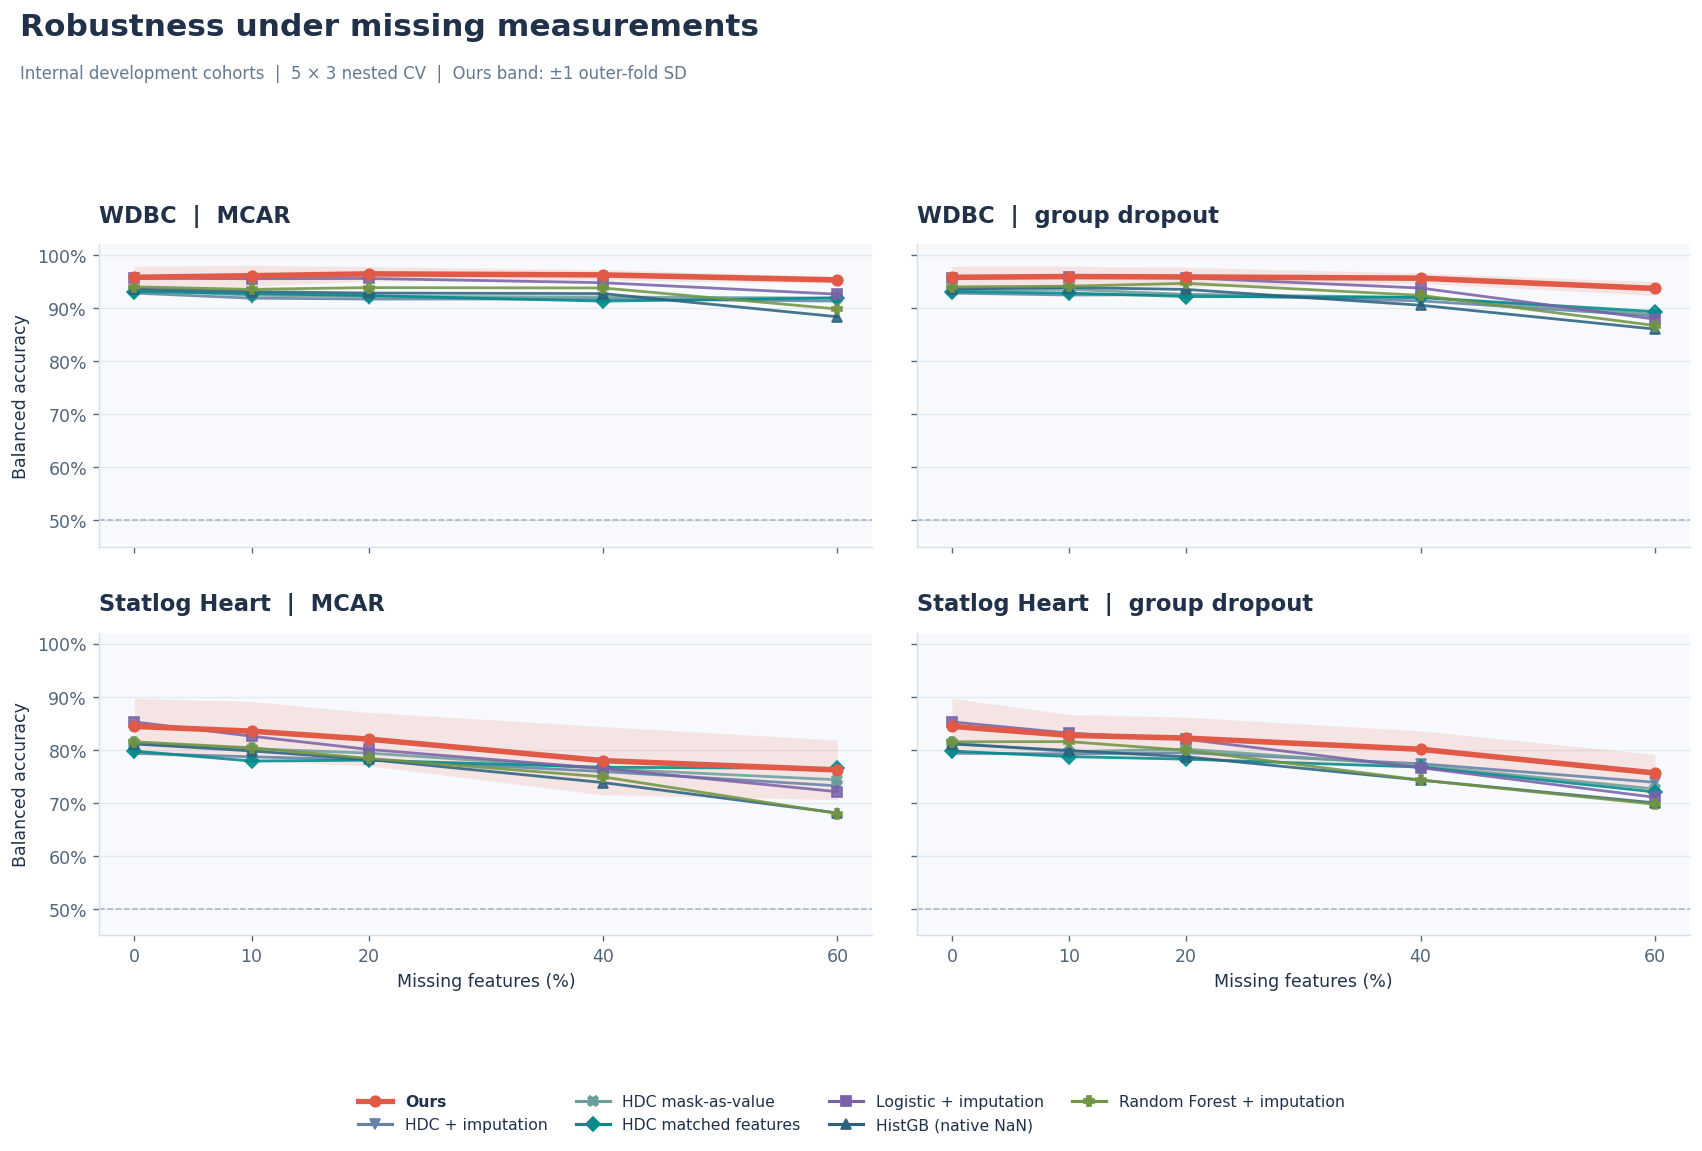

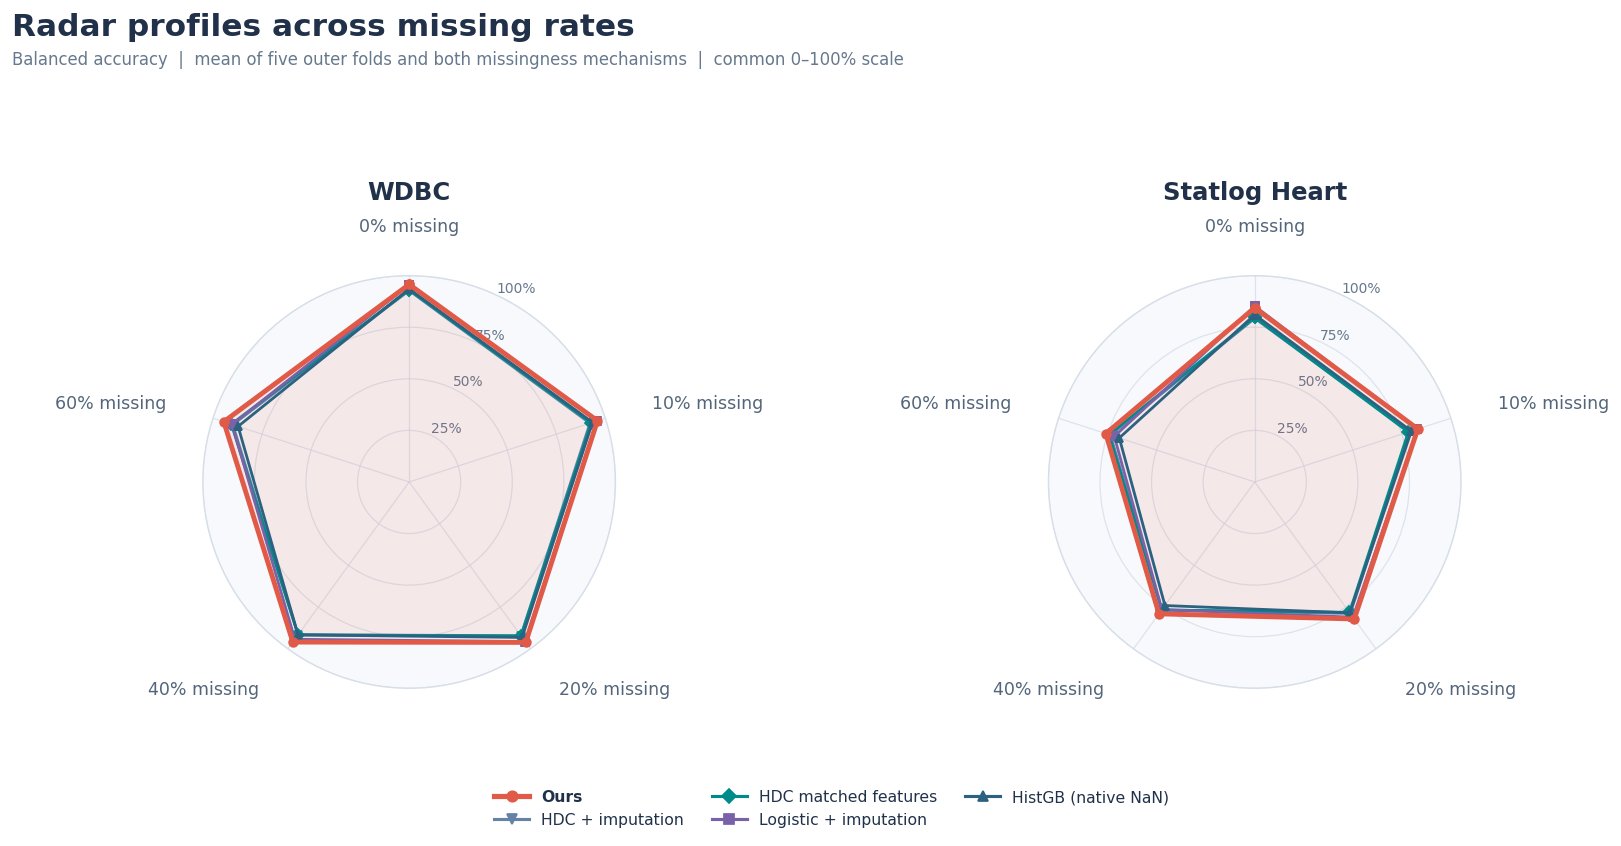

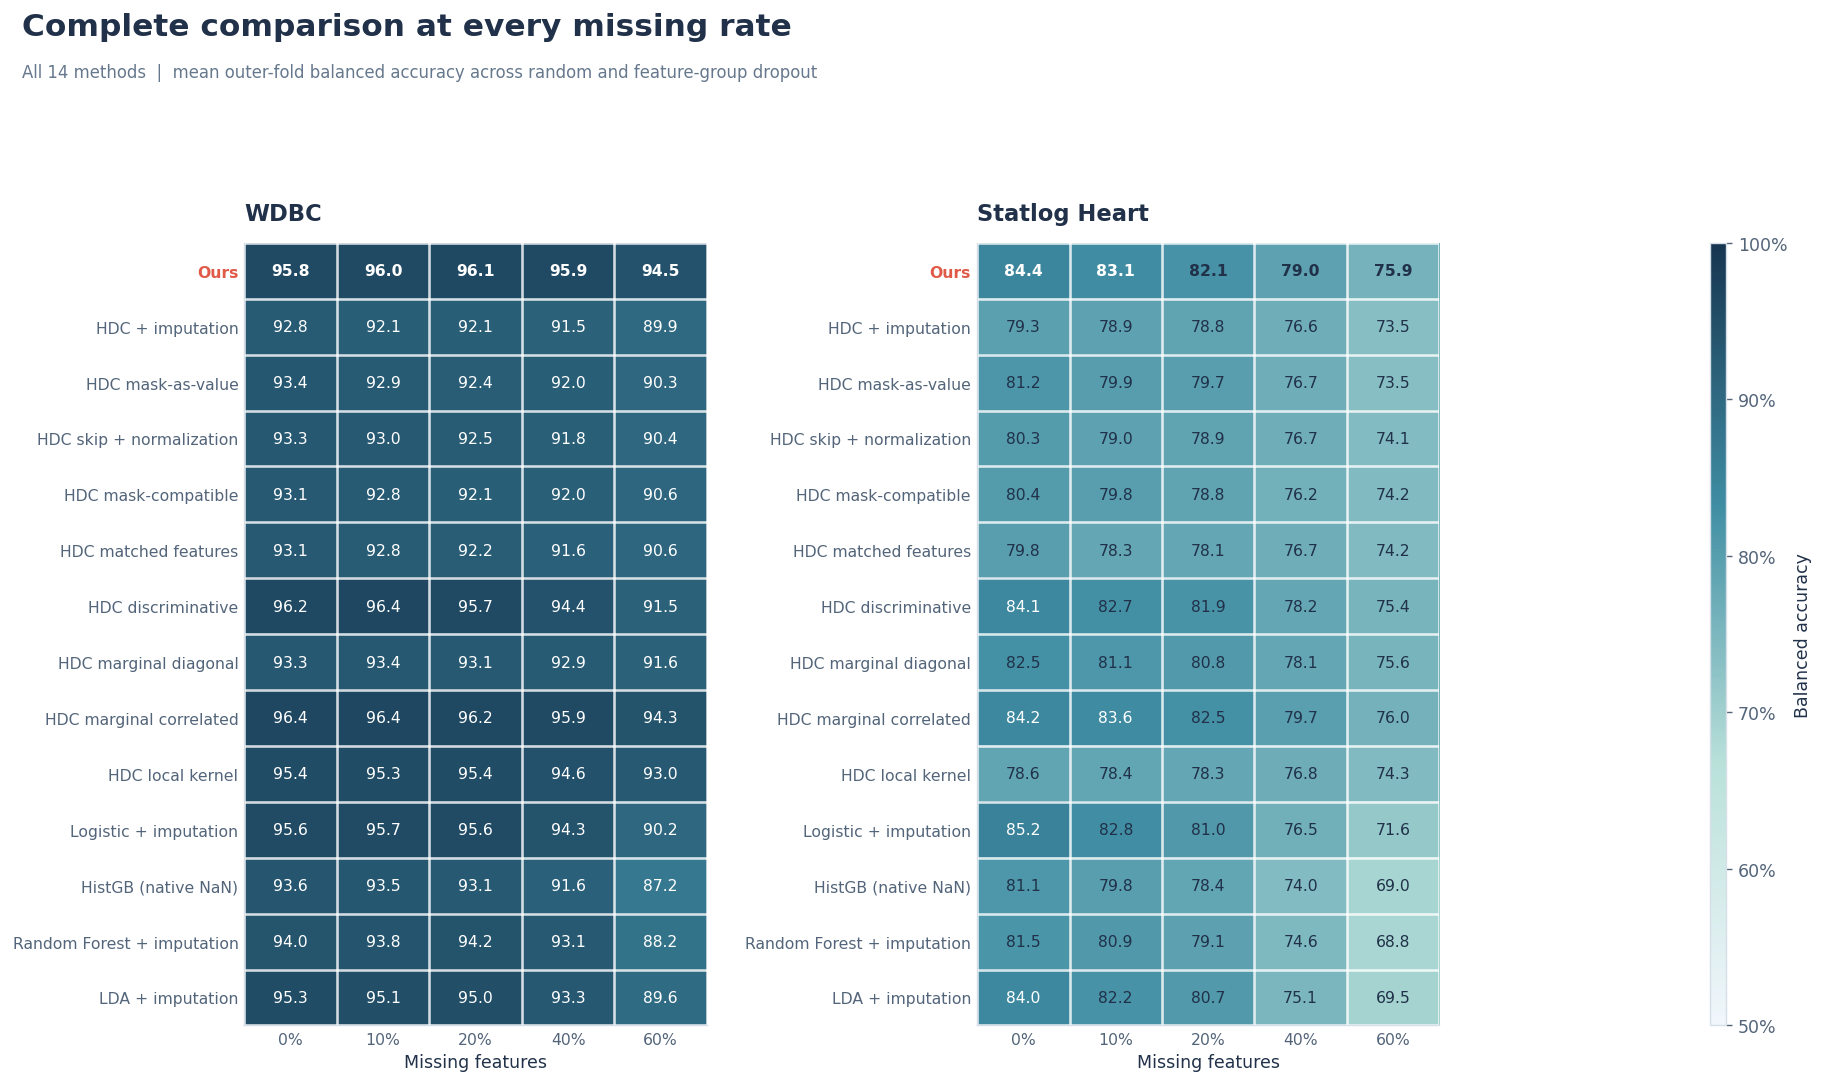

In [ ]:
# Missingness curves: five outer folds; shaded band is descriptive fold SD.
fig, axes = plt.subplots(2, 2, figsize=(14, 9.3), sharex=True, sharey=True)
for row, ds in enumerate(DATASETS):
    for column, mechanism in enumerate(MECHANISMS):
        ax = axes[row, column]
        subset = FOLD_METRICS[(FOLD_METRICS.dataset==ds.name) & (FOLD_METRICS.mechanism==mechanism)]
        for name in CORE:
            grouped = subset[subset.method==name].groupby('missing_rate').balanced_accuracy
            mean, spread = grouped.mean(), grouped.std()
            ax.plot(mean.index*100, mean, color=COLORS[name], marker=MARKERS[name],
                    linewidth=3.2 if name==MAIN else 1.6, markersize=6,
                    alpha=1 if name==MAIN else 0.87, zorder=5 if name==MAIN else 3)
            if name==MAIN:
                ax.fill_between(mean.index*100, np.maximum(mean-spread, 0), np.minimum(mean+spread, 1),
                                color=COLORS[name], alpha=0.13, linewidth=0)
        ax.axhline(0.5, color='#A7B2C1', linestyle='--', linewidth=0.9)
        ax.set_title(ds.name+'  |  '+mechanism, loc='left')
        ax.set_ylim(0.45, 1.02); ax.set_xticks(np.array(RATES)*100)
        ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.grid(axis='y')
        if column==0: ax.set_ylabel('Balanced accuracy')
        if row==1: ax.set_xlabel('Missing features (%)')
finish_figure(fig, 'Robustness under missing measurements',
              'Internal development cohorts  |  5 × 3 nested CV  |  Ours band: ±1 outer-fold SD',
              CORE, bottom=0.13, top=0.88, ncol=4)

# Equal-scale radar profiles: every spoke reports balanced accuracy at the stated missing rate.
radar_methods = [MAIN, 'HDC + imputation', 'HDC matched features', 'Logistic + imputation', 'HistGB (native NaN)']
angles = np.linspace(0, 2*np.pi, len(RATES), endpoint=False)
closed = np.r_[angles, angles[0]]
fig, axes = plt.subplots(1, 2, figsize=(13.8, 6.8), subplot_kw={'projection': 'polar'})
for ax, ds in zip(axes, DATASETS):
    for name in radar_methods:
        values = SCORECARD[(SCORECARD.dataset==ds.name) & (SCORECARD.method==name)].set_index('missing_rate').balanced_accuracy.reindex(RATES).to_numpy()
        ax.plot(closed, np.r_[values, values[0]], color=COLORS[name],
                linewidth=2.8 if name==MAIN else 1.6, marker=MARKERS[name], markersize=5,
                zorder=5 if name==MAIN else 3)
        if name==MAIN: ax.fill(closed, np.r_[values, values[0]], color=COLORS[name], alpha=0.10)
    ax.set_theta_offset(np.pi/2); ax.set_theta_direction(-1)
    ax.set_xticks(angles, [f'{rate:.0%} missing' for rate in RATES])
    ax.tick_params(axis='x', pad=18, labelsize=10)
    for label, angle in zip(ax.get_xticklabels(), angles):
        label.set_horizontalalignment('left' if np.sin(angle)>0.05 else 'right' if np.sin(angle)<-0.05 else 'center')
    ax.set_ylim(0, 1); ax.set_yticks([0.25, 0.5, 0.75, 1.0], ['25%', '50%', '75%', '100%'])
    ax.set_rlabel_position(25); ax.tick_params(axis='y', labelsize=8, colors=MUTED)
    ax.spines['polar'].set_color('#D6DEE8'); ax.grid(color='#D6DEE8')
    ax.set_title(ds.name, y=1.13, fontsize=14)
finish_figure(fig, 'Radar profiles across missing rates',
              'Balanced accuracy  |  mean of five outer folds and both missingness mechanisms  |  common 0–100% scale',
              radar_methods, bottom=0.17, top=0.87, ncol=3)

# All baselines and ablations remain visible; no test-based method filtering.
method_order = [MAIN] + [name for name in METHODS if name!=MAIN]
fig = plt.figure(figsize=(15, 9.2))
grid = fig.add_gridspec(1, 3, width_ratios=[1, 1, 0.035])
for column, ds in enumerate(DATASETS):
    frame = SCORECARD[SCORECARD.dataset==ds.name].pivot(index='method', columns='missing_rate', values='balanced_accuracy')
    frame = frame.reindex(index=method_order, columns=RATES)
    frame.columns = [f'{rate:.0%}' for rate in RATES]
    ax = fig.add_subplot(grid[0, column])
    image = annotated_heatmap(ax, frame, ds.name)
    ax.set_xlabel('Missing features')
cax = fig.add_subplot(grid[0, 2])
fig.colorbar(image, cax=cax, format=PercentFormatter(1, decimals=0), label='Balanced accuracy')
finish_figure(fig, 'Complete comparison at every missing rate',
              'All 14 methods  |  mean outer-fold balanced accuracy across random and feature-group dropout', top=0.88, bottom=0.05)


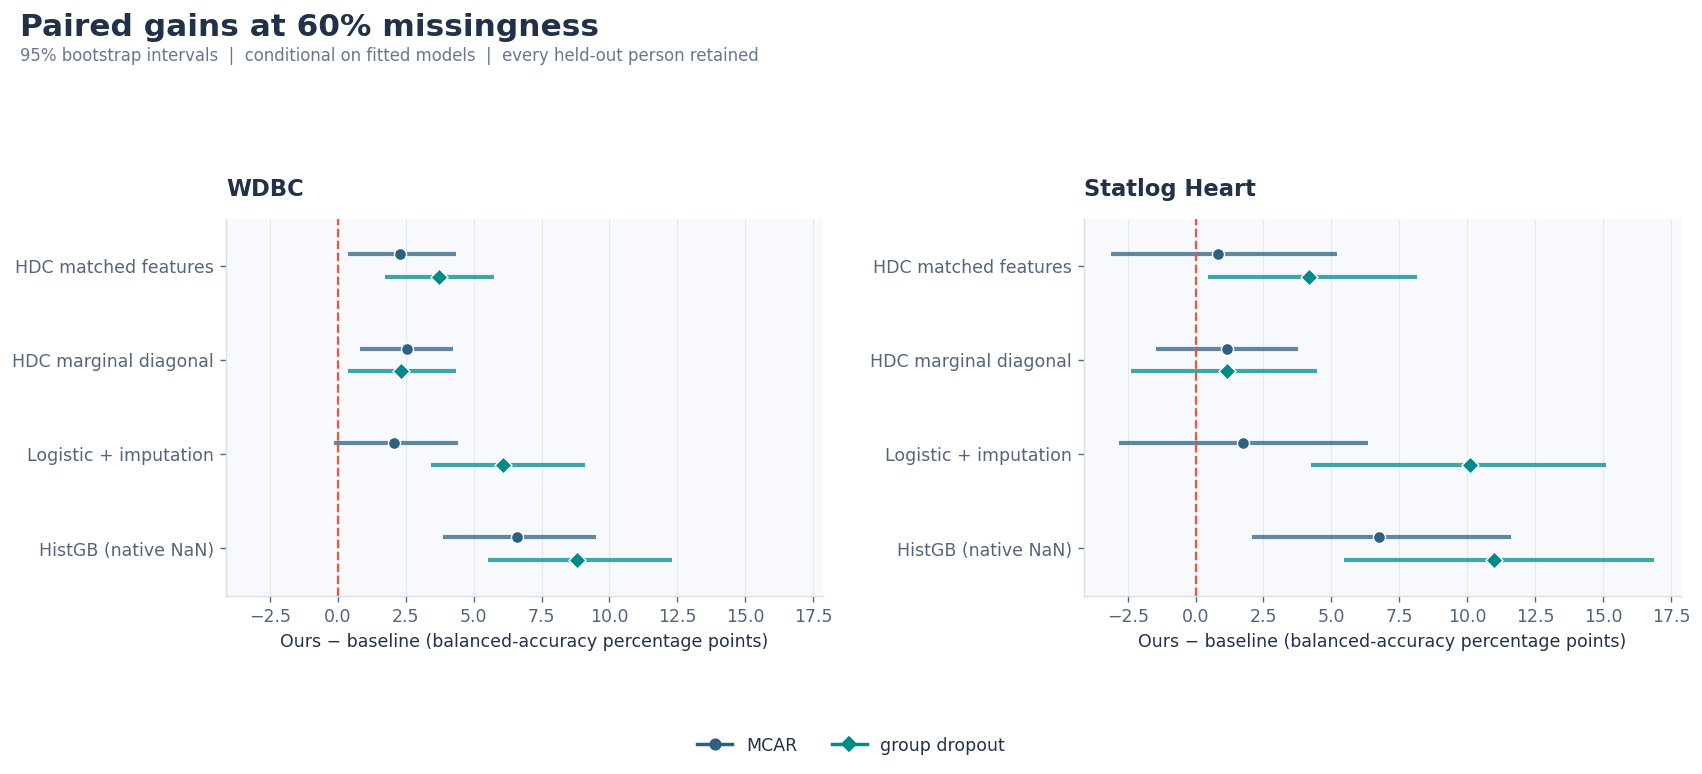

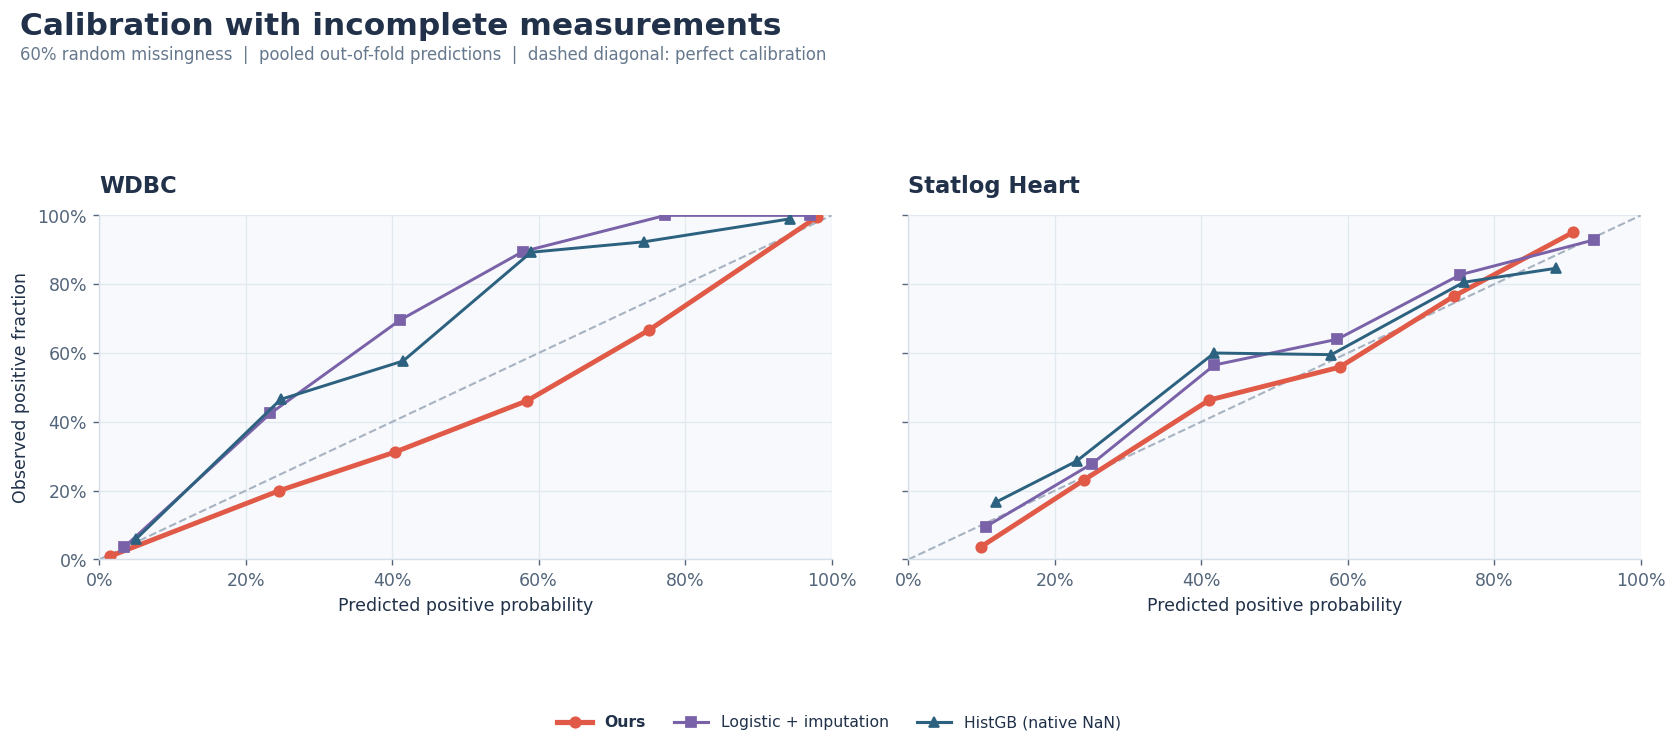

In [ ]:
# Paired person bootstrap, conditional on the fitted outer-fold models.
rng = np.random.default_rng(2026)
bootstrap_rows = []
comparison_methods = ['HDC matched features', 'HDC marginal diagonal', 'Logistic + imputation', 'HistGB (native NaN)']
for ds in DATASETS:
    for mechanism in MECHANISMS:
        main = SNAPSHOTS[(ds.name, mechanism, 0.6, MAIN)]
        people = np.unique(main['person'])
        person_indices = [np.flatnonzero(main['person']==person) for person in people]
        for name in comparison_methods:
            other = SNAPSHOTS[(ds.name, mechanism, 0.6, name)]
            assert np.array_equal(main['person'], other['person'])
            observed = fast_ba(main['y'], main['pred']) - fast_ba(other['y'], other['pred'])
            deltas = []
            for _ in range(BOOTSTRAPS):
                indices = np.concatenate([person_indices[k] for k in rng.integers(0, len(people), len(people))])
                y = main['y'][indices]
                if np.unique(y).size==2:
                    deltas.append(fast_ba(y, main['pred'][indices]) - fast_ba(y, other['pred'][indices]))
            low, high = np.quantile(deltas, [0.025, 0.975])
            bootstrap_rows.append({'dataset': ds.name, 'mechanism': mechanism, 'baseline': name,
                'people': len(people), 'BA_difference': observed, 'conditional_low': low, 'conditional_high': high})
BOOTSTRAP_RESULTS = pd.DataFrame(bootstrap_rows)
mechanism_colors = {'MCAR': '#2C617F', 'group dropout': '#008B8B'}
fig, axes = plt.subplots(1, 2, figsize=(14, 6.2), sharex=True, sharey=True)
for ax, ds in zip(axes, DATASETS):
    for offset, mechanism, marker in [(-0.12, 'MCAR', 'o'), (0.12, 'group dropout', 'D')]:
        frame = BOOTSTRAP_RESULTS[(BOOTSTRAP_RESULTS.dataset==ds.name) &
                                 (BOOTSTRAP_RESULTS.mechanism==mechanism)].set_index('baseline').reindex(comparison_methods)
        positions = np.arange(len(frame)) + offset
        ax.hlines(positions, 100*frame.conditional_low, 100*frame.conditional_high,
                  color=mechanism_colors[mechanism], linewidth=2.4, alpha=0.75)
        ax.scatter(100*frame.BA_difference, positions, color=mechanism_colors[mechanism],
                   marker=marker, s=48, edgecolors='white', linewidths=0.8, zorder=4)
    ax.axvline(0, color=COLORS[MAIN], linestyle='--', linewidth=1.3)
    ax.set_yticks(np.arange(len(comparison_methods)), comparison_methods)
    ax.set_ylim(len(comparison_methods)-0.5, -0.5)
    ax.set_title(ds.name, loc='left'); ax.grid(axis='x')
    ax.set_xlabel('Ours − baseline (balanced-accuracy percentage points)')
axes[1].tick_params(labelleft=True)
fig.legend(handles=[Line2D([0], [0], color=mechanism_colors[name], marker=marker, linewidth=2, label=name)
                    for name, marker in [('MCAR', 'o'), ('group dropout', 'D')]],
           loc='lower center', bbox_to_anchor=(0.5, 0.01), ncol=2)
finish_figure(fig, 'Paired gains at 60% missingness',
              '95% bootstrap intervals  |  conditional on fitted models  |  every held-out person retained',
              bottom=0.14, top=0.86)

fig, axes = plt.subplots(1, 2, figsize=(13.8, 6), sharex=True, sharey=True)
calibration_methods = [MAIN, 'Logistic + imputation', 'HistGB (native NaN)']
for ax, ds in zip(axes, DATASETS):
    for name in calibration_methods:
        snap = SNAPSHOTS[(ds.name, 'MCAR', 0.6, name)]
        bin_id = np.clip(np.digitize(snap['p'], np.linspace(0, 1, 7))-1, 0, 5)
        xs, ys = [], []
        for bucket in np.unique(bin_id):
            keep = bin_id==bucket
            xs.append(snap['p'][keep].mean()); ys.append(snap['y'][keep].mean())
        ax.plot(xs, ys, color=COLORS[name], marker=MARKERS[name],
                linewidth=2.8 if name==MAIN else 1.7, markersize=6)
    ax.plot([0,1], [0,1], '--', color='#A8B3C2', linewidth=1.2, zorder=1)
    ax.set_title(ds.name, loc='left'); ax.set_xlim(0,1); ax.set_ylim(0,1); ax.grid()
    ax.set_xlabel('Predicted positive probability')
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axes[0].set_ylabel('Observed positive fraction')
finish_figure(fig, 'Calibration with incomplete measurements',
              '60% random missingness  |  pooled out-of-fold predictions  |  dashed diagonal: perfect calibration',
              calibration_methods, bottom=0.16, top=0.86)


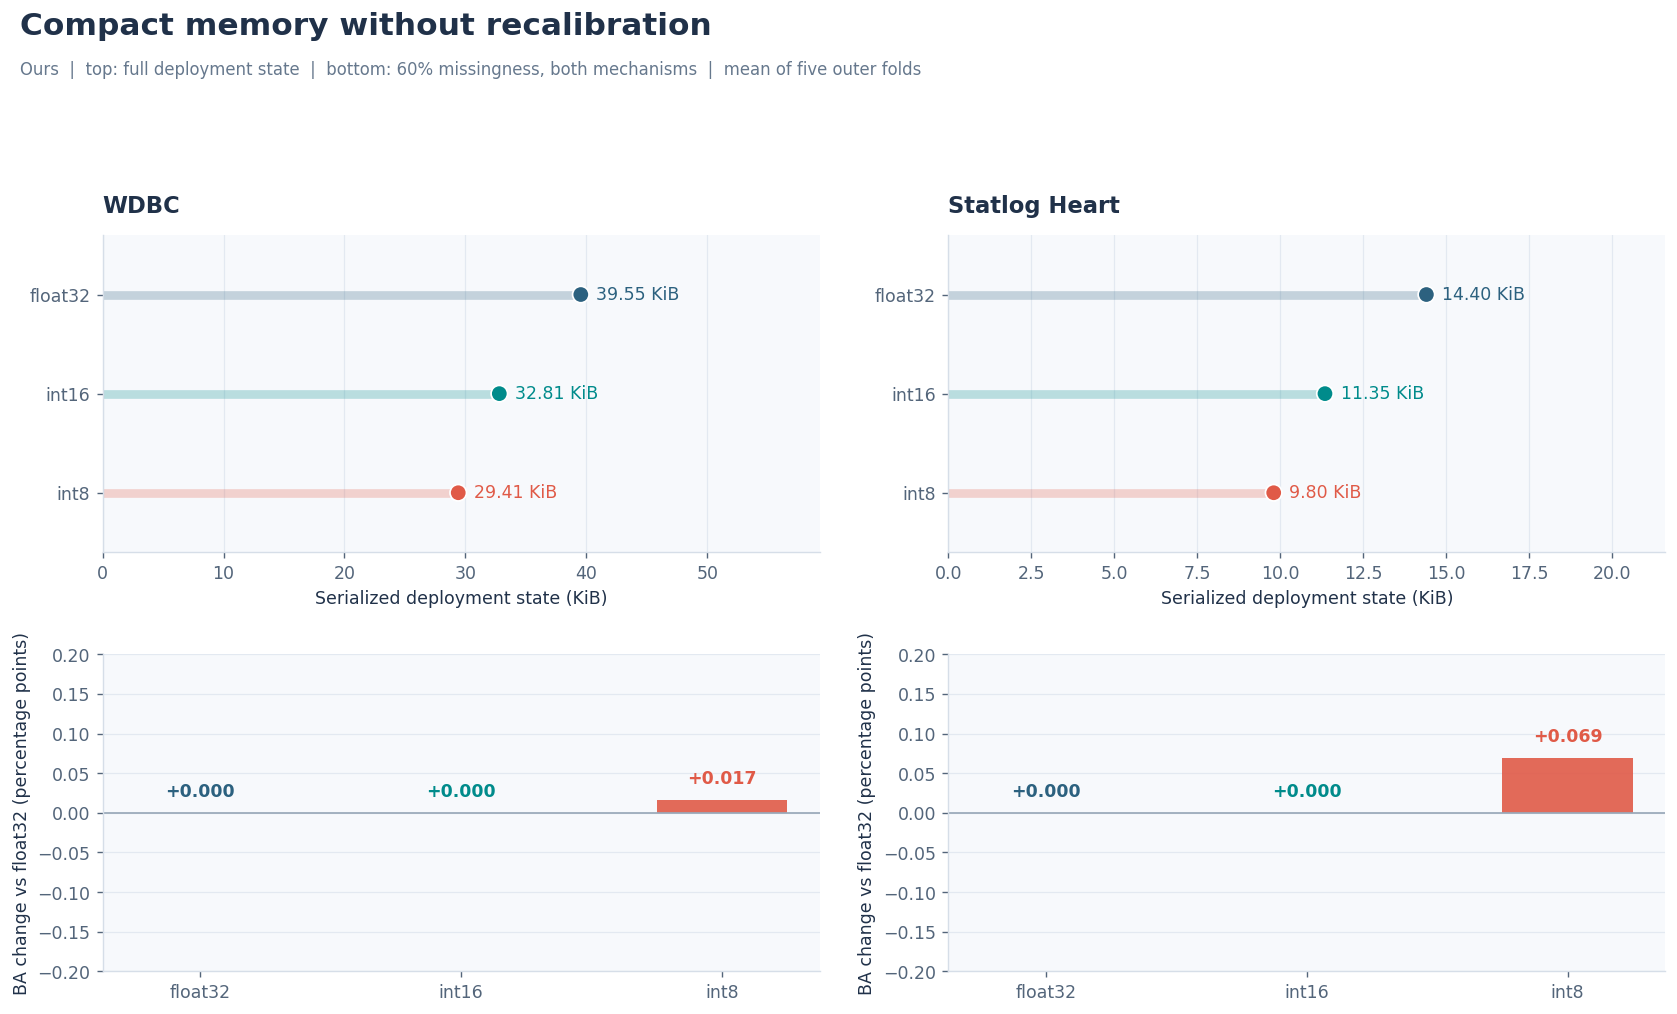

In [ ]:
def compressed_model(run,precision):
    original = run['models'][MAIN]
    result = copy.copy(original)
    result.base = original.base.compressed(precision)
    return result


# Quantize HDC lookup responses; covariance and calibration retain their reference precision.
# No refitting, recalibration, threshold changes, or test-guided format selection.
compression_rows,memory_rows = [],[]
for ds in DATASETS:
    for fold in range(OUTER_FOLDS):
        run = RUNS[(ds.name,fold)]
        original = run['models'][MAIN]
        candidates = {'float32 lookup':original,'int16 lookup':compressed_model(run,'int16'),
                      'int8 lookup':compressed_model(run,'int8')}
        for name,model in candidates.items():
            memory_rows.append({'dataset':ds.name,'fold':fold,'format':name,
                'deployment_pickle_KiB':len(pickle.dumps(model,protocol=5))/1024,
                'dense_component_reference_KiB':run['prototype'].components.nbytes/1024})
        test = run['test']
        for mechanism,rate,repeat,Xmissing,mask in masked_cases(ds.X[test],ds.groups,
                CV_SEED+4000+100*fold,MASK_REPEATS,rates=[0.0,0.6]):
            reference = original.predict_proba(Xmissing)
            for name,model in candidates.items():
                p = model.predict_proba(Xmissing)
                compression_rows.append({'dataset':ds.name,'fold':fold,'format':name,'mechanism':mechanism,
                    'missing_rate':rate,'repeat':repeat,'balanced_accuracy':fast_ba(ds.y[test],p>=model.threshold),
                    'nll':log_loss(ds.y[test],np.c_[1-p,p],labels=[0,1]),
                    'max_probability_drift':np.max(np.abs(p-reference))})
COMPRESSION = pd.DataFrame(compression_rows)
COMPRESSION_MEMORY = pd.DataFrame(memory_rows)
formats = ['float32 lookup', 'int16 lookup', 'int8 lookup']
format_colors = ['#2C617F', '#008B8B', '#E05A47']
fig, axes = plt.subplots(2, 2, figsize=(13.8, 8.6))
for column, ds in enumerate(DATASETS):
    memory = COMPRESSION_MEMORY[COMPRESSION_MEMORY.dataset==ds.name].groupby('format').deployment_pickle_KiB.mean().reindex(formats)
    accuracy = COMPRESSION[(COMPRESSION.dataset==ds.name) & (COMPRESSION.missing_rate==0.6)].groupby('format').balanced_accuracy.mean().reindex(formats)
    ax = axes[0, column]
    ax.hlines(np.arange(3), 0, memory, colors=format_colors, linewidth=5, alpha=0.25)
    ax.scatter(memory, np.arange(3), c=format_colors, s=90, edgecolors='white', zorder=3)
    for position, value in enumerate(memory):
        ax.annotate(f'{value:.2f} KiB', (value, position), xytext=(9,0), textcoords='offset points',
                    va='center', fontsize=10, color=format_colors[position])
    ax.set_yticks(np.arange(3), ['float32', 'int16', 'int8']); ax.set_ylim(2.6,-0.6)
    ax.set_xlim(0, memory.max()*1.5); ax.set_xlabel('Serialized deployment state (KiB)')
    ax.set_title(ds.name, loc='left'); ax.grid(axis='x')
    change = 100*(accuracy-accuracy.iloc[0])
    ax = axes[1, column]
    ax.bar(np.arange(3), change, color=format_colors, width=0.5, alpha=0.9)
    span = max(0.2, np.abs(change).max()*1.6)
    ax.axhline(0, color='#9AA9B9', linewidth=1)
    ax.set_ylim(-span, span)
    for position, value in enumerate(change):
        ax.text(position, value+(span*0.08 if value>=0 else -span*0.08), f'{value:+.3f}',
                ha='center', va='bottom' if value>=0 else 'top', fontsize=10,
                color=format_colors[position], weight='bold')
    ax.set_xticks(np.arange(3), ['float32', 'int16', 'int8']); ax.grid(axis='y')
    ax.set_ylabel('BA change vs float32 (percentage points)')
finish_figure(fig, 'Compact memory without recalibration',
              'Ours  |  top: full deployment state  |  bottom: 60% missingness, both mechanisms  |  mean of five outer folds',
              bottom=0.05, top=0.88)


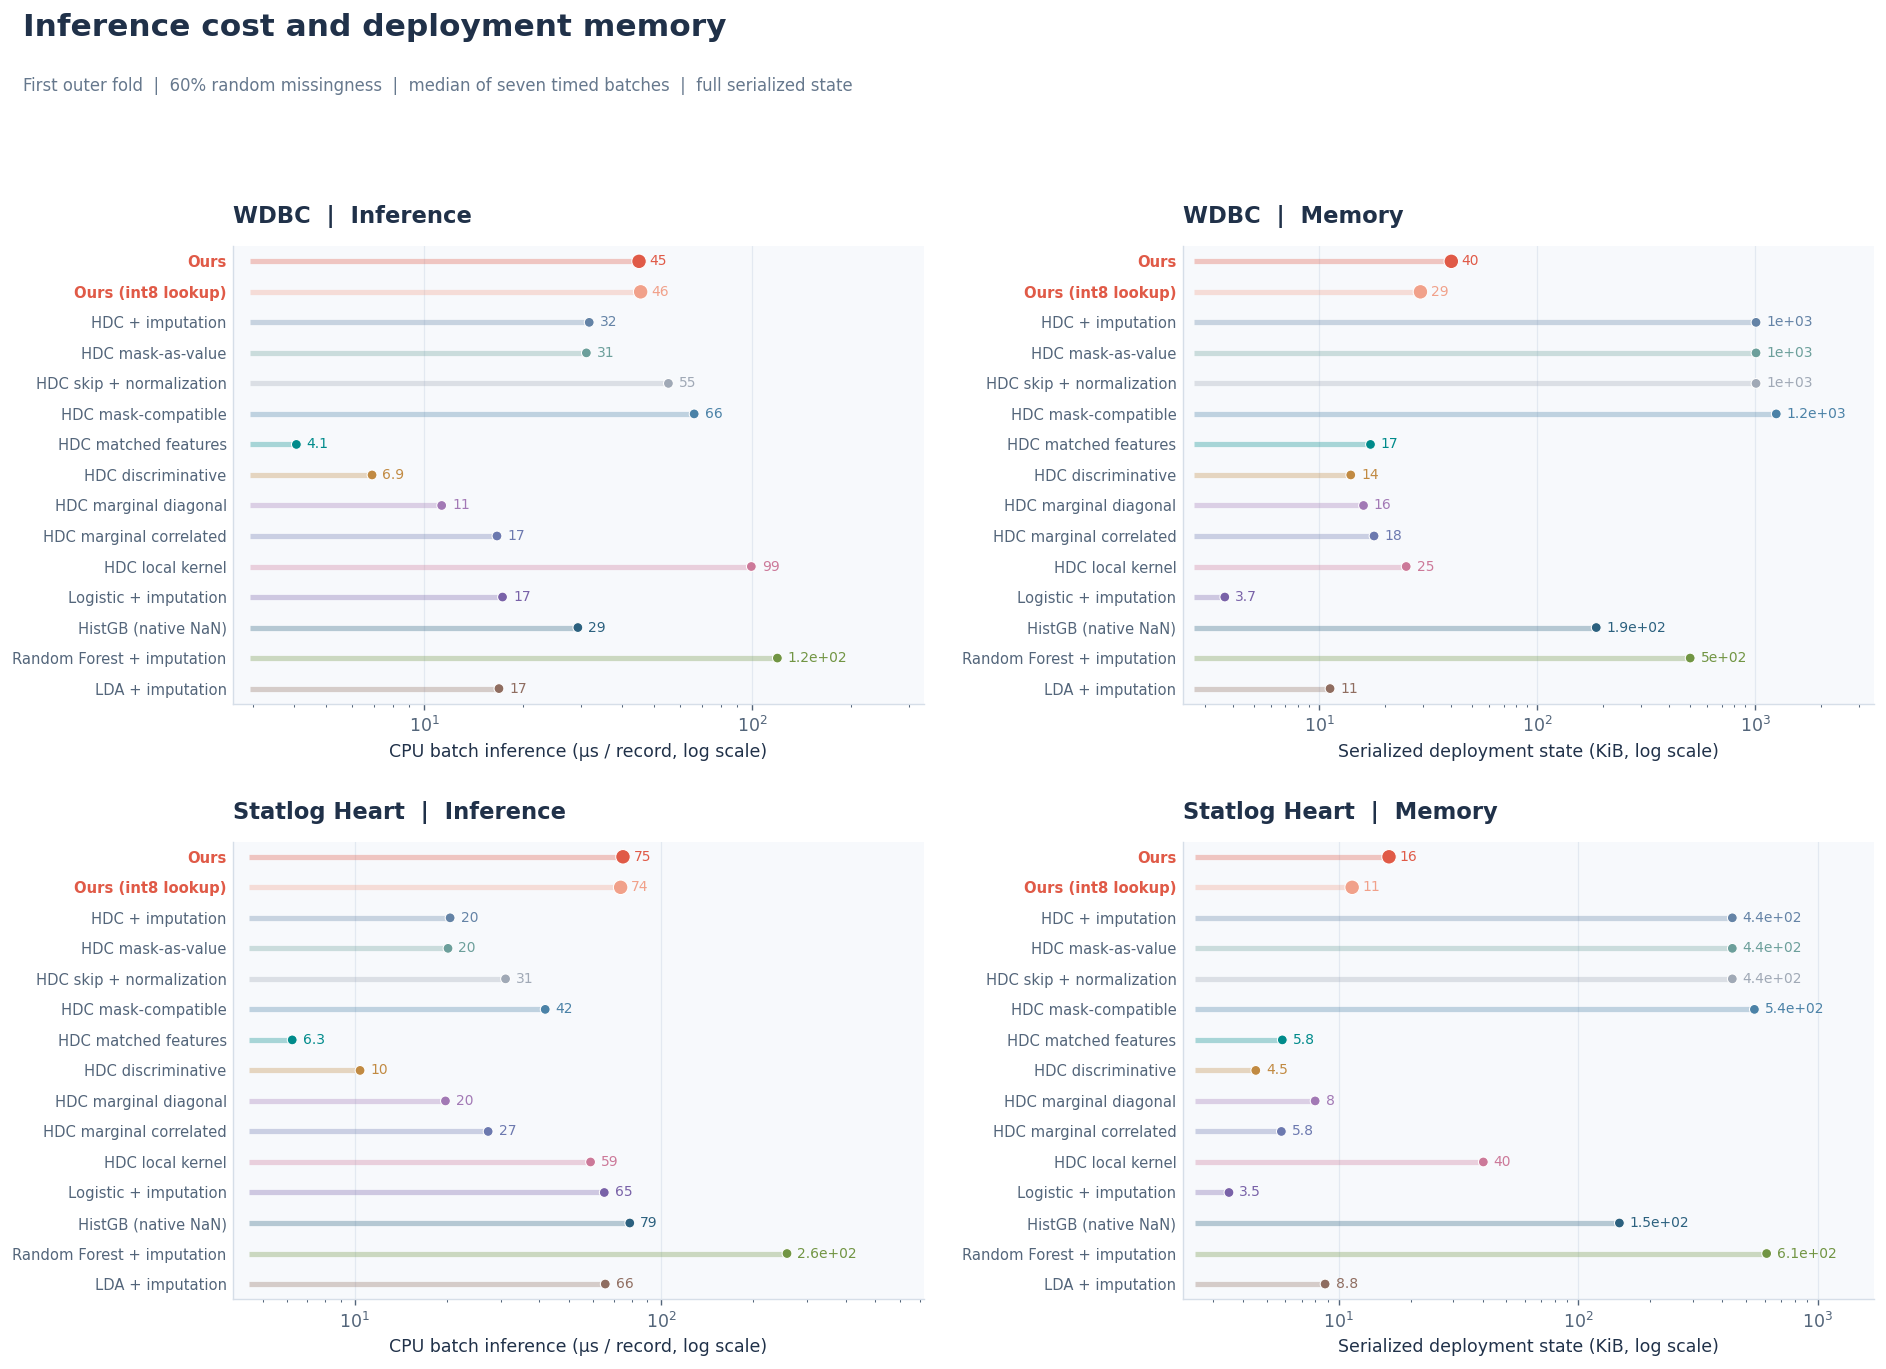

dataset,method,selected_model_fit_s
WDBC,HDC + imputation,0.1715
WDBC,HDC mask-as-value,0.1965
WDBC,HDC skip + normalization,0.1988
WDBC,HDC mask-compatible,0.1225
WDBC,HDC matched features,0.1225
WDBC,HDC discriminative,0.1345
WDBC,HDC marginal diagonal,0.1505
WDBC,HDC marginal correlated,0.1481
WDBC,HDC local kernel,0.4356
WDBC,Ours,0.1657


In [ ]:
# Deployment measurements include preprocessing and calibrated inference.
resource_rows = []
for ds in DATASETS:
    run = RUNS[(ds.name, 0)]
    test = run['test']
    Xmissing = next(c[3] for c in masked_cases(ds.X[test], ds.groups, CV_SEED+4000, rates=[0.6]) if c[0]=='MCAR')
    for name, model in run['models'].items():
        _, latency = predict_timed(model, Xmissing, 7)
        resource_rows.append({'dataset': ds.name, 'method': name,
            'selected_model_fit_s': run['fit_times'][name],
            'prediction_us_per_record': latency, 'deployment_pickle_KiB': len(pickle.dumps(model, protocol=5))/1024})
    compact = compressed_model(run, 'int8')
    _, latency = predict_timed(compact, Xmissing, 7)
    resource_rows.append({'dataset': ds.name, 'method': 'Ours (int8 lookup)',
        'selected_model_fit_s': run['fit_times'][MAIN],
        'prediction_us_per_record': latency, 'deployment_pickle_KiB': len(pickle.dumps(compact, protocol=5))/1024})
RESOURCES = pd.DataFrame(resource_rows)
resource_order = [MAIN, 'Ours (int8 lookup)'] + [name for name in METHODS if name!=MAIN]
fig, axes = plt.subplots(2, 2, figsize=(15.5, 11.5), sharey=True)
for row, ds in enumerate(DATASETS):
    frame = RESOURCES[RESOURCES.dataset==ds.name].set_index('method').reindex(resource_order)
    for column, (metric, label, title) in enumerate([
            ('prediction_us_per_record', 'CPU batch inference (µs / record, log scale)', 'Inference'),
            ('deployment_pickle_KiB', 'Serialized deployment state (KiB, log scale)', 'Memory')]):
        ax = axes[row, column]
        values = frame[metric].to_numpy()
        positions = np.arange(len(frame))
        colors = [COLORS[name] for name in frame.index]
        ax.hlines(positions, values.min()*0.72, values, colors=colors, linewidth=3, alpha=0.32)
        ax.scatter(values, positions, c=colors, s=[70 if 'Ours' in name else 32 for name in frame.index],
                   edgecolors='white', linewidths=0.6, zorder=3)
        for y, value in enumerate(values):
            ax.annotate(f'{value:.2g}', (value, y), xytext=(6,0), textcoords='offset points',
                        va='center', fontsize=8, color=colors[y])
        ax.set_yticks(positions, frame.index, fontsize=8.5)
        ax.set_ylim(len(frame)-0.5, -0.5); ax.set_xscale('log')
        ax.set_xlim(values.min()*0.64, values.max()*2.8)
        ax.set_xlabel(label); ax.set_title(ds.name+'  |  '+title, loc='left'); ax.grid(axis='x')
        ax.tick_params(axis='y', length=0, labelleft=True)
        for text in ax.get_yticklabels():
            if text.get_text().startswith('Ours'):
                text.set_fontweight('bold'); text.set_color(COLORS[MAIN])
finish_figure(fig, 'Inference cost and deployment memory',
              'First outer fold  |  60% random missingness  |  median of seven timed batches  |  full serialized state',
              bottom=0.04, top=0.90)
show_table(RESOURCES[['dataset', 'method', 'selected_model_fit_s']], height=260)


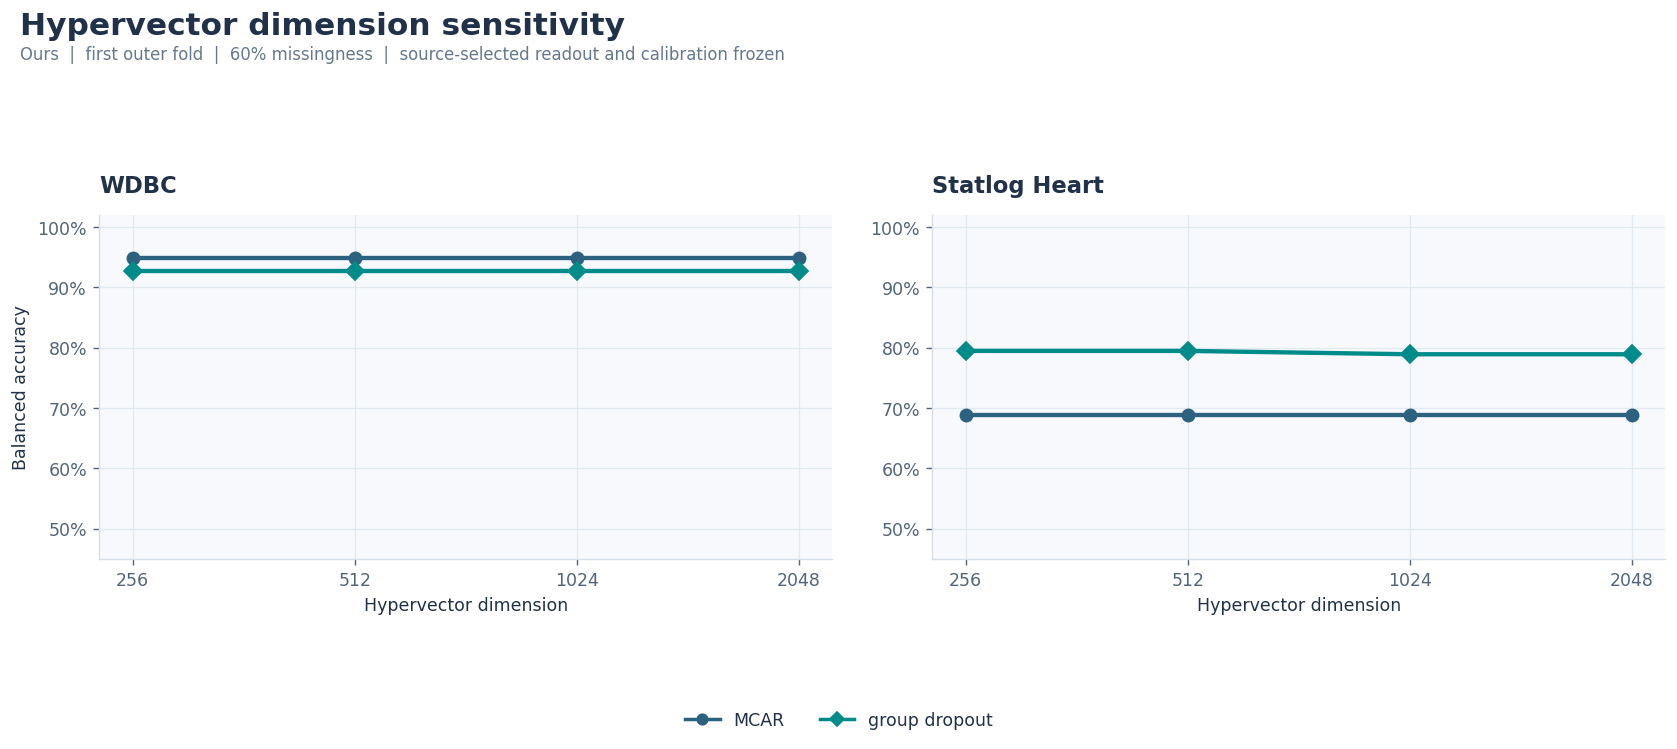

In [ ]:
# Dimension sensitivity only: selected configurations and all calibration remain frozen.
dimension_rows = []
for ds in DATASETS:
    run = RUNS[(ds.name, 0)]
    train, test = run['train'], run['test']
    reference = run['models'][MAIN]
    for dimension in [256, 512, 1024, 2048]:
        start = time.perf_counter()
        encoder = HDEncoder(Quantizer(LEVELS, ds.categorical).fit(ds.X[train]), dimension, CV_SEED)
        prototype = PrototypeHDC(encoder, ds.X[train], ds.y[train], 'compatible')
        matched = MatchedHDC(prototype)
        members = [fit_hd_candidate(CONFIGS[index], prototype, matched, ds.X[train], ds.y[train],
                                   CV_SEED, ds.groups, ds.subjects[train]) for index in run['members']]
        base = HDReadoutEnsemble(members, run['member_weights'], reference.base.transforms, reference.prior)
        model = CalibratedPredictor(base, reference.transform, reference.threshold)
        fit_seconds = time.perf_counter()-start
        for mechanism, rate, repeat, Xmissing, mask in masked_cases(
                ds.X[test], ds.groups, CV_SEED+4000, MASK_REPEATS, rates=[0.0,0.6]):
            p = model.predict_proba(Xmissing)
            dimension_rows.append({'dataset': ds.name, 'dimension': dimension, 'mechanism': mechanism,
                'missing_rate': rate, 'repeat': repeat, 'balanced_accuracy': fast_ba(ds.y[test], p>=model.threshold),
                'selected_model_fit_s': fit_seconds, 'dense_component_KiB': prototype.components.nbytes/1024,
                'deployment_pickle_KiB': len(pickle.dumps(model, protocol=5))/1024})
DIMENSIONS = pd.DataFrame(dimension_rows)
fig, axes = plt.subplots(1, 2, figsize=(13.8, 6))
for ax, ds in zip(axes, DATASETS):
    frame = DIMENSIONS[(DIMENSIONS.dataset==ds.name) & (DIMENSIONS.missing_rate==0.6)]
    for mechanism, marker in [('MCAR', 'o'), ('group dropout', 'D')]:
        line = frame[frame.mechanism==mechanism].groupby('dimension').balanced_accuracy.mean()
        ax.plot(line.index, line, color=mechanism_colors[mechanism], marker=marker, linewidth=2.5, markersize=7)
    ax.set_xscale('log', base=2); ax.set_xticks([256,512,1024,2048], ['256','512','1024','2048'])
    ax.set_title(ds.name, loc='left'); ax.set_xlabel('Hypervector dimension'); ax.grid()
    ax.set_ylim(0.45,1.02); ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axes[0].set_ylabel('Balanced accuracy')
fig.legend(handles=[Line2D([0], [0], color=mechanism_colors[name], marker=marker, linewidth=2, label=name)
                    for name, marker in [('MCAR', 'o'), ('group dropout', 'D')]],
           loc='lower center', bbox_to_anchor=(0.5, 0.01), ncol=2)
finish_figure(fig, 'Hypervector dimension sensitivity',
              'Ours  |  first outer fold  |  60% missingness  |  source-selected readout and calibration frozen',
              bottom=0.16, top=0.86)


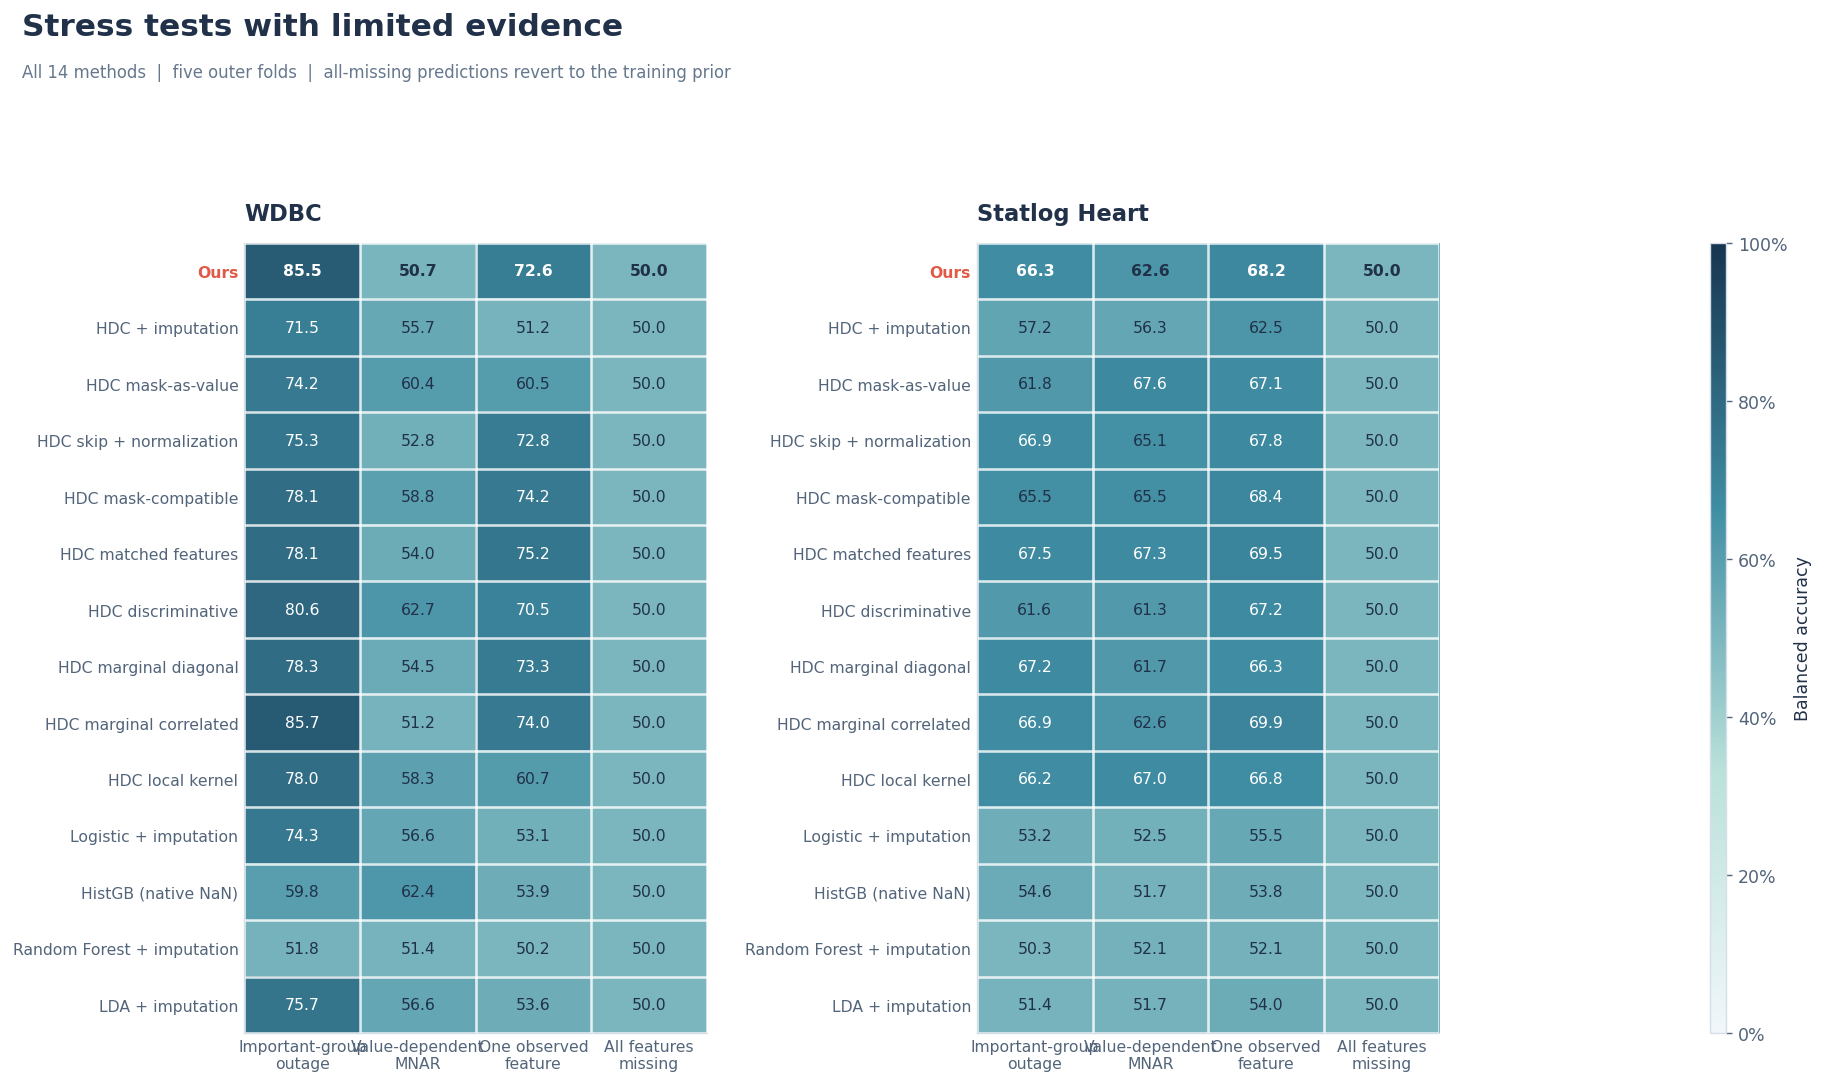

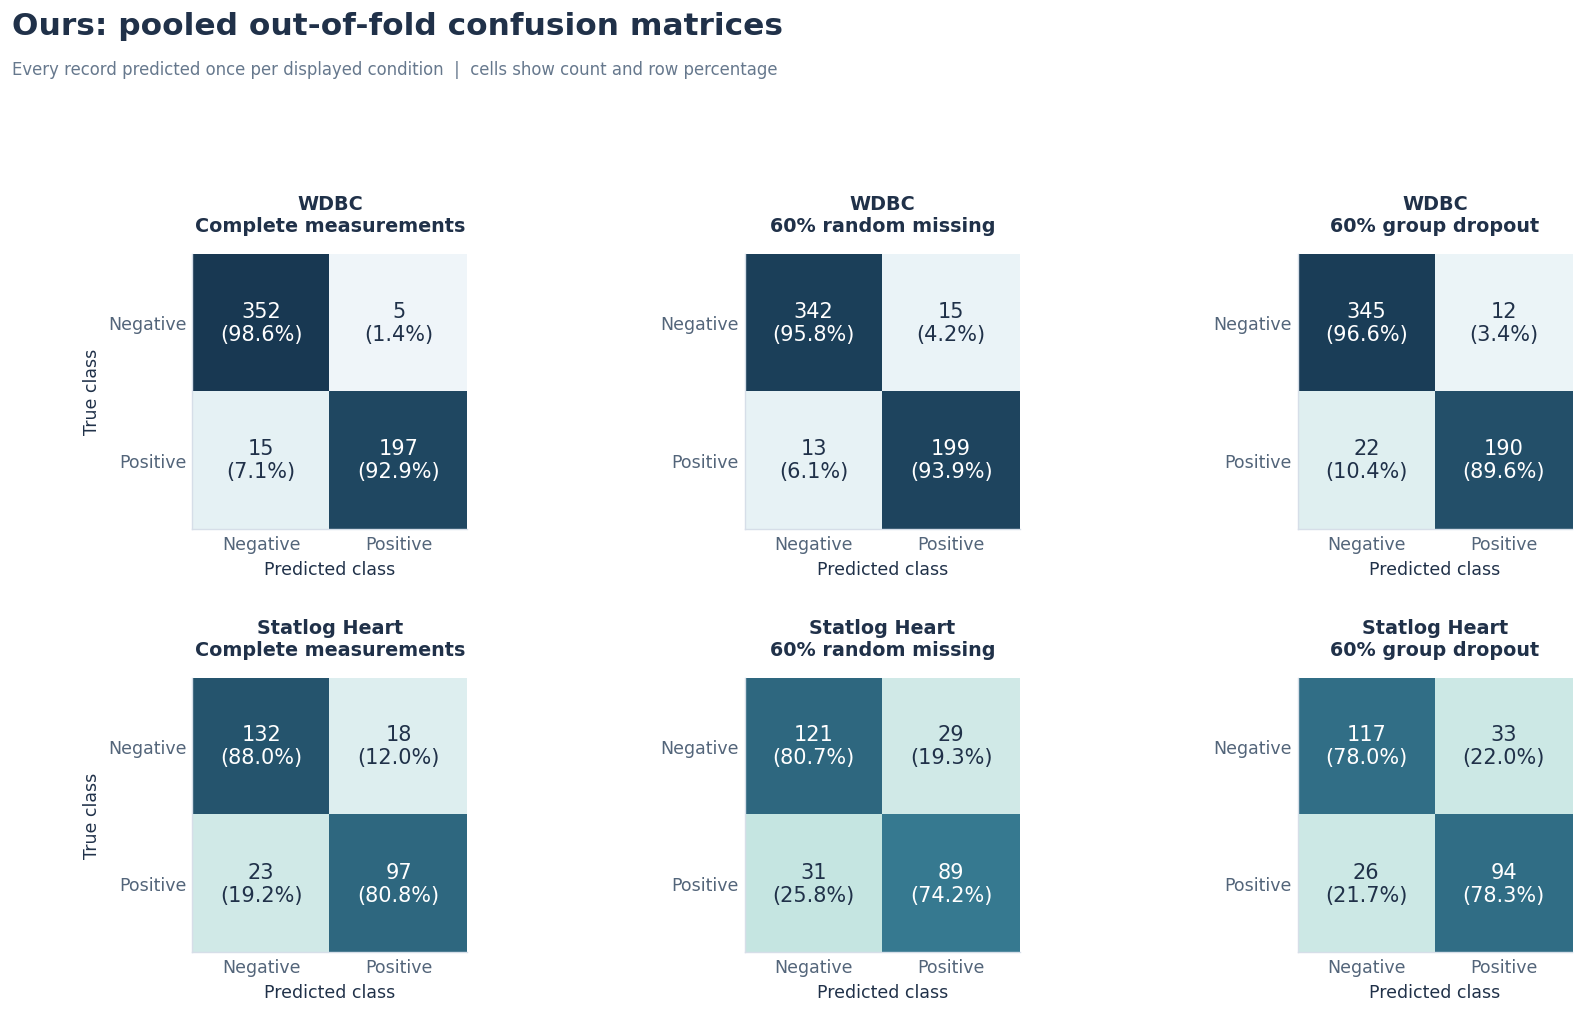

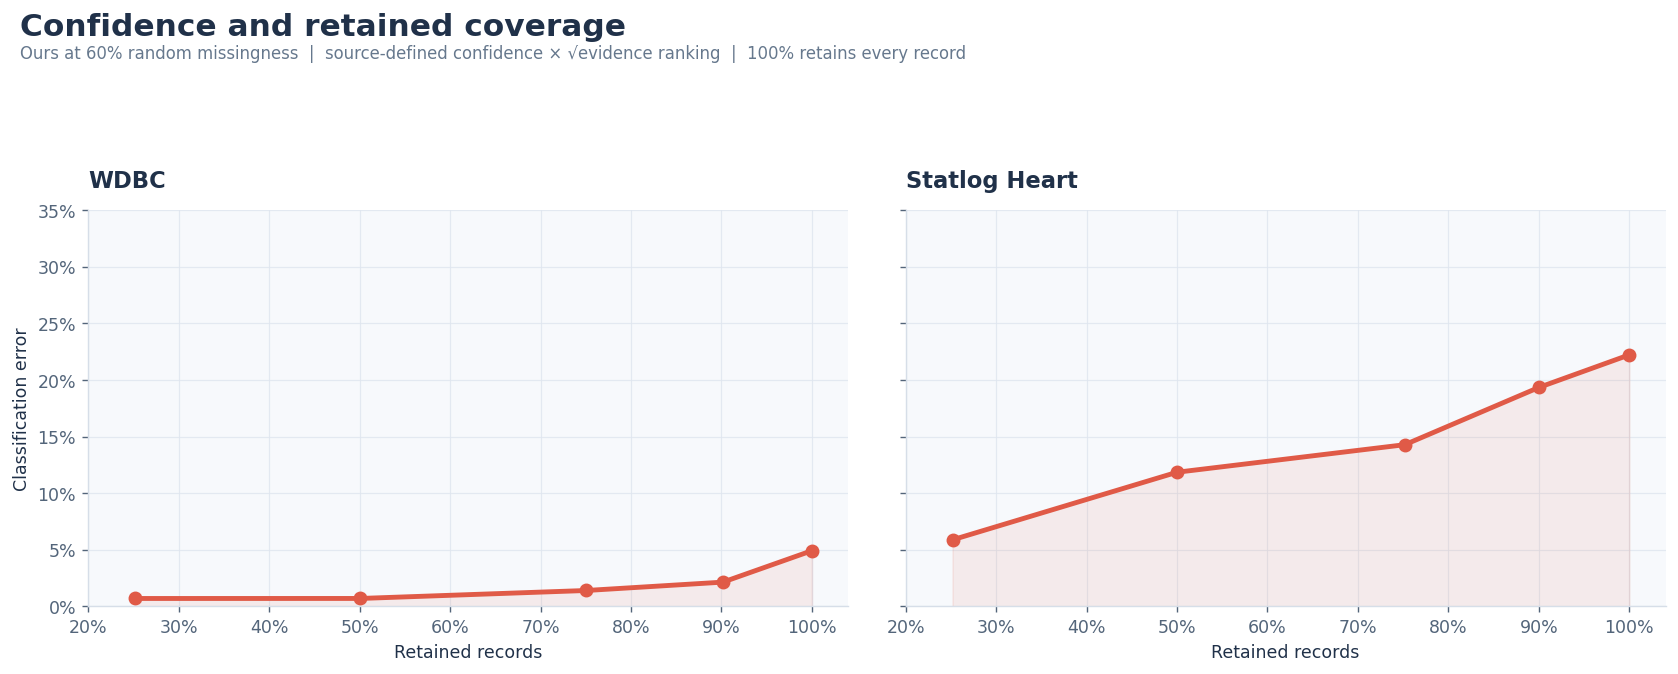

In [ ]:
# Additional held-out stresses; primary metrics always include every test record.
stress_rows,coverage_rows = [],[]
for ds in DATASETS:
    for fold in range(OUTER_FOLDS):
        run = RUNS[(ds.name,fold)]
        train,test = run['train'],run['test']
        X,y = ds.X[test],ds.y[test]
        importance = run['models'][MAIN].base.evidence_weights
        order = np.argsort(np.bincount(ds.groups,weights=importance))[::-1]
        selected,dropped = [],0
        for group in order:
            if dropped >= np.ceil(0.6*X.shape[1]): break
            selected.append(group); dropped += np.sum(ds.groups==group)
        rng = np.random.default_rng(CV_SEED+9000+fold)
        one = np.zeros_like(X,dtype=bool)
        one[np.arange(len(X)),rng.integers(0,X.shape[1],len(X))] = True
        cases = {'shared important-group outage':np.broadcast_to(~np.isin(ds.groups,selected),X.shape),
                 'value-dependent MNAR':X<=np.quantile(ds.X[train],0.4,axis=0),
                 'one observed feature':one,'all features missing':np.zeros_like(X,dtype=bool)}
        for case,mask in cases.items():
            Xmissing = np.where(mask,X,np.nan)
            for name,model in run['models'].items():
                p = model.predict_proba(Xmissing)
                if case=='all features missing':
                    assert np.allclose(p,model.prior)
                stress_rows.append({'dataset':ds.name,'fold':fold,'stress':case,'method':name,
                    'realized_missing':1-mask.mean(),
                    'abstained_fraction':np.mean(model.predict_with_abstention(Xmissing)==-1),
                    **metrics(y,p,model.threshold)})
    snap = SNAPSHOTS[(ds.name,'MCAR',0.6,MAIN)]
    confidence = np.maximum(snap['p'],1-snap['p'])*np.sqrt(snap['evidence'])
    for coverage in [1.,0.9,0.75,0.5,0.25]:
        k = max(1,int(np.ceil(coverage*len(confidence))))
        keep = np.argsort(-confidence,kind='stable')[:k]
        coverage_rows.append({'dataset':ds.name,'coverage':k/len(confidence),
            'error_rate':np.mean(snap['pred'][keep]!=snap['y'][keep]),
            'mean_evidence':snap['evidence'][keep].mean(),'records':len(keep)})
STRESS = pd.DataFrame(stress_rows)
COVERAGE = pd.DataFrame(coverage_rows)
# Full stress matrix: all baselines and all outer-fold test records.
stress_order = ['shared important-group outage', 'value-dependent MNAR',
                'one observed feature', 'all features missing']
stress_labels = ['Important-group\noutage', 'Value-dependent\nMNAR', 'One observed\nfeature', 'All features\nmissing']
fig = plt.figure(figsize=(15, 9.2))
grid = fig.add_gridspec(1, 3, width_ratios=[1,1,0.035])
for column, ds in enumerate(DATASETS):
    frame = STRESS[STRESS.dataset==ds.name].groupby(['method','stress']).balanced_accuracy.mean().unstack()
    frame = frame.reindex(index=method_order, columns=stress_order)
    frame.columns = stress_labels
    image = annotated_heatmap(fig.add_subplot(grid[0,column]), frame, ds.name, vmin=0, vmax=1)
cax = fig.add_subplot(grid[0,2])
fig.colorbar(image, cax=cax, format=PercentFormatter(1, decimals=0), label='Balanced accuracy')
finish_figure(fig, 'Stress tests with limited evidence',
              'All 14 methods  |  five outer folds  |  all-missing predictions revert to the training prior',
              bottom=0.05, top=0.88)

fig, axes = plt.subplots(2, 3, figsize=(13.8, 8.6))
for row, ds in enumerate(DATASETS):
    for column, (mechanism, rate) in enumerate([('MCAR',0.), ('MCAR',0.6), ('group dropout',0.6)]):
        snap = SNAPSHOTS[(ds.name, mechanism, rate, MAIN)]
        counts = confusion_matrix(snap['y'], snap['pred'], labels=[0,1])
        fractions = counts / np.maximum(counts.sum(axis=1, keepdims=True), 1)
        ax = axes[row, column]
        ax.imshow(fractions, cmap=HEAT_CMAP, vmin=0, vmax=1)
        for (a,b), value in np.ndenumerate(counts):
            ax.text(b, a, f'{value}\n({fractions[a,b]:.1%})', ha='center', va='center',
                    fontsize=12, color='white' if fractions[a,b]>0.7 else INK)
        condition = 'Complete measurements' if rate==0 else ('60% random missing' if mechanism=='MCAR' else '60% group dropout')
        ax.set_title(ds.name+'\n'+condition, fontsize=11)
        ax.set_xticks([0,1], ['Negative','Positive'])
        ax.set_yticks([0,1], ['Negative','Positive'])
        ax.tick_params(length=0)
        ax.set_xlabel('Predicted class')
        if column==0: ax.set_ylabel('True class')
finish_figure(fig, 'Ours: pooled out-of-fold confusion matrices',
              'Every record predicted once per displayed condition  |  cells show count and row percentage',
              bottom=0.05, top=0.88)

fig, axes = plt.subplots(1, 2, figsize=(13.8, 5.7), sharey=True)
for ax, ds in zip(axes, DATASETS):
    frame = COVERAGE[COVERAGE.dataset==ds.name].sort_values('coverage')
    ax.plot(frame.coverage, frame.error_rate, 'o-', color=COLORS[MAIN], linewidth=2.8, markersize=7)
    ax.fill_between(frame.coverage, 0, frame.error_rate, color=COLORS[MAIN], alpha=0.09)
    ax.set_title(ds.name, loc='left'); ax.set_xlim(0.2,1.04); ax.set_ylim(0,0.35)
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_xlabel('Retained records'); ax.grid()
axes[0].set_ylabel('Classification error')
finish_figure(fig, 'Confidence and retained coverage',
              'Ours at 60% random missingness  |  source-defined confidence × √evidence ranking  |  100% retains every record',
              bottom=0.05, top=0.86)


In [ ]:
# All results stay in memory and appear inline; no result archives or output folders.
assert MAIN=='Ours'
assert [ds.name for ds in DATASETS]==['WDBC', 'Statlog Heart']
assert RESULTS.dataset.nunique()==2
assert all(np.allclose(run['models'][MAIN].base.weights.sum(), 1) for run in RUNS.values())
show_table(SCORECARD[(SCORECARD.method==MAIN) & SCORECARD.missing_rate.isin([0.,0.6])])
print('PASS | 2 datasets |', OUTER_FOLDS, 'outer folds |', INNER_FOLDS, 'inner folds |', len(METHODS), 'methods')
print('Scope: WDBC and Statlog Heart; internal development evaluation.')
print('Results: SCORECARD, RESULTS, SUMMARY, POOLED, SELECTIONS, BOOTSTRAP_RESULTS,')
print('         COMPRESSION, COMPRESSION_MEMORY, RESOURCES, DIMENSIONS, STRESS, COVERAGE.')


dataset,method,missing_rate,balanced_accuracy,roc_auc,f1,sensitivity,specificity,nll,brier
Statlog Heart,Ours,0.0000,0.8442,0.9125,0.8256,0.8083,0.8800,0.3678,0.1138
Statlog Heart,Ours,0.6000,0.7590,0.8499,0.7347,0.7514,0.7667,0.4767,0.1556
WDBC,Ours,0.0000,0.9578,0.9956,0.9515,0.9296,0.9860,0.0799,0.0230
WDBC,Ours,0.6000,0.9447,0.9884,0.9309,0.9287,0.9608,0.1322,0.0383


PASS | 2 datasets | 5 outer folds | 3 inner folds | 14 methods
Scope: WDBC and Statlog Heart; internal development evaluation.
Results: SCORECARD, RESULTS, SUMMARY, POOLED, SELECTIONS, BOOTSTRAP_RESULTS,
         COMPRESSION, COMPRESSION_MEMORY, RESOURCES, DIMENSIONS, STRESS, COVERAGE.


In [ ]:
# Supplementary internal analyses; WDBC and Statlog Heart were selected after development.
import types, platform
from scipy.optimize import brentq
from scipy.stats import t as student_t
from sklearn.impute import KNNImputer, MissingIndicator
from sklearn.pipeline import FeatureUnion
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats('png', 'svg')

EXPERIMENT_PROTOCOL = {
    'seed': 20261102, 'cohorts': ['WDBC', 'Statlog Heart'],
    'status': 'Supplementary internal development analyses; no independent validation claim',
    'dense_rates': np.round(np.arange(0, 0.901, 0.05), 2).tolist(),
    'dense_repeats': 3, 'dense_mechanisms': ['MCAR', 'MAR', 'MNAR', 'persistent outage'],
    'new_cv_seeds': [20261119, 20261129], 'learning_fractions': [0.25, 0.5, 0.75, 1.0],
    'source_missing_rates': [0.0, 0.2, 0.4], 'group_random_orders': 16,
    'curve_bootstraps': 400, 'batch_sizes': [1, 4, 16, 64, 256, 1024],
    'primary_statistic': 'BA gain at 60% missingness, averaged over both original mechanisms',
    'secondary_statistic': 'Brier improvement under the same conditions',
    'inference': 'Two-sided corrected resampled t approximations; Holm over all 16 comparisons',
    'selection': 'Inner OOF only; no new target calibration, thresholds, or outcome-based filtering'}
EXPERIMENT_PROTOCOL_SHA256 = hashlib.sha256(json.dumps(EXPERIMENT_PROTOCOL, sort_keys=True).encode()).hexdigest()
ORIGINAL_RESULTS_SHA256 = hashlib.sha256(pd.util.hash_pandas_object(RESULTS, index=True).values.tobytes()).hexdigest()
ORIGINAL_MODEL_HASHES = {key: hashlib.sha256(pickle.dumps(run['models'][MAIN], protocol=5)).hexdigest()
                         for key, run in RUNS.items()}
ORIGINAL_DATA_HASHES = {ds.name: hashlib.sha256(ds.X.tobytes()+ds.y.tobytes()).hexdigest() for ds in DATASETS}
EXTRA_METHODS = [MAIN, 'HDC matched features', 'HDC + imputation',
                 'Logistic + imputation', 'HistGB (native NaN)', 'Random Forest + imputation']
CONTROL_NAMES = ['Logistic + KNN imputation', 'Mask-augmented logistic', 'Mask-augmented HistGB']
EXTRA_COLORS = dict(COLORS, **{'Logistic + KNN imputation': '#B38837',
    'Mask-augmented logistic': '#905BB3', 'Mask-augmented HistGB': '#35817A'})
EXPERIMENT_LOG = []
NEW_FIGURES = []
plt.rcParams.update({'axes.facecolor': 'white', 'figure.dpi': 145, 'axes.titlesize': 11,
                     'axes.titleweight': 'normal', 'grid.alpha': 0.5, 'axes.labelsize': 10})


def seeded_suite(ds, train, test, fold, seed=CV_SEED):
    # Give the unchanged fitting routine its own seed without changing notebook globals.
    function = types.FunctionType(fit_suite.__code__, dict(fit_suite.__globals__, CV_SEED=int(seed)))
    return function(ds, train, test, fold)


def dataset_with_X(ds, X):
    return Dataset(ds.name, X, ds.y.copy(), list(ds.feature_names), ds.groups.copy(),
                   list(ds.group_names), ds.categorical, ds.subjects.copy())


def new_figure(fig, title, note, names=(), ncol=3):
    fig.suptitle(title, x=0.06, y=0.995, ha='left', fontsize=16, weight='bold')
    fig.text(0.06, 0.95, note, ha='left', va='top', fontsize=8.5, color=MUTED)
    for letter, ax in zip('abcdefghijklmnopqrstuvwxyz', fig.axes):
        ax.set_facecolor('white')
        ax.text(-0.08, 1.055, letter, transform=ax.transAxes, weight='bold', fontsize=11)
        ax.grid(alpha=0.35, linewidth=0.6)
        ax.tick_params(labelsize=9)
    bottom = 0.17 if names else 0.07
    fig.tight_layout(rect=[0.015, bottom, 0.99, 0.88], h_pad=2.0, w_pad=2.1)
    if names:
        handles = [Line2D([0], [0], color=EXTRA_COLORS[name], linewidth=2.8 if name==MAIN else 1.6,
                          label=name) for name in names]
        fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, 0.015), ncol=ncol,
                   fontsize=8.5, columnspacing=1.6)
    NEW_FIGURES.append(title)
    plt.show()


def draw_fold_curve(ax, frame, x, names, metric='balanced_accuracy'):
    for name in names:
        by_fold = frame[frame.method==name].groupby(['fold', x], as_index=False)[metric].mean()
        grouped = by_fold.groupby(x)[metric]
        mean, spread = grouped.mean(), grouped.std().fillna(0)
        ax.plot(mean.index, mean, color=EXTRA_COLORS[name], linewidth=2.6 if name==MAIN else 1.5,
                linestyle='-' if name==MAIN else '--', zorder=5 if name==MAIN else 3)
        if name==MAIN:
            ax.fill_between(mean.index, np.maximum(mean-spread, 0), np.minimum(mean+spread, 1),
                            color=EXTRA_COLORS[name], alpha=0.12, linewidth=0)
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))


def log_run(experiment, ds, fold, run, training_records=None):
    train, test = run['train'], run['test']
    assert not set(ds.subjects[train]) & set(ds.subjects[test])
    EXPERIMENT_LOG.append({'experiment': experiment, 'dataset': ds.name, 'fold': fold,
        'train_records': len(train) if training_records is None else training_records,
        'test_records': len(test), 'source_only': True, 'fit_seconds': run['total_fit_s']})


def append_evaluation(rows, ds, run, models, seed, metadata, rates=(0., 0.6)):
    test = run['test']
    for mechanism, rate, repeat, X, mask in masked_cases(ds.X[test], ds.groups, seed, MASK_REPEATS, rates=rates):
        for name, model in models.items():
            p = model.predict_proba(X)
            rows.append(dict(dataset=ds.name, fold=run['fold'], method=name, mechanism=mechanism,
                missing_rate=rate, repeat=repeat, realized_missing=1-mask.mean(), all_missing=(~mask.any(axis=1)).mean(),
                **metadata, **metrics(ds.y[test], p, model.threshold)))


def dense_cases(train_X, test_X, seed):
    # MAR: the first measurement remains observed. MNAR uses latent clean values only to simulate masks.
    center = np.median(train_X, axis=0)
    scale = np.quantile(train_X, 0.75, axis=0)-np.quantile(train_X, 0.25, axis=0)
    scale = np.maximum(scale, np.maximum(np.std(train_X, axis=0), 1.)*1e-6)
    train_z = np.clip((train_X-center)/scale, -6, 6)
    test_z = np.clip((test_X-center)/scale, -6, 6)
    features = test_X.shape[1]
    for repeat in range(EXPERIMENT_PROTOCOL['dense_repeats']):
        rng = np.random.default_rng(seed+10000*repeat)
        uniforms = {name: rng.random(test_X.shape) for name in ['MCAR', 'MAR', 'MNAR']}
        order = rng.permutation(features)
        for rate in EXPERIMENT_PROTOCOL['dense_rates']:
            if rate==0 and repeat>0: continue
            for mechanism in EXPERIMENT_PROTOCOL['dense_mechanisms']:
                if rate==0:
                    mask = np.ones(test_X.shape, dtype=bool)
                elif mechanism=='persistent outage':
                    observed = np.ones(features, dtype=bool)
                    observed[order[:int(round(rate*features))]] = False
                    mask = np.broadcast_to(observed, test_X.shape)
                elif mechanism=='MCAR':
                    mask = uniforms[mechanism]>=rate
                else:
                    if mechanism=='MAR':
                        availability = (features-1)/features
                        bias = brentq(lambda b: availability*expit(b+2*train_z[:,0]).mean()-rate, -40, 40)
                        probability = expit(bias+2*test_z[:,0])[:,None]
                    else:
                        bias = brentq(lambda b: expit(b+2*train_z).mean()-rate, -40, 40)
                        probability = expit(bias+2*test_z)
                    mask = uniforms[mechanism]>=probability
                    if mechanism=='MAR': mask[:,0] = True
                yield mechanism, rate, repeat, np.where(mask, test_X, np.nan), mask


# Deterministic masks, monotone removal, an observed MAR anchor, and all-missing behavior.
probe_train = np.random.default_rng(7).normal(size=(50,13))
probe_test = probe_train[:8]
previous = {}
for mechanism, rate, repeat, X, mask in dense_cases(probe_train, probe_test, 17):
    key = (mechanism, repeat)
    if key in previous: assert np.all(mask<=previous[key])
    if mechanism=='MAR': assert mask[:,0].all()
    assert np.array_equal(np.isfinite(X), mask)
    previous[key] = mask
assert np.array_equal(probe_train, np.random.default_rng(7).normal(size=(50,13)))
print('Protocol SHA256:', EXPERIMENT_PROTOCOL_SHA256)
show_table(pd.DataFrame([{'experiment': name, 'design': design} for name, design in [
    ('Stronger controls', 'KNN imputation; source-only mask-augmented logistic and HistGB'),
    ('Missingness shift', 'Four mechanisms; 0–90% missing; three mask draws; five outer folds'),
    ('Learning curves', 'Four nested training fractions; all five original outer folds'),
    ('Incomplete training', '0%, 20%, 40% missing in training records; source-only fitting'),
    ('Repeated nested CV', 'Three complete 5 × 3 nested partitions including the original'),
    ('Paired inference', 'Corrected resampled t approximations and Holm correction'),
    ('Sensor removal', 'Source-important-first and 16 random feature-family orders'),
    ('Discrimination and cost', 'Bootstrap ROC/PR bands; batch-size curves; quantization-error tails')]]))


Protocol SHA256: 73b884bcabfefd71e8d480495d90e1d54b62ab44d9894960b041319aaffec8a6


experiment,design
Stronger controls,KNN imputation; source-only mask-augmented logistic and HistGB
Missingness shift,Four mechanisms; 0–90% missing; three mask draws; five outer folds
Learning curves,Four nested training fractions; all five original outer folds
Incomplete training,"0%, 20%, 40% missing in training records; source-only fitting"
Repeated nested CV,Three complete 5 × 3 nested partitions including the original
Paired inference,Corrected resampled t approximations and Holm correction
Sensor removal,Source-important-first and 16 random feature-family orders
Discrimination and cost,Bootstrap ROC/PR bands; batch-size curves; quantization-error tails


Controls | WDBC fold=1/5
Controls | WDBC fold=2/5
Controls | WDBC fold=3/5
Controls | WDBC fold=4/5
Controls | WDBC fold=5/5
Controls | Statlog Heart fold=1/5
Controls | Statlog Heart fold=2/5
Controls | Statlog Heart fold=3/5
Controls | Statlog Heart fold=4/5
Controls | Statlog Heart fold=5/5


dataset,method,missing_rate,balanced_accuracy,roc_auc,f1,sensitivity,specificity,nll,brier
Statlog Heart,Logistic + KNN imputation,0.0000,0.8517,0.9111,0.8337,0.8167,0.8867,0.3671,0.1131
Statlog Heart,Logistic + KNN imputation,0.1000,0.8283,0.9065,0.8085,0.8056,0.8511,0.3828,0.1191
Statlog Heart,Logistic + KNN imputation,0.2000,0.8175,0.8989,0.7977,0.8083,0.8267,0.4027,0.1262
Statlog Heart,Logistic + KNN imputation,0.4000,0.7782,0.8713,0.7551,0.7708,0.7856,0.4506,0.1454
Statlog Heart,Logistic + KNN imputation,0.6000,0.7372,0.8267,0.7071,0.7167,0.7578,0.5145,0.1700
Statlog Heart,Mask-augmented HistGB,0.0000,0.8200,0.9019,0.7946,0.7667,0.8733,0.3991,0.1247
Statlog Heart,Mask-augmented HistGB,0.1000,0.8143,0.8925,0.7899,0.7764,0.8522,0.4123,0.1297
Statlog Heart,Mask-augmented HistGB,0.2000,0.8019,0.8819,0.7777,0.7750,0.8289,0.4309,0.1371
Statlog Heart,Mask-augmented HistGB,0.4000,0.7790,0.8547,0.7544,0.7625,0.7956,0.4715,0.1534
Statlog Heart,Mask-augmented HistGB,0.6000,0.7494,0.8249,0.7290,0.7611,0.7378,0.5126,0.1699


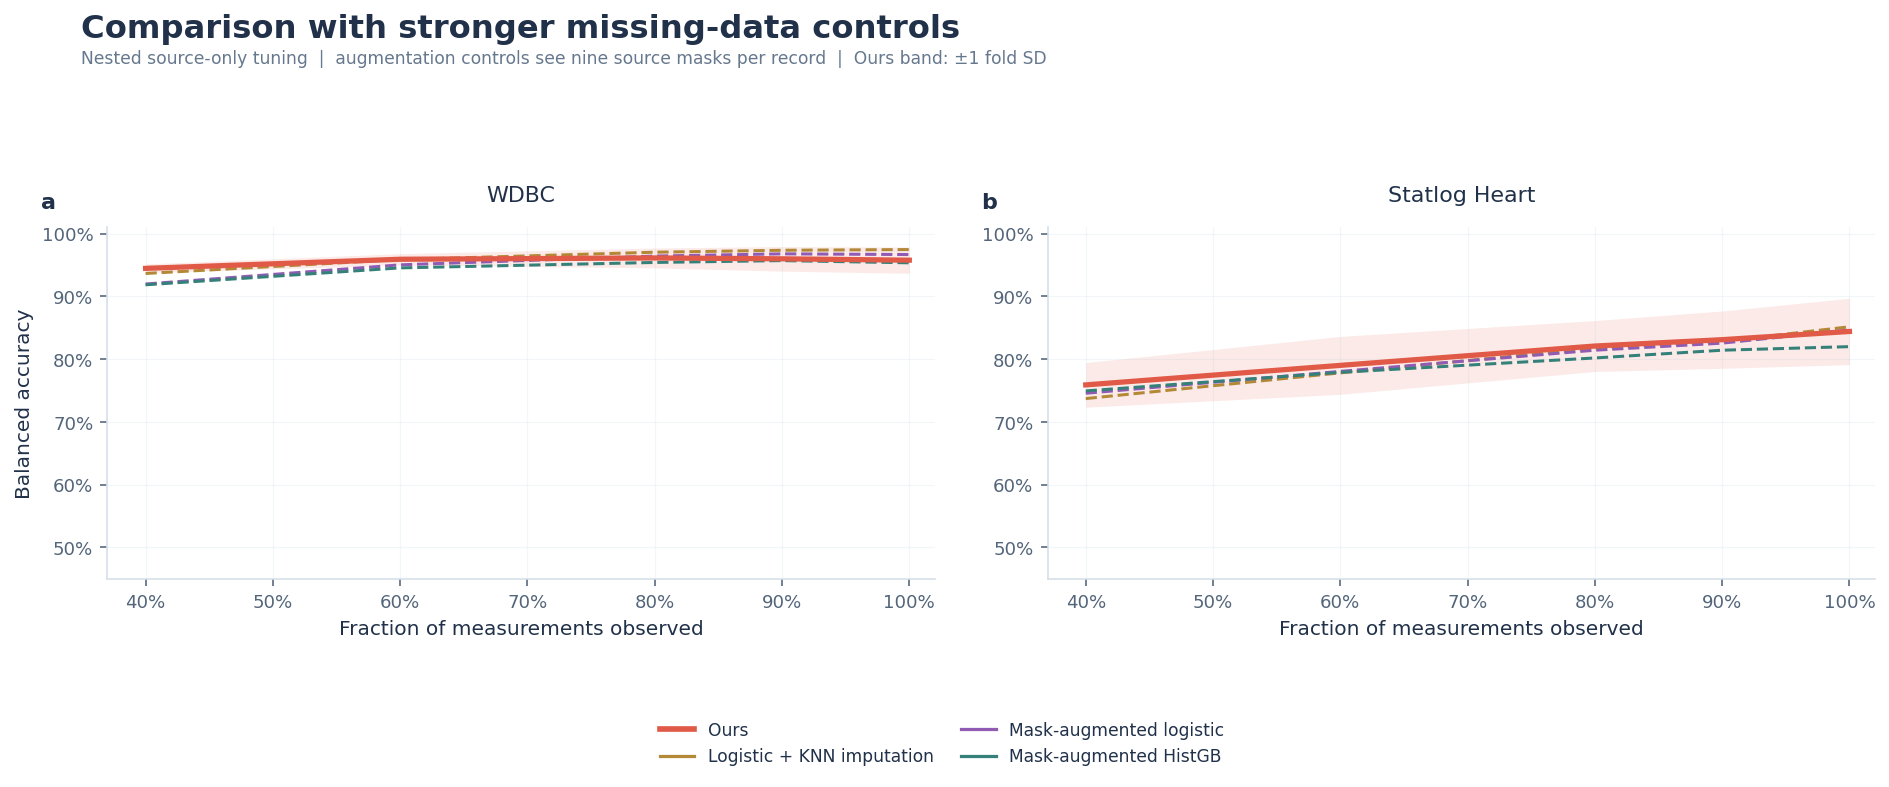

In [ ]:
# https://scikit-learn.org/stable/modules/impute.html#knnimpute
def control_pipeline(ds, name, parameter, seed):
    if name=='Mask-augmented HistGB':
        return ml_pipeline(ds, 'HistGB (native NaN)', parameter, seed)
    if name=='Mask-augmented logistic':
        preparation = ml_pipeline(ds, 'Logistic + imputation', parameter, seed).steps[0][1]
        features = FeatureUnion([('values', preparation),
            ('mask', MissingIndicator(features='all', sparse=False, error_on_new=False))])
        return make_pipeline(features, LogisticRegression(C=parameter, max_iter=2000, solver='lbfgs'))
    categorical = list(ds.categorical)
    continuous = [j for j in range(ds.X.shape[1]) if j not in categorical]
    preparation = ColumnTransformer([
        ('numeric', make_pipeline(StandardScaler(), KNNImputer(n_neighbors=5, weights='distance',
                                                              keep_empty_features=True)), continuous),
        ('category', make_pipeline(SimpleImputer(strategy='most_frequent', keep_empty_features=True),
             OneHotEncoder(handle_unknown='ignore', sparse_output=False)), categorical)])
    return make_pipeline(preparation, LogisticRegression(C=parameter, max_iter=2000, solver='lbfgs'))


def augment_source(X, y, groups, seed):
    cases = [case for case in masked_cases(X, groups, seed)
             if not (case[0]=='group dropout' and case[1]==0)]
    return np.vstack([case[3] for case in cases]), np.tile(y, len(cases))


def fit_controls(ds, train, test, fold):
    start = time.perf_counter()
    seed = CV_SEED+100*fold
    raw = {(name, parameter): [] for name in CONTROL_NAMES for parameter in [0.1,1.,10.]}
    labels, weights, empty, priors = [], [], [], []
    for inner, (fit, valid) in enumerate(subject_folds(ds, train, INNER_FOLDS, seed)):
        assert not set(ds.subjects[fit]) & set(ds.subjects[test])
        assert not set(ds.subjects[valid]) & set(ds.subjects[test])
        cases = list(masked_cases(ds.X[valid], ds.groups, seed+2000+inner))
        Xvalid = np.vstack([case[3] for case in cases])
        labels.append(np.tile(ds.y[valid], len(cases)))
        weights.append(np.tile(person_weights(ds.subjects[valid]), len(cases)))
        empty.append(~np.isfinite(Xvalid).any(axis=1))
        priors.append(np.full(len(Xvalid), ds.y[fit].mean()))
        augmented_X, augmented_y = augment_source(ds.X[fit], ds.y[fit], ds.groups, seed+7100+inner)
        for name in CONTROL_NAMES:
            Xfit, yfit = (ds.X[fit], ds.y[fit]) if name=='Logistic + KNN imputation' else (augmented_X, augmented_y)
            for parameter in [0.1,1.,10.]:
                base = MLScore(control_pipeline(ds, name, parameter, seed+inner).fit(Xfit, yfit), ds.y[fit].mean())
                raw[(name,parameter)].append(base.raw_score(Xvalid))
    y, w = np.concatenate(labels), np.concatenate(weights)
    e, p = np.concatenate(empty), np.concatenate(priors)
    statistics = {key: calibrate_oof(np.concatenate(parts), y, w, e, p) for key, parts in raw.items()}
    search_seconds = time.perf_counter()-start
    models, selections = {}, []
    augmented_X, augmented_y = augment_source(ds.X[train], ds.y[train], ds.groups, seed+7200)
    for name in CONTROL_NAMES:
        parameter = max([0.1,1.,10.], key=lambda value: statistics[(name,value)]['score'])
        statistic = statistics[(name,parameter)]
        Xfit, yfit = (ds.X[train], ds.y[train]) if name=='Logistic + KNN imputation' else (augmented_X, augmented_y)
        clock = time.perf_counter()
        base = MLScore(control_pipeline(ds, name, parameter, seed).fit(Xfit, yfit), ds.y[train].mean())
        models[name] = CalibratedPredictor(base, statistic['transform'], statistic['threshold'])
        selections.append({'dataset': ds.name, 'fold': fold, 'method': name, 'parameter': parameter,
            'inner_score': statistic['score'], 'fit_rows': len(yfit), 'distinct_train_records': len(train),
            'selected_model_fit_s': time.perf_counter()-clock, 'search_seconds': search_seconds})
    return models, selections


CONTROL_RUNS, control_rows, control_selection = {}, [], []
control_snapshot_parts = {}
for ds in DATASETS:
    for fold in range(OUTER_FOLDS):
        run = RUNS[(ds.name, fold)]
        models, selections = fit_controls(ds, run['train'], run['test'], fold)
        CONTROL_RUNS[(ds.name, fold)] = models
        control_selection.extend(selections)
        append_evaluation(control_rows, ds, run, models, CV_SEED+4000+100*fold, {}, rates=RATES)
        for mechanism, rate, repeat, X, mask in masked_cases(ds.X[run['test']], ds.groups,
                                                           CV_SEED+4000+100*fold, MASK_REPEATS):
            if repeat!=0: continue
            for name, model in models.items():
                control_snapshot_parts.setdefault((ds.name,mechanism,rate,name), []).append({
                    'y': ds.y[run['test']], 'p': model.predict_proba(X), 'person': ds.subjects[run['test']]})
        print(f'Controls | {ds.name} fold={fold+1}/{OUTER_FOLDS}', flush=True)
CONTROL_RESULTS = pd.DataFrame(control_rows)
CONTROL_SELECTIONS = pd.DataFrame(control_selection)
CONTROL_SNAPSHOTS = {key: {field: np.concatenate([part[field] for part in parts]) for field in parts[0]}
                     for key, parts in control_snapshot_parts.items()}
EXTENDED_RESULTS = pd.concat([RESULTS, CONTROL_RESULTS], ignore_index=True)
assert len(CONTROL_RESULTS)==2*OUTER_FOLDS*3*2*(1+4*MASK_REPEATS)
show_table(EXTENDED_RESULTS[EXTENDED_RESULTS.method.isin([MAIN]+CONTROL_NAMES)].groupby(
    ['dataset','method','missing_rate'], as_index=False)[METRIC_NAMES].mean(), height=360)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.4))
for ax, ds in zip(axes, DATASETS):
    frame = EXTENDED_RESULTS[EXTENDED_RESULTS.dataset==ds.name].copy()
    frame['observed_fraction'] = 1-frame.missing_rate
    draw_fold_curve(ax, frame, 'observed_fraction', [MAIN]+CONTROL_NAMES)
    ax.set_title(ds.name); ax.set_xlabel('Fraction of measurements observed')
    ax.set_xlim(0.37,1.02); ax.set_ylim(0.45,1.01)
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axes[0].set_ylabel('Balanced accuracy')
new_figure(fig, 'Comparison with stronger missing-data controls',
    'Nested source-only tuning  |  augmentation controls see nine source masks per record  |  Ours band: ±1 fold SD',
    [MAIN]+CONTROL_NAMES, ncol=2)


Missingness shift | WDBC fold=1/5
Missingness shift | WDBC fold=2/5
Missingness shift | WDBC fold=3/5
Missingness shift | WDBC fold=4/5
Missingness shift | WDBC fold=5/5
Missingness shift | Statlog Heart fold=1/5
Missingness shift | Statlog Heart fold=2/5
Missingness shift | Statlog Heart fold=3/5
Missingness shift | Statlog Heart fold=4/5
Missingness shift | Statlog Heart fold=5/5


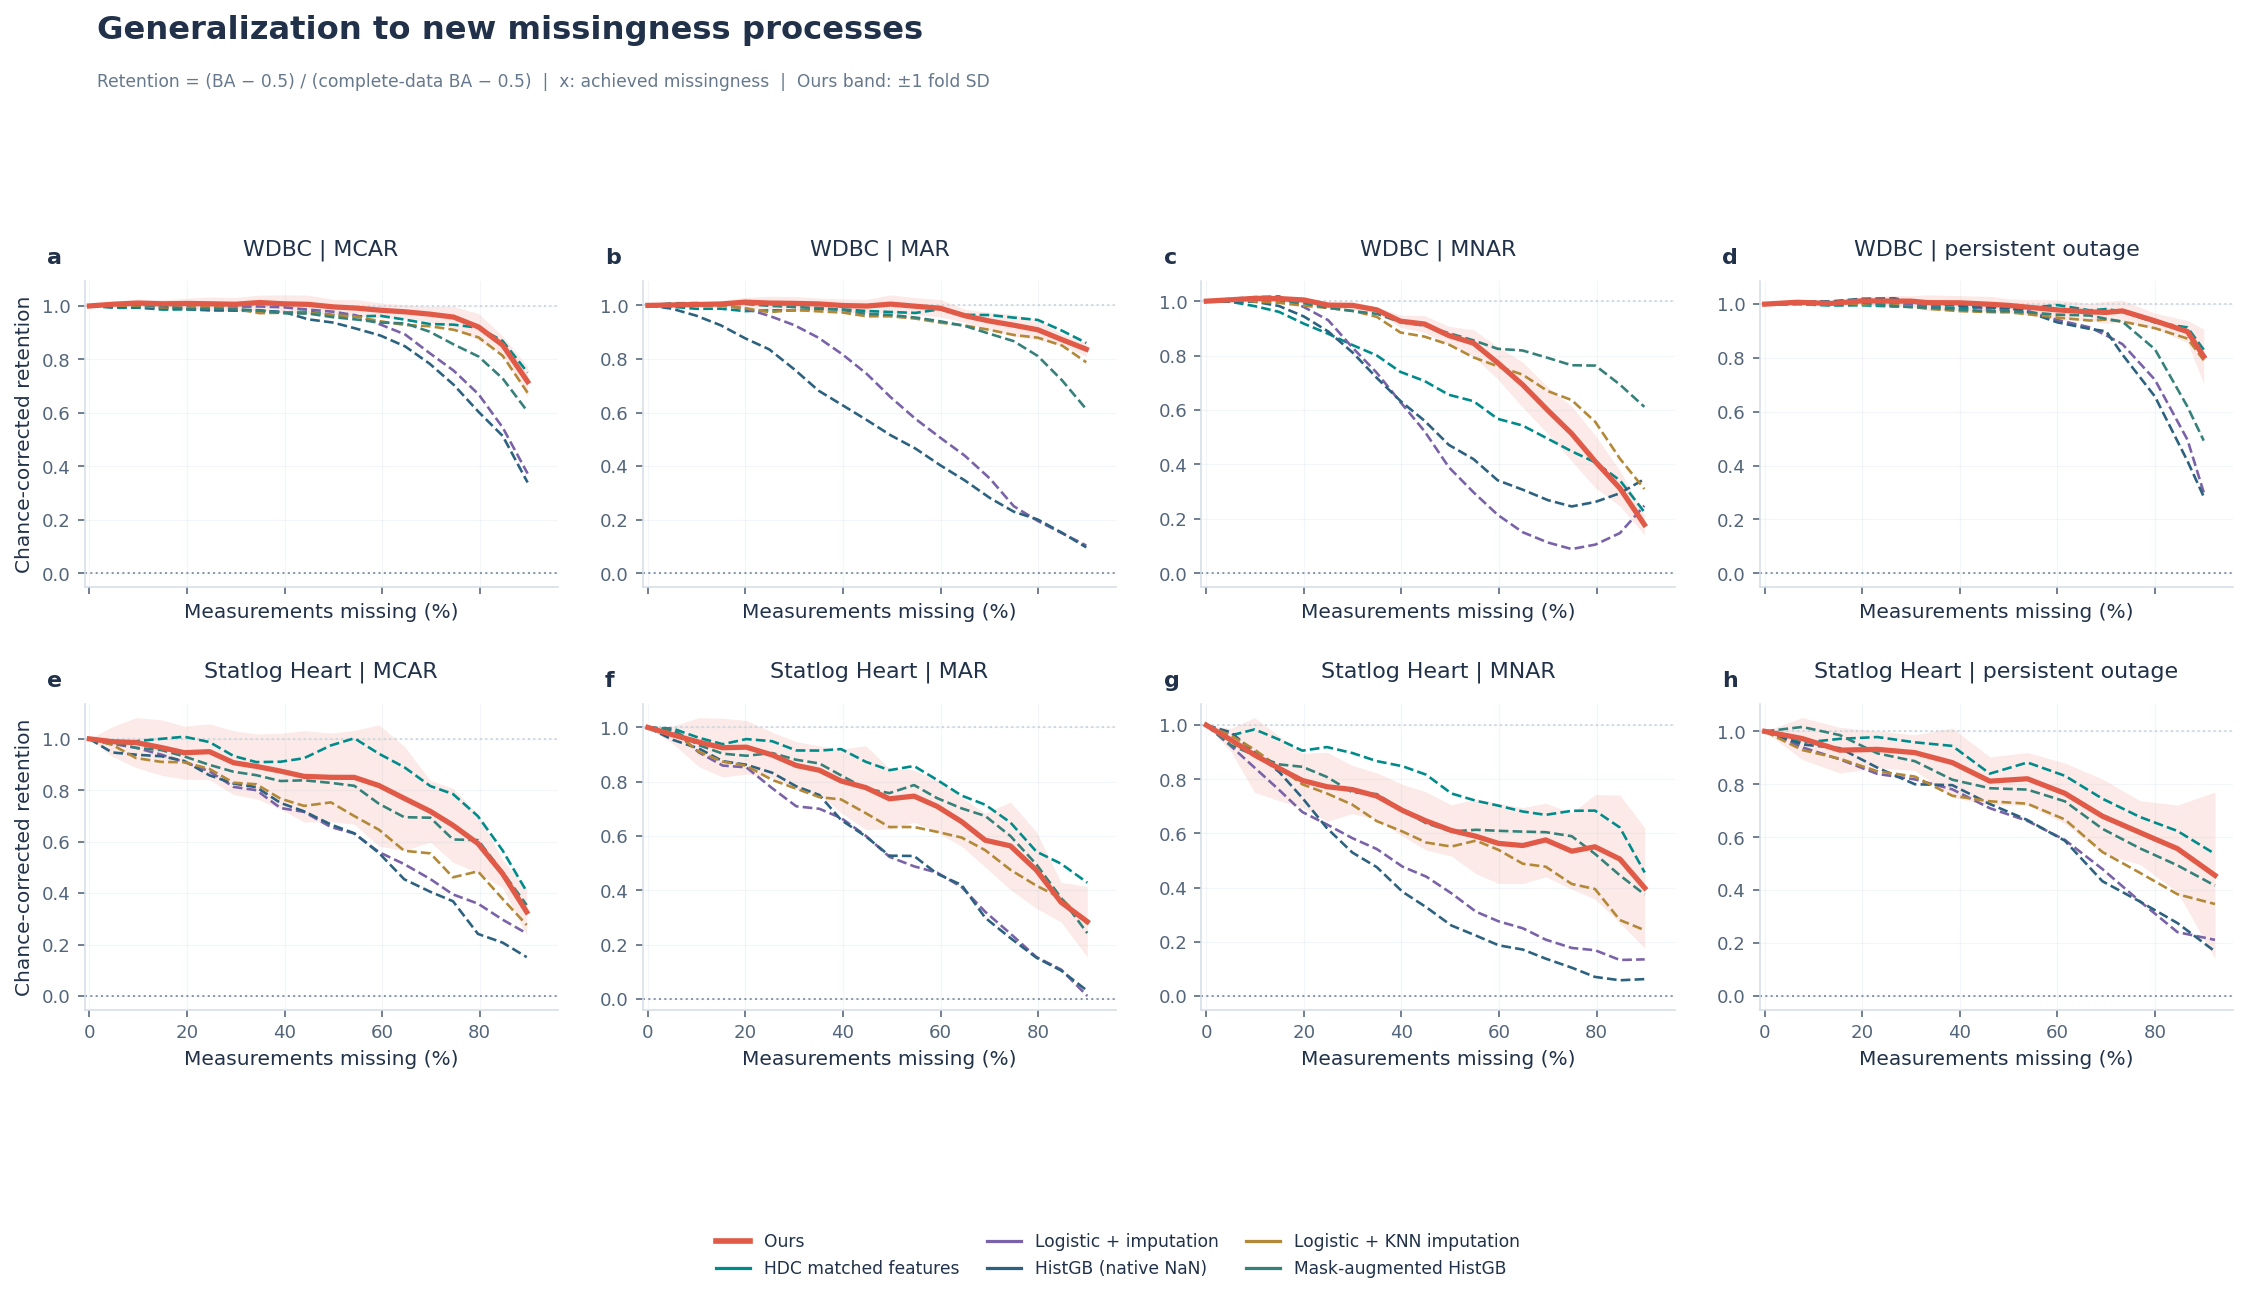

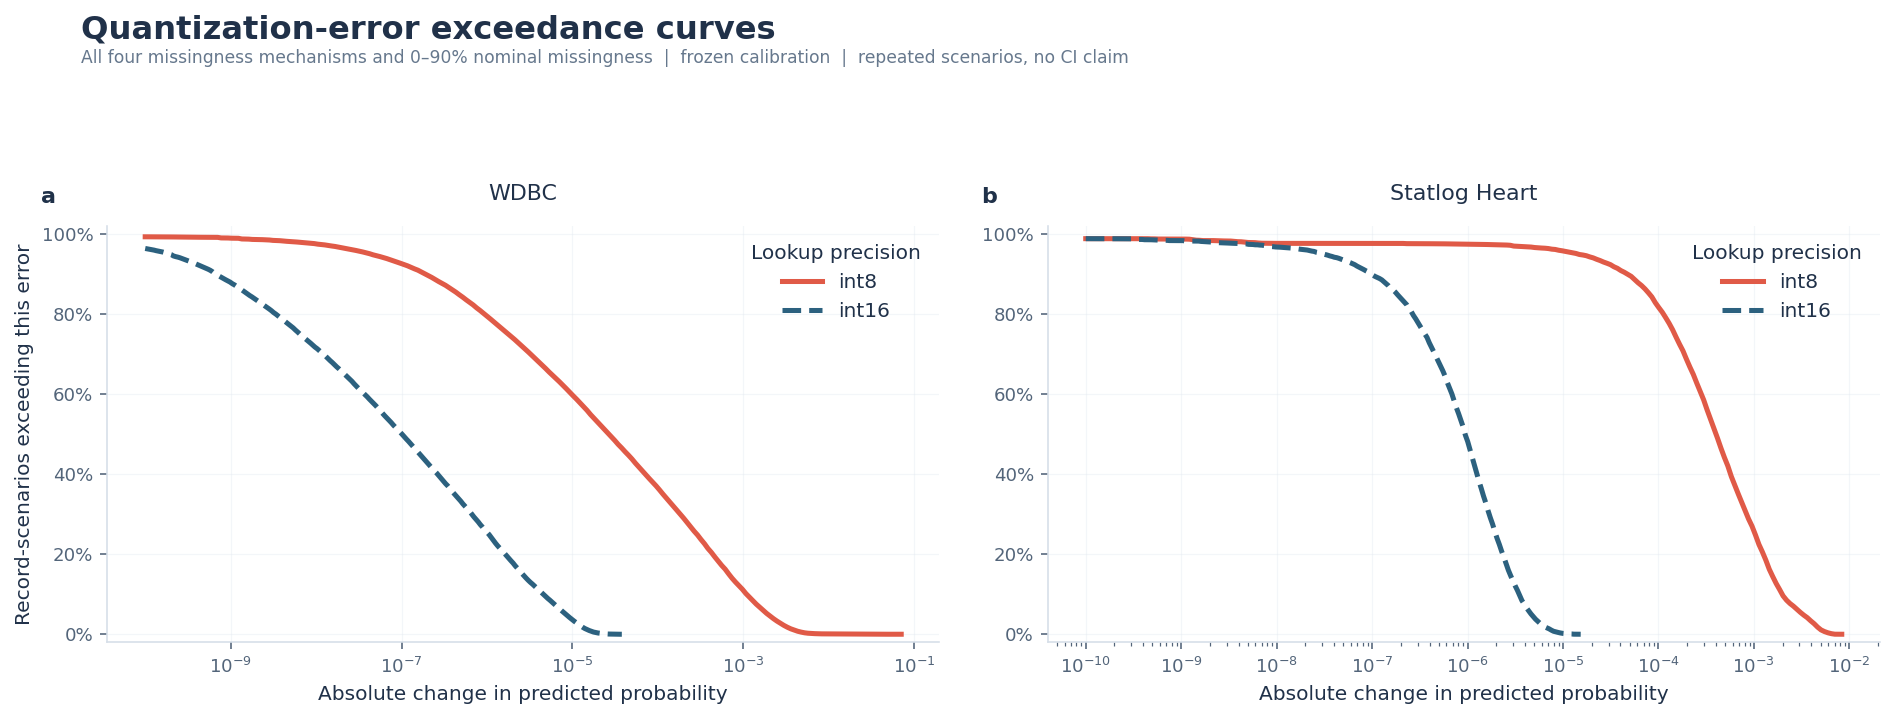

dataset,precision,record_scenarios,p99_absolute_probability_error,max_absolute_probability_error
WDBC,int8,125180,4.016e-03,6.411e-02
WDBC,int16,125180,1.541e-05,3.442e-05
Statlog Heart,int8,59400,5.158e-03,7.572e-03
Statlog Heart,int16,59400,7.573e-06,1.394e-05


In [ ]:
# Frozen complete-data models face mechanisms and severities absent from inner calibration.
DENSE_METHODS = [MAIN, 'HDC matched features', 'Logistic + imputation', 'HistGB (native NaN)',
                 'Logistic + KNN imputation', 'Mask-augmented HistGB']
dense_rows, drift_errors = [], {}
for ds in DATASETS:
    for fold in range(OUTER_FOLDS):
        run = RUNS[(ds.name,fold)]
        pool = dict(run['models'], **CONTROL_RUNS[(ds.name,fold)])
        compact = {precision: compressed_model(run,precision) for precision in ['int8','int16']}
        for mechanism, rate, repeat, X, mask in dense_cases(ds.X[run['train']], ds.X[run['test']],
                                                         EXPERIMENT_PROTOCOL['seed']+100*fold):
            predictions = {name: pool[name].predict_proba(X) for name in DENSE_METHODS}
            for name, p in predictions.items():
                dense_rows.append({'dataset': ds.name, 'fold': fold, 'mechanism': mechanism,
                    'nominal_missing': rate, 'repeat': repeat, 'realized_missing': 1-mask.mean(),
                    'method': name, **metrics(ds.y[run['test']],p,pool[name].threshold)})
            for precision, model in compact.items():
                error = np.abs(model.predict_proba(X)-predictions[MAIN]).astype(np.float32)
                drift_errors.setdefault((ds.name,precision),[]).append(error)
        print(f'Missingness shift | {ds.name} fold={fold+1}/{OUTER_FOLDS}', flush=True)
DENSE_RESULTS = pd.DataFrame(dense_rows)
reference = DENSE_RESULTS[DENSE_RESULTS.nominal_missing==0].groupby(['dataset','fold','method']).balanced_accuracy.mean()
DENSE_RESULTS['retention'] = [(row.balanced_accuracy-0.5)/max(reference.loc[(row.dataset,row.fold,row.method)]-0.5,1e-6)
                              for row in DENSE_RESULTS.itertuples()]
assert len(DENSE_RESULTS)==2*5*4*(1+18*3)*len(DENSE_METHODS)

fig, axes = plt.subplots(2, 4, figsize=(16, 9.0), sharex=True)
for row, ds in enumerate(DATASETS):
    for column, mechanism in enumerate(['MCAR','MAR','MNAR','persistent outage']):
        ax = axes[row,column]
        frame = DENSE_RESULTS[(DENSE_RESULTS.dataset==ds.name)&(DENSE_RESULTS.mechanism==mechanism)]
        for name in DENSE_METHODS:
            folds = frame[frame.method==name].groupby(['fold','nominal_missing'],as_index=False).agg(
                retention=('retention','mean'), missing=('realized_missing','mean'))
            curve = folds.groupby('nominal_missing').agg(y=('retention','mean'),sd=('retention','std'),x=('missing','mean'))
            ax.plot(100*curve.x,curve.y,color=EXTRA_COLORS[name],linewidth=2.6 if name==MAIN else 1.3,
                    linestyle='-' if name==MAIN else '--',zorder=5 if name==MAIN else 3)
            if name==MAIN:
                ax.fill_between(100*curve.x,curve.y-curve.sd,curve.y+curve.sd,
                                color=EXTRA_COLORS[name],alpha=0.12,linewidth=0)
        ax.axhline(0,color='#8A97A8',linestyle=':',linewidth=1)
        ax.axhline(1,color='#CED6DF',linestyle=':',linewidth=1)
        ax.set_title(ds.name+' | '+mechanism)
        ax.set_xlabel('Measurements missing (%)'); ax.set_xlim(-1,96)
        if column==0: ax.set_ylabel('Chance-corrected retention')
new_figure(fig,'Generalization to new missingness processes',
    'Retention = (BA − 0.5) / (complete-data BA − 0.5)  |  x: achieved missingness  |  Ours band: ±1 fold SD',
    DENSE_METHODS,ncol=3)

DRIFT_SAMPLES = {key: np.concatenate(parts) for key,parts in drift_errors.items()}
DRIFT_SUMMARY = pd.DataFrame([{'dataset':name,'precision':precision,'record_scenarios':len(error),
    'p99_absolute_probability_error':np.quantile(error,0.99),'max_absolute_probability_error':error.max()}
    for (name,precision),error in DRIFT_SAMPLES.items()])
fig, axes = plt.subplots(1,2,figsize=(13.5,5.3))
for ax,ds in zip(axes,DATASETS):
    for precision,color,style in [('int8','#E05A47','-'),('int16','#2C617F','--')]:
        errors = np.sort(DRIFT_SAMPLES[(ds.name,precision)])
        grid = np.geomspace(1e-10,max(float(errors[-1])*1.1,1e-7),220)
        tail = 1-np.searchsorted(errors,grid,side='right')/len(errors)
        ax.semilogx(grid,tail,color=color,linestyle=style,linewidth=2.5,label=precision)
    ax.set_title(ds.name); ax.set_xlabel('Absolute change in predicted probability')
    ax.set_ylim(-0.02,1.02); ax.yaxis.set_major_formatter(PercentFormatter(1,decimals=0))
    ax.legend(loc='upper right',title='Lookup precision')
axes[0].set_ylabel('Record-scenarios exceeding this error')
new_figure(fig,'Quantization-error exceedance curves',
    'All four missingness mechanisms and 0–90% nominal missingness  |  frozen calibration  |  repeated scenarios, no CI claim')
drift_view = DRIFT_SUMMARY.copy()
for column in ['p99_absolute_probability_error','max_absolute_probability_error']:
    drift_view[column] = drift_view[column].map(lambda value: f'{value:.3e}')
show_table(drift_view)


Learning 25% | WDBC fold=1/5
Learning 50% | WDBC fold=1/5
Learning 75% | WDBC fold=1/5
Learning 100% | WDBC fold=1/5
Incomplete source 0% | WDBC fold=1/5
Incomplete source 20% | WDBC fold=1/5
Incomplete source 40% | WDBC fold=1/5
Learning 25% | WDBC fold=2/5
Learning 50% | WDBC fold=2/5
Learning 75% | WDBC fold=2/5
Learning 100% | WDBC fold=2/5
Incomplete source 0% | WDBC fold=2/5
Incomplete source 20% | WDBC fold=2/5
Incomplete source 40% | WDBC fold=2/5
Learning 25% | WDBC fold=3/5
Learning 50% | WDBC fold=3/5
Learning 75% | WDBC fold=3/5
Learning 100% | WDBC fold=3/5
Incomplete source 0% | WDBC fold=3/5
Incomplete source 20% | WDBC fold=3/5
Incomplete source 40% | WDBC fold=3/5
Learning 25% | WDBC fold=4/5
Learning 50% | WDBC fold=4/5
Learning 75% | WDBC fold=4/5
Learning 100% | WDBC fold=4/5
Incomplete source 0% | WDBC fold=4/5
Incomplete source 20% | WDBC fold=4/5
Incomplete source 40% | WDBC fold=4/5
Learning 25% | WDBC fold=5/5
Learning 50% | WDBC fold=5/5
Learning 75% | WDBC fo

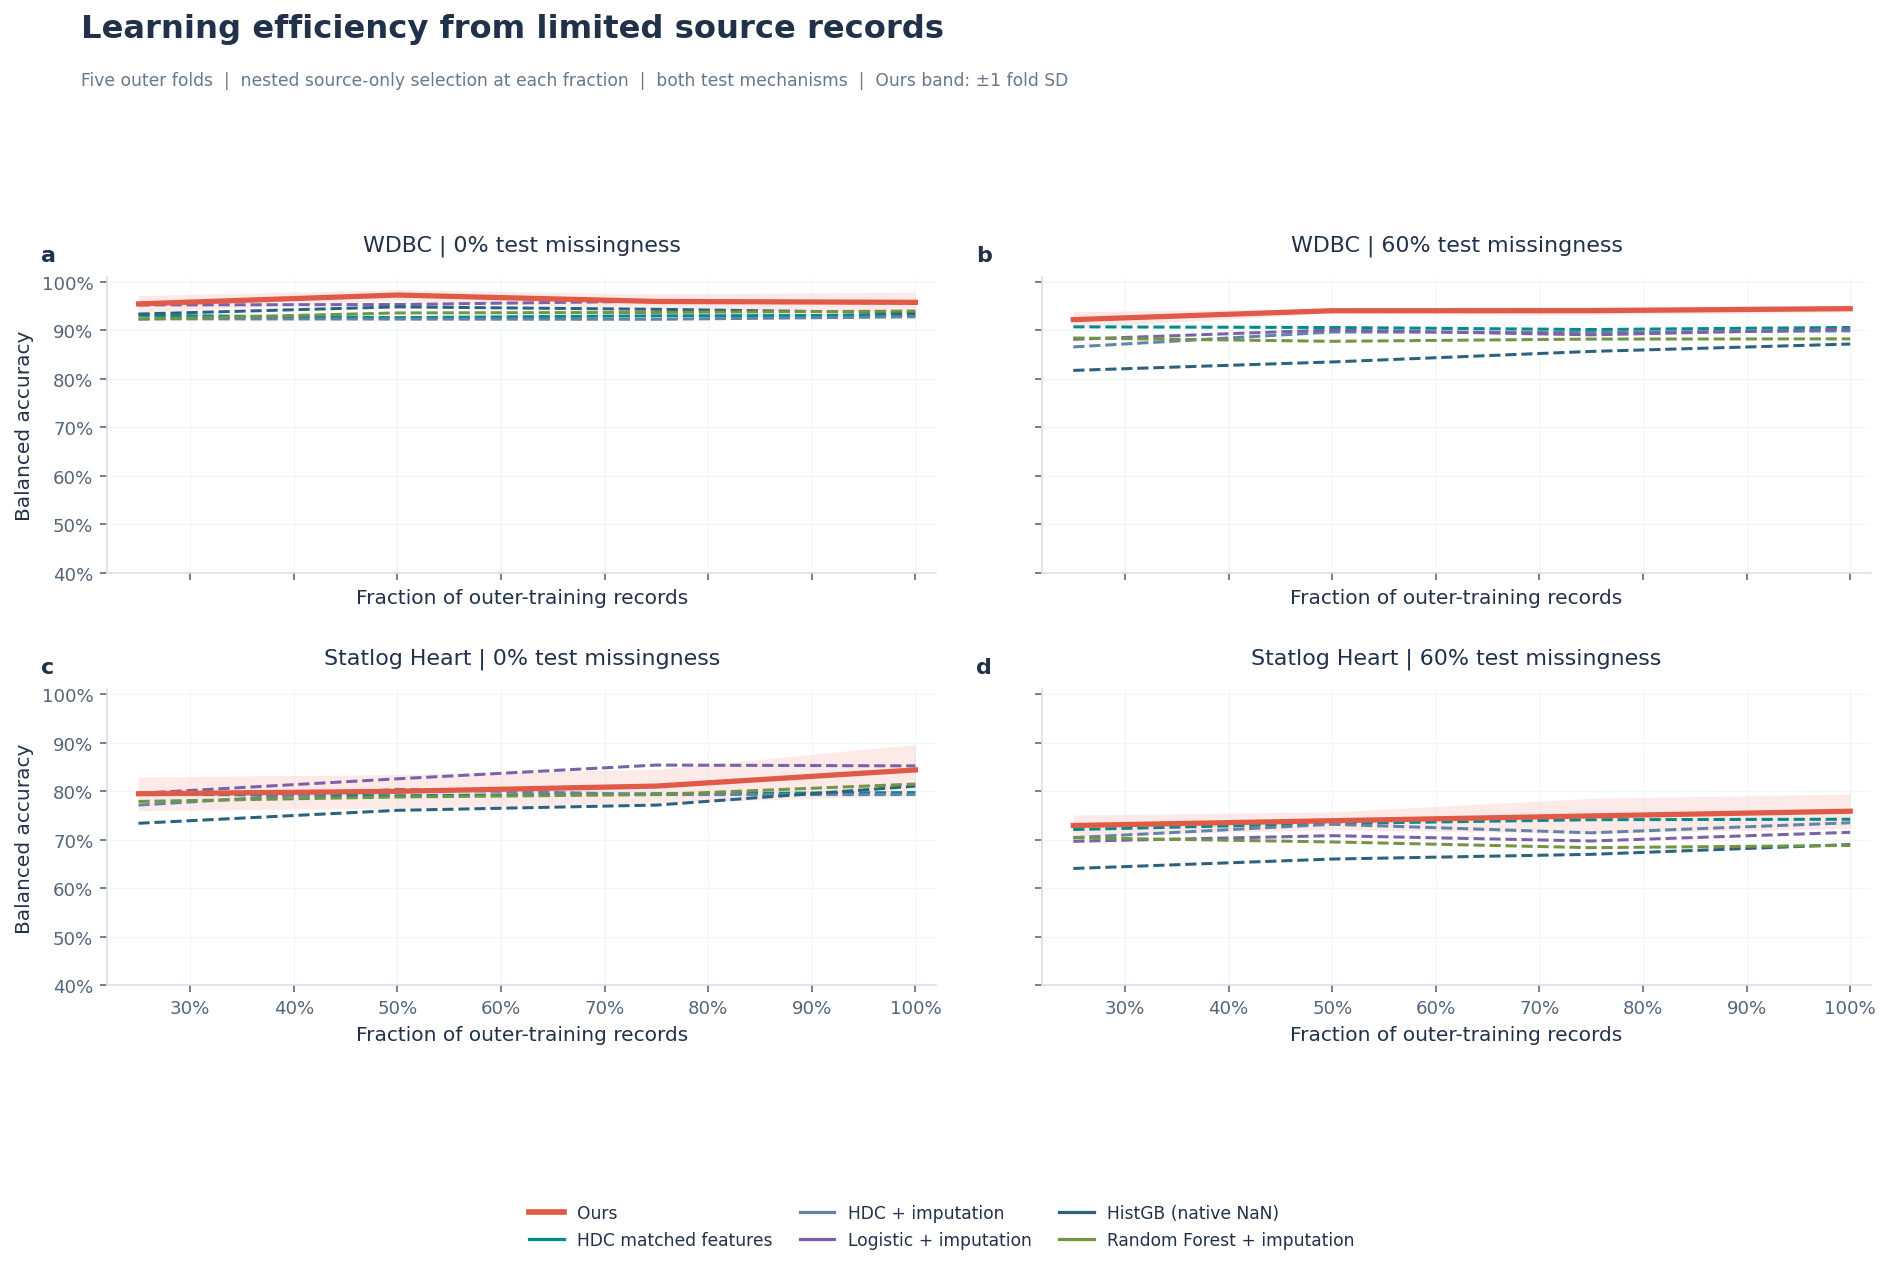

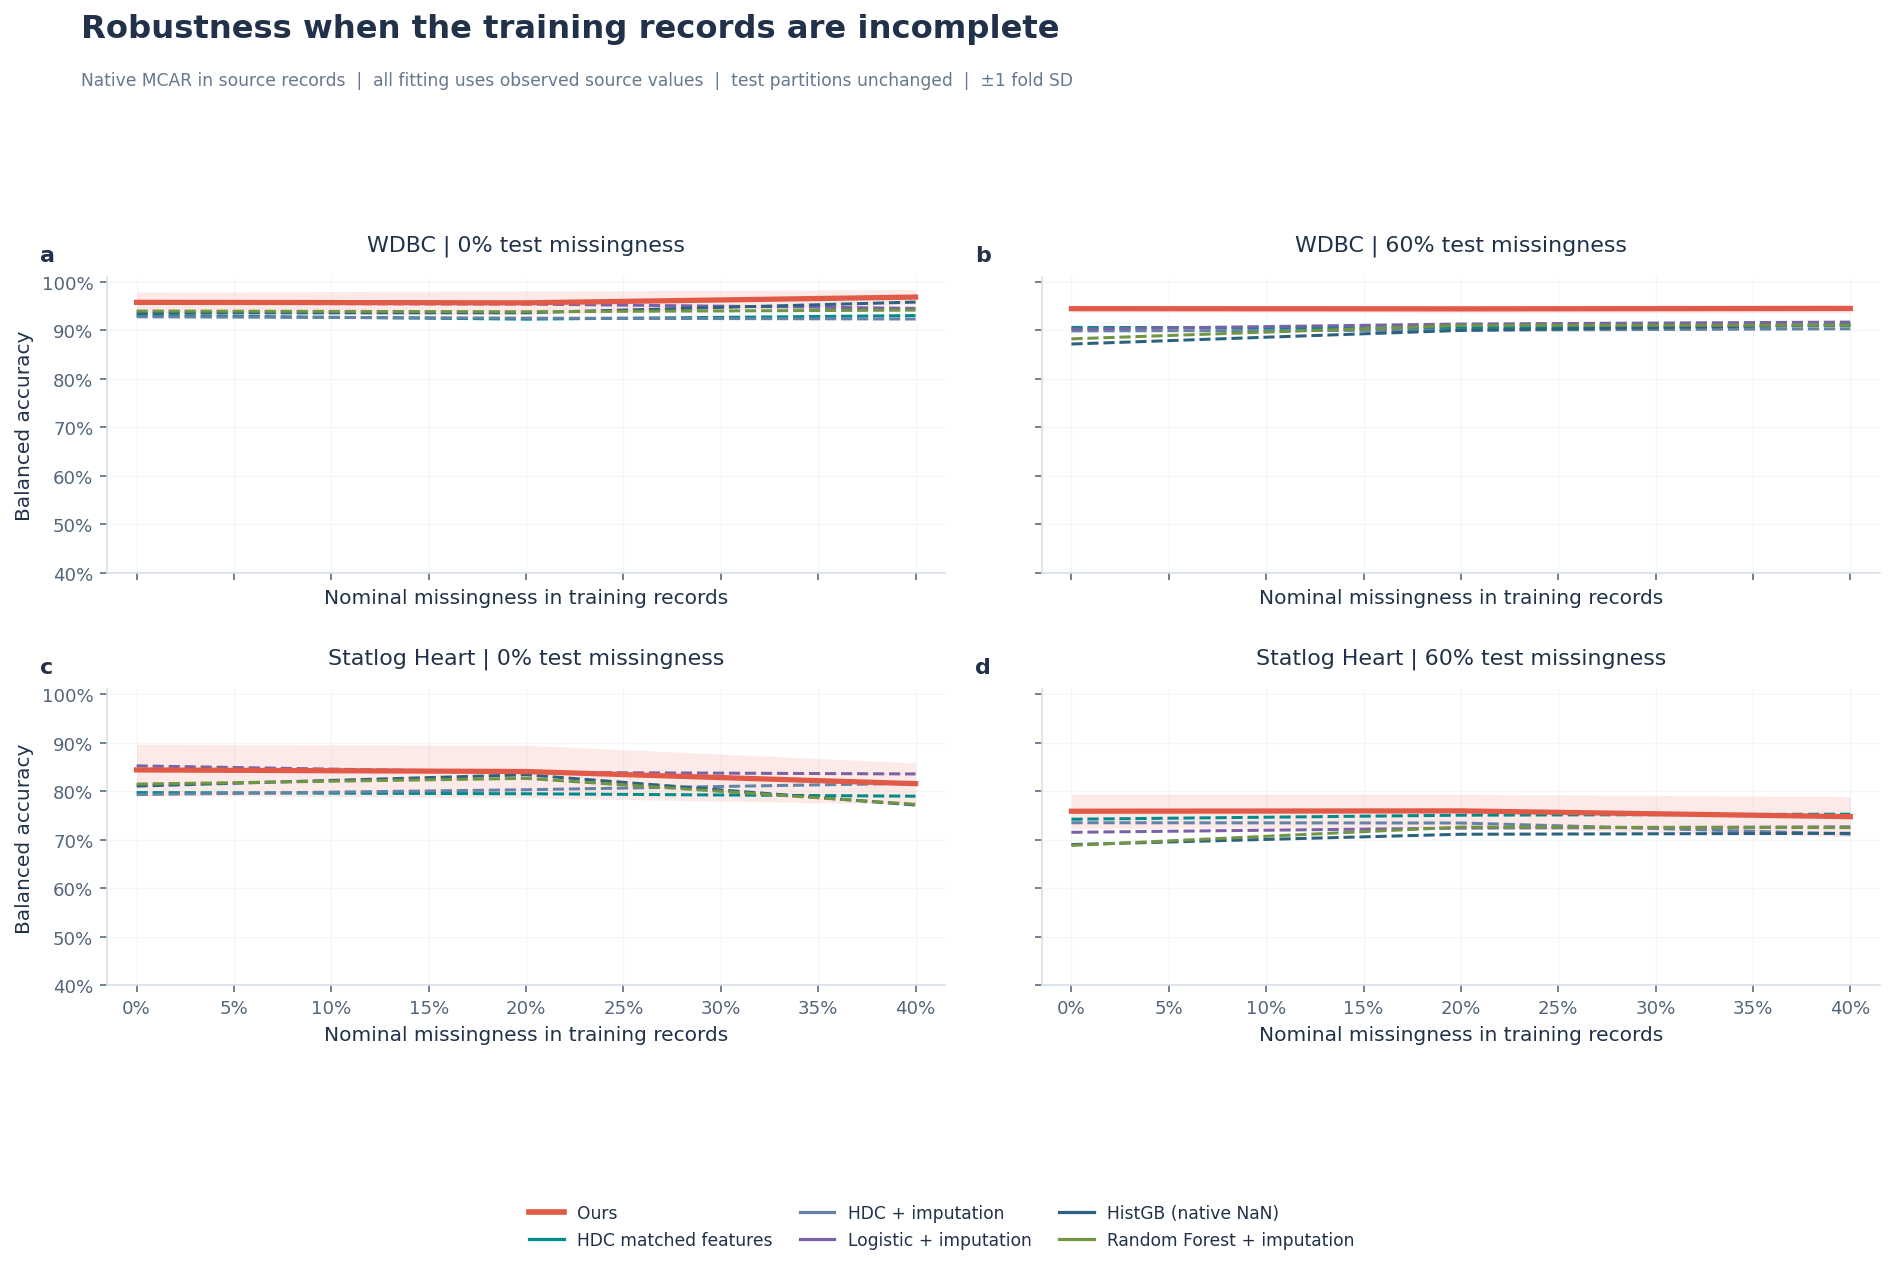

In [ ]:
# Nested, class-stratified subsets; every transform and threshold is refit inside each source subset.
learning_rows, native_rows = [], []
for ds in DATASETS:
    for fold in range(OUTER_FOLDS):
        reference_run = RUNS[(ds.name,fold)]
        train,test = reference_run['train'],reference_run['test']
        rng = np.random.default_rng(EXPERIMENT_PROTOCOL['seed']+100*fold)
        ordered = {label:rng.permutation(train[ds.y[train]==label]) for label in [0,1]}
        for fraction in EXPERIMENT_PROTOCOL['learning_fractions']:
            selected = np.sort(np.concatenate([rows[:max(INNER_FOLDS+1,int(round(fraction*len(rows))))]
                                                for rows in ordered.values()]))
            run = reference_run if fraction==1 else seeded_suite(ds,selected,test,fold)
            if fraction<1: log_run('learning',ds,fold,run)
            models = {name:run['models'][name] for name in EXTRA_METHODS}
            append_evaluation(learning_rows,ds,run,models,CV_SEED+4000+100*fold,
                {'source_fraction':fraction,'training_records':len(run['train'])})
            print(f'Learning {fraction:.0%} | {ds.name} fold={fold+1}/{OUTER_FOLDS}',flush=True)
        source_uniform = rng.random(ds.X[train].shape)
        for rate in EXPERIMENT_PROTOCOL['source_missing_rates']:
            if rate==0:
                run = reference_run
                source_missing = 0.
            else:
                source_X = ds.X.copy()
                source_X[train] = np.where(source_uniform>=rate,ds.X[train],np.nan)
                incomplete = dataset_with_X(ds,source_X)
                run = seeded_suite(incomplete,train,test,fold)
                log_run('incomplete training',incomplete,fold,run)
                source_missing = np.mean(~np.isfinite(source_X[train]))
            models = {name:run['models'][name] for name in EXTRA_METHODS}
            append_evaluation(native_rows,ds,run,models,CV_SEED+4000+100*fold,
                {'source_missing_rate':rate,'realized_source_missing':source_missing})
            print(f'Incomplete source {rate:.0%} | {ds.name} fold={fold+1}/{OUTER_FOLDS}',flush=True)
        gc.collect()
LEARNING_RESULTS = pd.DataFrame(learning_rows)
SOURCE_SPARSE_RESULTS = pd.DataFrame(native_rows)

fig,axes = plt.subplots(2,2,figsize=(13.5,8.8),sharex=True,sharey=True)
for row,ds in enumerate(DATASETS):
    for column,rate in enumerate([0.,0.6]):
        frame = LEARNING_RESULTS[(LEARNING_RESULTS.dataset==ds.name)&(LEARNING_RESULTS.missing_rate==rate)]
        draw_fold_curve(axes[row,column],frame,'source_fraction',EXTRA_METHODS)
        axes[row,column].set_title(ds.name+f' | {rate:.0%} test missingness')
        axes[row,column].set_xlabel('Fraction of outer-training records')
        axes[row,column].set_xlim(0.22,1.02); axes[row,column].set_ylim(0.4,1.01)
        axes[row,column].xaxis.set_major_formatter(PercentFormatter(1,decimals=0))
        if column==0: axes[row,column].set_ylabel('Balanced accuracy')
new_figure(fig,'Learning efficiency from limited source records',
    'Five outer folds  |  nested source-only selection at each fraction  |  both test mechanisms  |  Ours band: ±1 fold SD',
    EXTRA_METHODS,ncol=3)

fig,axes = plt.subplots(2,2,figsize=(13.5,8.8),sharex=True,sharey=True)
for row,ds in enumerate(DATASETS):
    for column,rate in enumerate([0.,0.6]):
        frame = SOURCE_SPARSE_RESULTS[(SOURCE_SPARSE_RESULTS.dataset==ds.name)&(SOURCE_SPARSE_RESULTS.missing_rate==rate)]
        draw_fold_curve(axes[row,column],frame,'source_missing_rate',EXTRA_METHODS)
        axes[row,column].set_title(ds.name+f' | {rate:.0%} test missingness')
        axes[row,column].set_xlabel('Nominal missingness in training records')
        axes[row,column].set_xlim(-0.015,0.415); axes[row,column].set_ylim(0.4,1.01)
        axes[row,column].xaxis.set_major_formatter(PercentFormatter(1,decimals=0))
        if column==0: axes[row,column].set_ylabel('Balanced accuracy')
new_figure(fig,'Robustness when the training records are incomplete',
    'Native MCAR in source records  |  all fitting uses observed source values  |  test partitions unchanged  |  ±1 fold SD',
    EXTRA_METHODS,ncol=3)


In [ ]:
# Three complete nested partitions; random mask draws are averaged within each outer fold.
repeat_frames = [RESULTS[(RESULTS.method.isin(EXTRA_METHODS)) & RESULTS.missing_rate.isin([0.,0.6])].assign(
    cv_repeat=0, partition_seed=CV_SEED)]
REPEATED_RUNS = {(name,0,fold):run for (name,fold),run in RUNS.items()}
for cv_repeat,seed in enumerate(EXPERIMENT_PROTOCOL['new_cv_seeds'],1):
    rows = []
    for ds in DATASETS:
        for fold,(train,test) in enumerate(subject_folds(ds,n_splits=OUTER_FOLDS,seed=seed)):
            run = seeded_suite(ds,train,test,fold,seed)
            REPEATED_RUNS[(ds.name,cv_repeat,fold)] = run
            log_run('repeated nested CV',ds,fold,run)
            models = {name:run['models'][name] for name in EXTRA_METHODS}
            append_evaluation(rows,ds,run,models,seed+4000+100*fold,
                              {'cv_repeat':cv_repeat,'partition_seed':seed})
            print(f'Repeated CV {cv_repeat+1}/3 | {ds.name} fold={fold+1}/{OUTER_FOLDS}',flush=True)
    repeat_frames.append(pd.DataFrame(rows))
REPEATED_RESULTS = pd.concat(repeat_frames,ignore_index=True)
REPEATED_FOLDS = REPEATED_RESULTS.groupby(['dataset','cv_repeat','fold','method','missing_rate'],
                                         as_index=False)[METRIC_NAMES].mean()
loss_parts = []
for (dataset,cv_repeat,fold),run in REPEATED_RUNS.items():
    ds = next(ds for ds in DATASETS if ds.name==dataset)
    seed = CV_SEED if cv_repeat==0 else EXPERIMENT_PROTOCOL['new_cv_seeds'][cv_repeat-1]
    test = run['test']
    for mechanism,rate,repeat,X,mask in masked_cases(ds.X[test],ds.groups,seed+4000+100*fold,
                                                    MASK_REPEATS,rates=[0.6]):
        for name in EXTRA_METHODS:
            p = run['models'][name].predict_proba(X)
            loss_parts.append(pd.DataFrame({'dataset':dataset,'cv_repeat':cv_repeat,'fold':fold,
                'person':ds.subjects[test],'method':name,'loss':(p-ds.y[test])**2}))
PERSON_LOSS = pd.concat(loss_parts,ignore_index=True).groupby(
    ['dataset','cv_repeat','person','method'],as_index=False).loss.mean()
assert len(REPEATED_RUNS)==2*3*5
assert all(len(frame)==15 for _,frame in REPEATED_FOLDS[REPEATED_FOLDS.missing_rate==0.6].groupby(['dataset','method']))
show_table(REPEATED_FOLDS.groupby(['dataset','method','missing_rate'],as_index=False).agg(
    balanced_accuracy=('balanced_accuracy','mean'),descriptive_fold_SD=('balanced_accuracy','std'),
    roc_auc=('roc_auc','mean'),brier=('brier','mean')),height=340)


Repeated CV 2/3 | WDBC fold=1/5
Repeated CV 2/3 | WDBC fold=2/5
Repeated CV 2/3 | WDBC fold=3/5
Repeated CV 2/3 | WDBC fold=4/5
Repeated CV 2/3 | WDBC fold=5/5
Repeated CV 2/3 | Statlog Heart fold=1/5
Repeated CV 2/3 | Statlog Heart fold=2/5
Repeated CV 2/3 | Statlog Heart fold=3/5
Repeated CV 2/3 | Statlog Heart fold=4/5
Repeated CV 2/3 | Statlog Heart fold=5/5
Repeated CV 3/3 | WDBC fold=1/5
Repeated CV 3/3 | WDBC fold=2/5
Repeated CV 3/3 | WDBC fold=3/5
Repeated CV 3/3 | WDBC fold=4/5
Repeated CV 3/3 | WDBC fold=5/5
Repeated CV 3/3 | Statlog Heart fold=1/5
Repeated CV 3/3 | Statlog Heart fold=2/5
Repeated CV 3/3 | Statlog Heart fold=3/5
Repeated CV 3/3 | Statlog Heart fold=4/5
Repeated CV 3/3 | Statlog Heart fold=5/5


dataset,method,missing_rate,balanced_accuracy,descriptive_fold_SD,roc_auc,brier
Statlog Heart,HDC + imputation,0.0000,0.8061,0.0344,0.9004,0.1284
Statlog Heart,HDC + imputation,0.6000,0.7191,0.0272,0.8053,0.1824
Statlog Heart,HDC matched features,0.0000,0.7956,0.0346,0.8961,0.1322
Statlog Heart,HDC matched features,0.6000,0.7367,0.0326,0.8156,0.1763
Statlog Heart,HistGB (native NaN),0.0000,0.8122,0.0473,0.8971,0.1320
Statlog Heart,HistGB (native NaN),0.6000,0.6779,0.0299,0.7845,0.1969
Statlog Heart,Logistic + imputation,0.0000,0.8522,0.0370,0.9113,0.1148
Statlog Heart,Logistic + imputation,0.6000,0.7090,0.0296,0.8059,0.1817
Statlog Heart,Ours,0.0000,0.8294,0.0508,0.9111,0.1161
Statlog Heart,Ours,0.6000,0.7562,0.0345,0.8419,0.1599


dataset,metric,baseline,paired_folds,mean_gain,corrected_SE,marginal_CI_low,marginal_CI_high,two_sided_p,holm_p
WDBC,balanced_accuracy,HDC matched features,15,0.0376,0.0063,0.0241,0.0512,3.61e-05,0.000361
WDBC,balanced_accuracy,HDC + imputation,15,0.0491,0.0072,0.0337,0.0645,8.01e-06,8.81e-05
WDBC,balanced_accuracy,Logistic + imputation,15,0.0458,0.0062,0.0324,0.0592,3.75e-06,4.5e-05
WDBC,balanced_accuracy,HistGB (native NaN),15,0.0841,0.0153,0.0514,0.1169,7.78e-05,0.0007
WDBC,brier,HDC matched features,15,0.0259,0.0034,0.0186,0.0332,2.31e-06,3.01e-05
WDBC,brier,HDC + imputation,15,0.0415,0.0039,0.0331,0.0499,4.75e-08,7.6e-07
WDBC,brier,Logistic + imputation,15,0.0335,0.0036,0.0258,0.0412,2.12e-07,3.18e-06
WDBC,brier,HistGB (native NaN),15,0.0612,0.0078,0.0445,0.0778,1.63e-06,2.28e-05
Statlog Heart,balanced_accuracy,HDC matched features,15,0.0194,0.0103,-0.0026,0.0415,0.0798,0.118
Statlog Heart,balanced_accuracy,HDC + imputation,15,0.0370,0.0160,0.0028,0.0713,0.0362,0.109


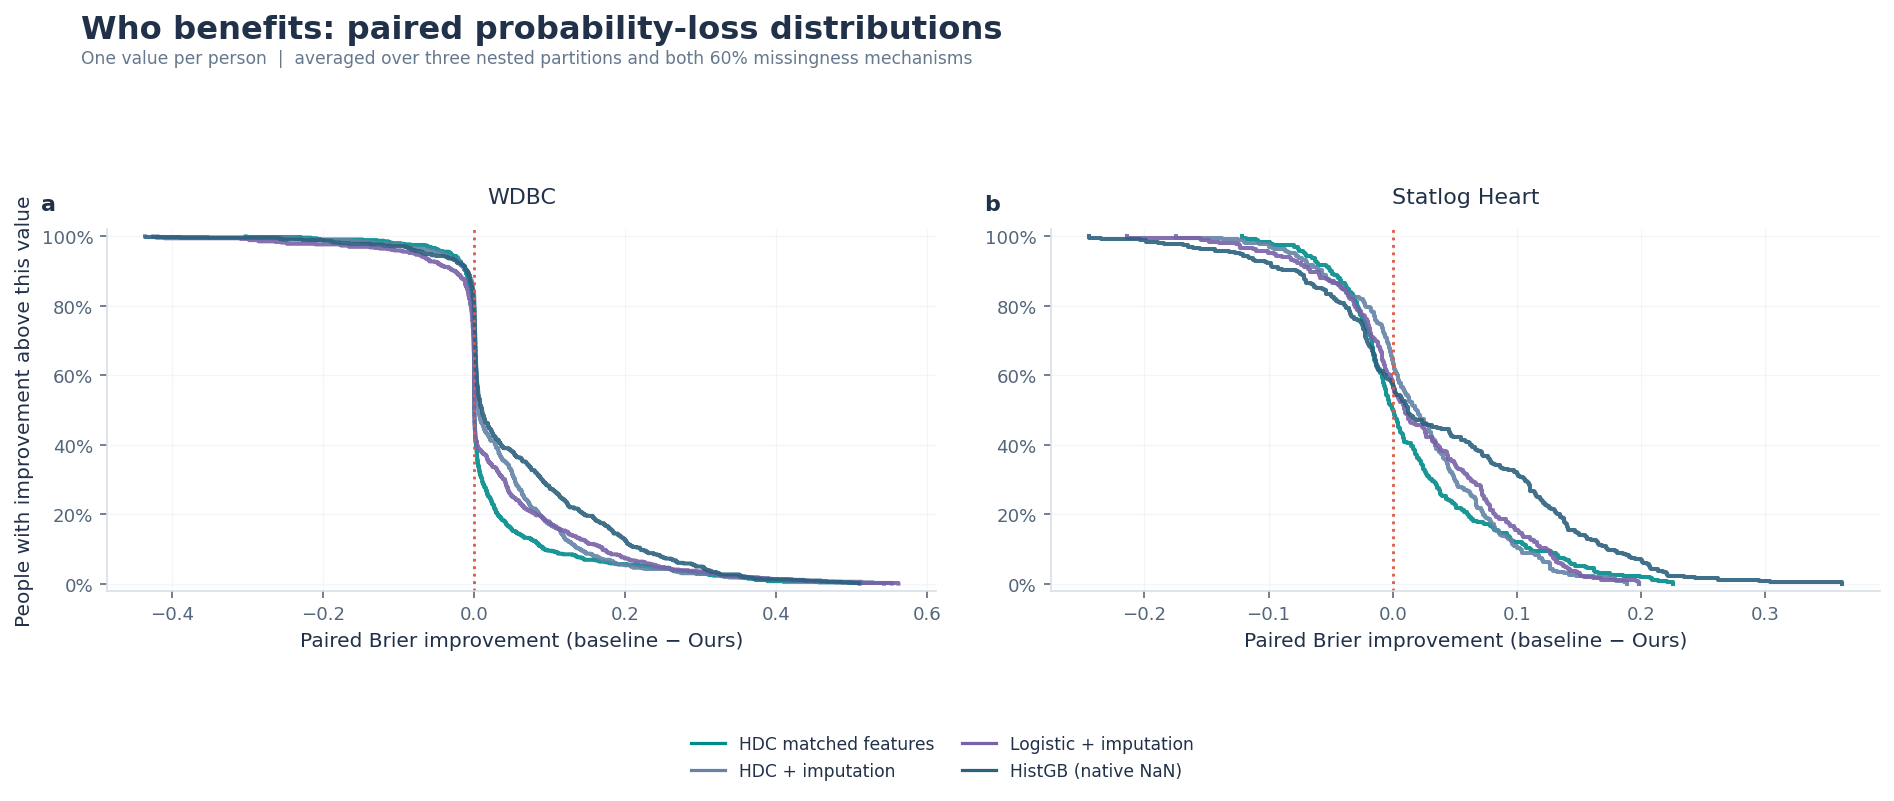

In [ ]:
# Nadeau & Bengio (1999); dependence-corrected, approximate inference on paired fold differences.
# https://scikit-learn.org/stable/auto_examples/model_selection/plot_grid_search_stats.html
PRIMARY_COMPARATORS = ['HDC matched features','HDC + imputation',
                       'Logistic + imputation','HistGB (native NaN)']
statistic_rows = []
for ds in DATASETS:
    frame = REPEATED_FOLDS[(REPEATED_FOLDS.dataset==ds.name)&(REPEATED_FOLDS.missing_rate==0.6)]
    for metric in ['balanced_accuracy','brier']:
        table = frame.pivot(index=['cv_repeat','fold'],columns='method',values=metric)
        ratios = np.array([len(REPEATED_RUNS[(ds.name,r,f)]['test']) /
                           len(REPEATED_RUNS[(ds.name,r,f)]['train']) for r,f in table.index])
        for name in PRIMARY_COMPARATORS:
            difference = (table[MAIN]-table[name]).to_numpy()
            if metric=='brier': difference = -difference
            count = len(difference)
            mean = difference.mean()
            error = np.sqrt((1/count+ratios.mean())*difference.var(ddof=1))
            if error<=1e-15:
                p = 1. if abs(mean)<=1e-15 else 0.
            else:
                p = 2*student_t.sf(abs(mean/error),df=count-1)
            radius = student_t.ppf(0.975,count-1)*error
            statistic_rows.append({'dataset':ds.name,'metric':metric,'baseline':name,
                'paired_folds':count,'mean_gain':mean,'corrected_SE':error,
                'marginal_CI_low':mean-radius,'marginal_CI_high':mean+radius,'two_sided_p':p})
CORRECTED_COMPARISONS = pd.DataFrame(statistic_rows)
order = np.argsort(CORRECTED_COMPARISONS.two_sided_p.to_numpy(),kind='stable')
adjusted = np.minimum(1,np.maximum.accumulate((len(order)-np.arange(len(order)))*
                                            CORRECTED_COMPARISONS.two_sided_p.to_numpy()[order]))
CORRECTED_COMPARISONS['holm_p'] = np.empty(len(order))
CORRECTED_COMPARISONS.loc[order,'holm_p'] = adjusted
assert len(CORRECTED_COMPARISONS)==16
assert np.all(CORRECTED_COMPARISONS.holm_p>=CORRECTED_COMPARISONS.two_sided_p-1e-12)
statistics_view = CORRECTED_COMPARISONS.copy()
for column in ['two_sided_p','holm_p']:
    statistics_view[column] = statistics_view[column].map(lambda value: f'{value:.3g}')
show_table(statistics_view,height=420)

fig,axes = plt.subplots(1,2,figsize=(13.5,5.5))
PAIRED_LOSS_GAINS = []
for ax,ds in zip(axes,DATASETS):
    frame = PERSON_LOSS[PERSON_LOSS.dataset==ds.name].groupby(['person','method']).loss.mean().unstack()
    for name in PRIMARY_COMPARATORS:
        gain = (frame[name]-frame[MAIN]).to_numpy()
        PAIRED_LOSS_GAINS.append(pd.DataFrame({'dataset':ds.name,'person':frame.index,'baseline':name,'gain':gain}))
        ordered = np.sort(gain)
        # Exact empirical survival curve, without density smoothing or fitted tails.
        x = np.r_[ordered[0],ordered,ordered[-1]]
        y = np.r_[1,1-np.arange(1,len(ordered)+1)/len(ordered),0]
        ax.step(x,y,where='post',color=EXTRA_COLORS[name],linewidth=2,alpha=0.9)
    ax.axvline(0,color=EXTRA_COLORS[MAIN],linestyle=':',linewidth=1.4)
    ax.set_title(ds.name);ax.set_xlabel('Paired Brier improvement (baseline − Ours)')
    ax.set_ylim(-0.02,1.02);ax.yaxis.set_major_formatter(PercentFormatter(1,decimals=0))
axes[0].set_ylabel('People with improvement above this value')
PAIRED_LOSS_GAINS = pd.concat(PAIRED_LOSS_GAINS,ignore_index=True)
new_figure(fig,'Who benefits: paired probability-loss distributions',
    'One value per person  |  averaged over three nested partitions and both 60% missingness mechanisms',
    PRIMARY_COMPARATORS,ncol=2)


Sensor budget | WDBC fold=1/5
Sensor budget | WDBC fold=2/5
Sensor budget | WDBC fold=3/5
Sensor budget | WDBC fold=4/5
Sensor budget | WDBC fold=5/5
Sensor budget | Statlog Heart fold=1/5
Sensor budget | Statlog Heart fold=2/5
Sensor budget | Statlog Heart fold=3/5
Sensor budget | Statlog Heart fold=4/5
Sensor budget | Statlog Heart fold=5/5


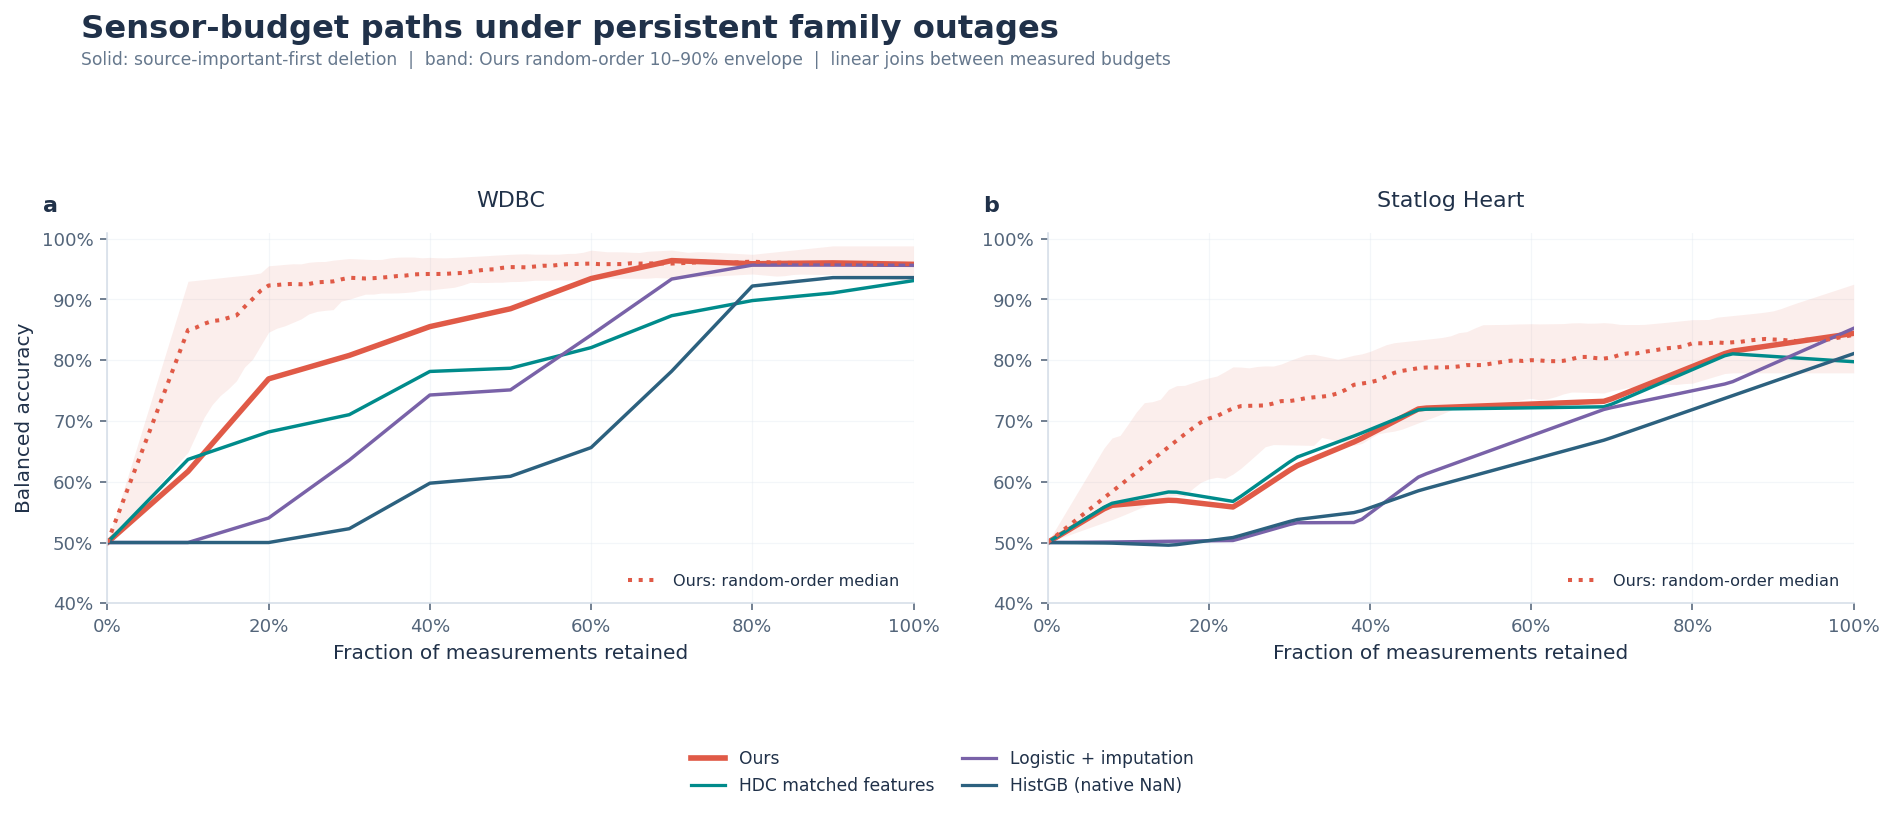

dataset,method,order_type,integrated_accuracy,descriptive_SD
Statlog Heart,HDC matched features,random,0.7353,0.0342
Statlog Heart,HDC matched features,source-ranked,0.6883,0.0380
Statlog Heart,HistGB (native NaN),random,0.6910,0.0535
Statlog Heart,HistGB (native NaN),source-ranked,0.6135,0.0488
Statlog Heart,Logistic + imputation,random,0.7120,0.0531
Statlog Heart,Logistic + imputation,source-ranked,0.6321,0.0424
Statlog Heart,Ours,random,0.7507,0.0379
Statlog Heart,Ours,source-ranked,0.6906,0.0367
WDBC,HDC matched features,random,0.8776,0.0270
WDBC,HDC matched features,source-ranked,0.7816,0.0237


In [ ]:
# Shared outages remove whole families; the ranking uses only source-trained evidence weights.
BUDGET_METHODS = [MAIN,'HDC matched features','Logistic + imputation','HistGB (native NaN)']
budget_rows = []
for ds in DATASETS:
    groups = np.unique(ds.groups)
    for fold in range(OUTER_FOLDS):
        run = RUNS[(ds.name,fold)]
        weights = run['models'][MAIN].base.evidence_weights
        importance = np.array([weights[ds.groups==group].sum() for group in groups])
        rng = np.random.default_rng(EXPERIMENT_PROTOCOL['seed']+8100+fold)
        orders = [('source-ranked',0,groups[np.argsort(-importance,kind='stable')])]
        orders += [('random',index,rng.permutation(groups)) for index in range(EXPERIMENT_PROTOCOL['group_random_orders'])]
        for order_type,index,order in orders:
            for removed in range(len(groups)+1):
                available = ~np.isin(ds.groups,order[:removed])
                X = np.where(available[None],ds.X[run['test']],np.nan)
                for name in BUDGET_METHODS:
                    model = run['models'][name]
                    p = model.predict_proba(X)
                    budget_rows.append({'dataset':ds.name,'fold':fold,'method':name,
                        'order_type':order_type,'order_index':index,'removed_groups':removed,
                        'observed_fraction':available.mean(),
                        'balanced_accuracy':fast_ba(ds.y[run['test']],p>=model.threshold),
                        'brier':np.mean((p-ds.y[run['test']])**2)})
        print(f'Sensor budget | {ds.name} fold={fold+1}/{OUTER_FOLDS}',flush=True)
GROUP_BUDGET_RESULTS = pd.DataFrame(budget_rows)
integrated_rows = []
for key,frame in GROUP_BUDGET_RESULTS.groupby(['dataset','fold','method','order_type','order_index']):
    frame = frame.sort_values('observed_fraction')
    integrated_rows.append(dict(zip(['dataset','fold','method','order_type','order_index'],key),
        integrated_accuracy=scipy.integrate.trapezoid(frame.balanced_accuracy,frame.observed_fraction)))
GROUP_BUDGET_INTEGRALS = pd.DataFrame(integrated_rows)
q = np.linspace(0,1,101)
fig,axes = plt.subplots(1,2,figsize=(13.5,5.6))
for ax,ds in zip(axes,DATASETS):
    frame = GROUP_BUDGET_RESULTS[GROUP_BUDGET_RESULTS.dataset==ds.name]
    for name in BUDGET_METHODS:
        paths = []
        for fold,part in frame[(frame.method==name)&(frame.order_type=='source-ranked')].groupby('fold'):
            part = part.sort_values('observed_fraction')
            paths.append(np.interp(q,part.observed_fraction,part.balanced_accuracy))
        ax.plot(q,np.mean(paths,axis=0),color=EXTRA_COLORS[name],linewidth=2.7 if name==MAIN else 1.7)
    random_paths = []
    for key,part in frame[(frame.method==MAIN)&(frame.order_type=='random')].groupby(['fold','order_index']):
        part = part.sort_values('observed_fraction')
        random_paths.append(np.interp(q,part.observed_fraction,part.balanced_accuracy))
    low,median,high = np.quantile(random_paths,[0.1,0.5,0.9],axis=0)
    ax.fill_between(q,low,high,color=EXTRA_COLORS[MAIN],alpha=0.10,linewidth=0)
    random_line, = ax.plot(q,median,':',color=EXTRA_COLORS[MAIN],linewidth=2,label='Ours: random-order median')
    ax.legend(handles=[random_line],loc='lower right',fontsize=8)
    ax.set_title(ds.name);ax.set_xlabel('Fraction of measurements retained')
    ax.set_xlim(0,1);ax.set_ylim(0.4,1.01)
    ax.xaxis.set_major_formatter(PercentFormatter(1,decimals=0))
    ax.yaxis.set_major_formatter(PercentFormatter(1,decimals=0))
axes[0].set_ylabel('Balanced accuracy')
new_figure(fig,'Sensor-budget paths under persistent family outages',
    'Solid: source-important-first deletion  |  band: Ours random-order 10–90% envelope  |  linear joins between measured budgets',
    BUDGET_METHODS,ncol=2)
show_table(GROUP_BUDGET_INTEGRALS.groupby(['dataset','method','order_type'],as_index=False).agg(
    integrated_accuracy=('integrated_accuracy','mean'),descriptive_SD=('integrated_accuracy','std')),height=300)


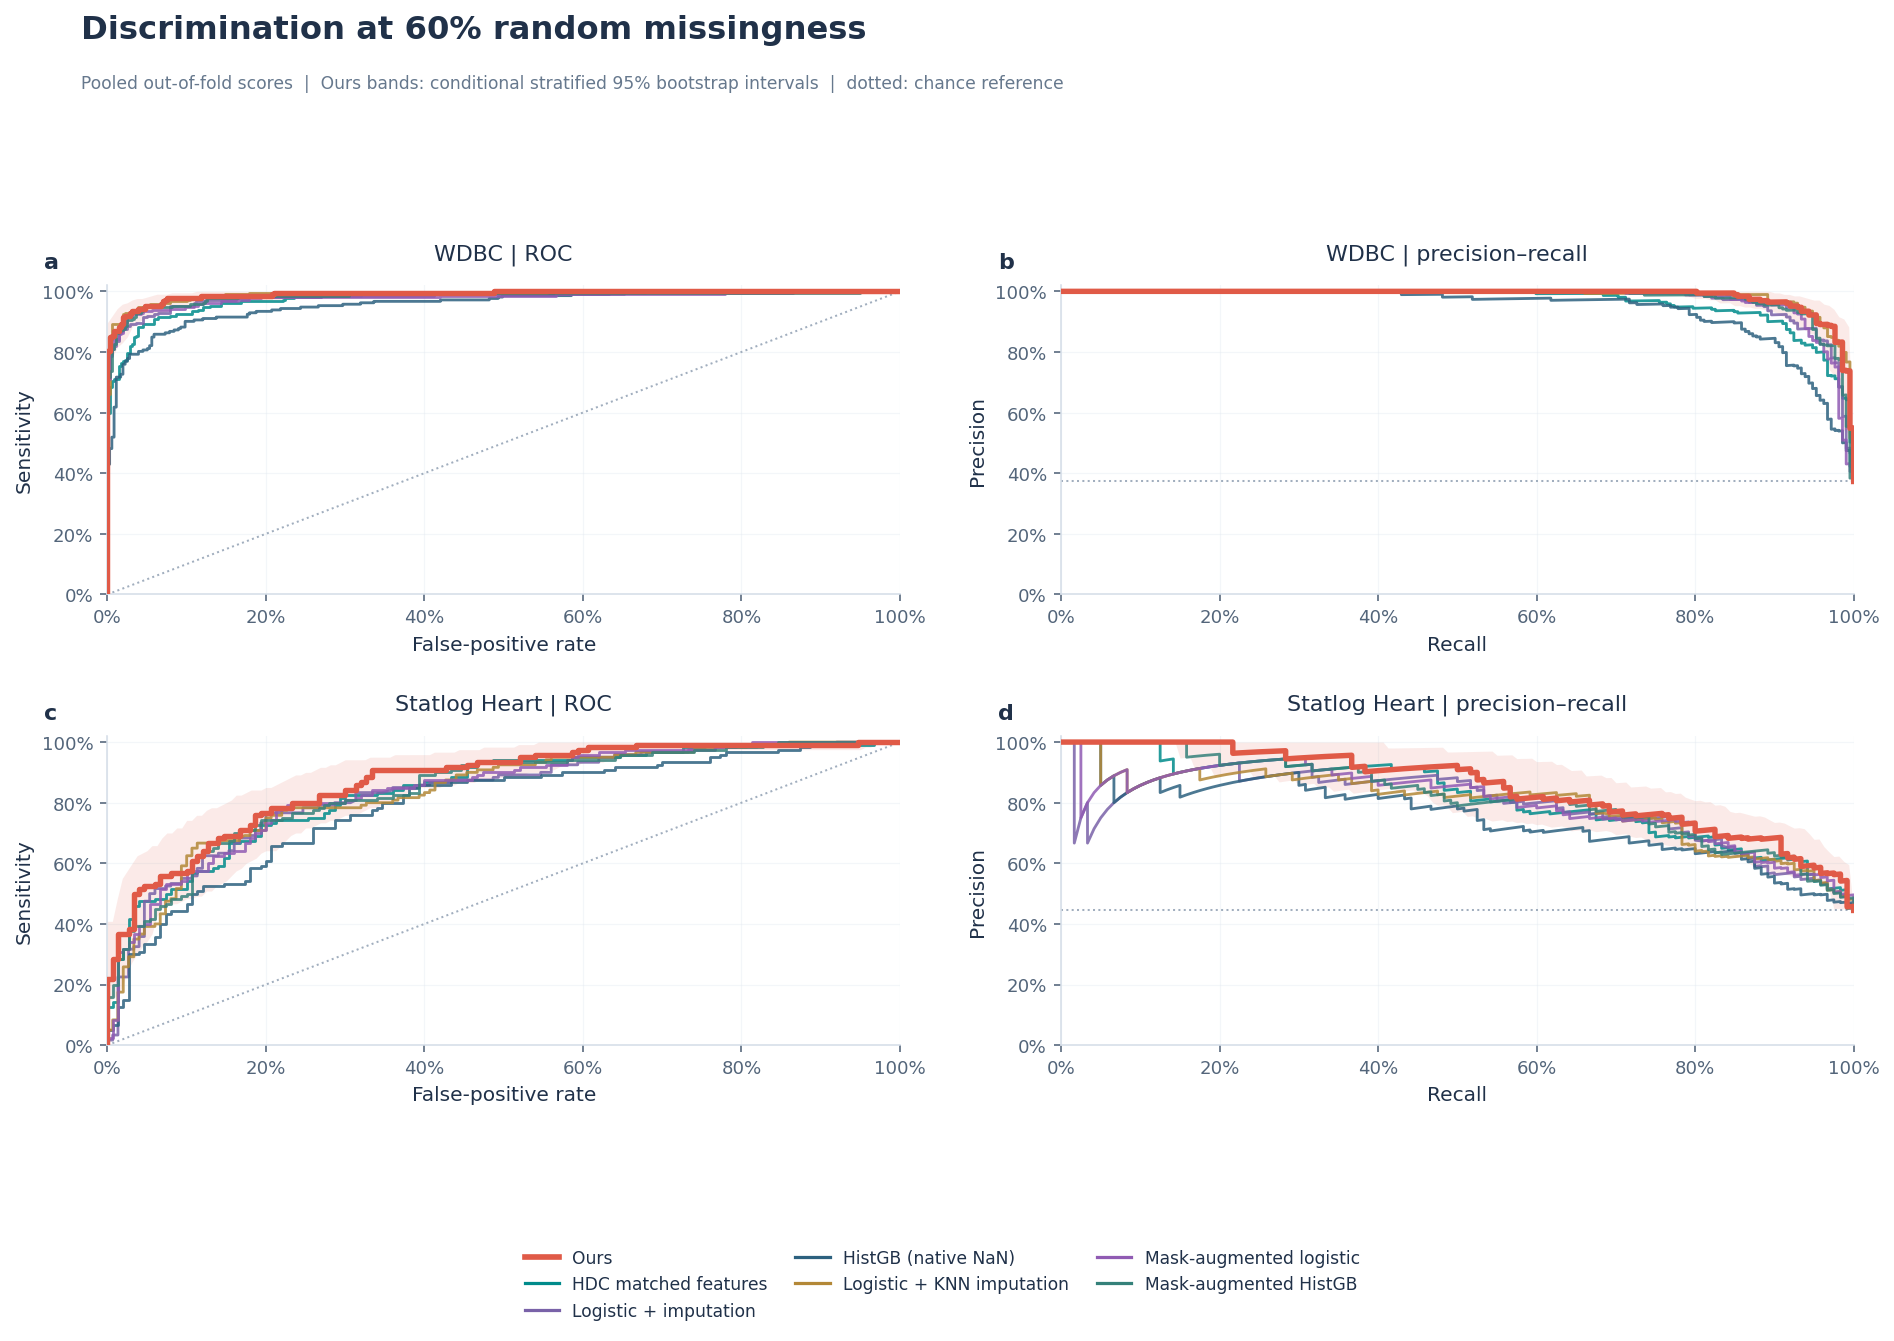

dataset,method,roc_auc,average_precision
WDBC,Ours,0.9905,0.9869
WDBC,HDC matched features,0.9768,0.9670
WDBC,Logistic + imputation,0.9818,0.9777
WDBC,HistGB (native NaN),0.9561,0.9437
WDBC,Logistic + KNN imputation,0.9903,0.9866
WDBC,Mask-augmented logistic,0.9789,0.9768
WDBC,Mask-augmented HistGB,0.9835,0.9801
Statlog Heart,Ours,0.8682,0.8521
Statlog Heart,HDC matched features,0.8398,0.8176
Statlog Heart,Logistic + imputation,0.8333,0.7895


In [ ]:
# Discrimination curves use the existing outer-fold predictions, never target-fitted thresholds.
CURVE_METHODS = [MAIN,'HDC matched features','Logistic + imputation','HistGB (native NaN)']+CONTROL_NAMES
curve_metrics = []
fig,axes = plt.subplots(2,2,figsize=(13.5,9.3))
grid = np.linspace(0,1,161)
for row,ds in enumerate(DATASETS):
    snapshots = {name:(SNAPSHOTS if name in METHODS else CONTROL_SNAPSHOTS)[(ds.name,'MCAR',0.6,name)]
                 for name in CURVE_METHODS}
    reference = snapshots[MAIN]
    for name,snap in snapshots.items():
        assert np.array_equal(snap['person'],reference['person'])
        assert np.array_equal(snap['y'],reference['y'])
        fpr,tpr,_ = roc_curve(snap['y'],snap['p'])
        precision,recall,_ = precision_recall_curve(snap['y'],snap['p'])
        axes[row,0].plot(fpr,tpr,color=EXTRA_COLORS[name],linewidth=2.7 if name==MAIN else 1.4,
                         alpha=1 if name==MAIN else 0.85,zorder=5 if name==MAIN else 3)
        axes[row,1].plot(recall,precision,color=EXTRA_COLORS[name],linewidth=2.7 if name==MAIN else 1.4,
                         alpha=1 if name==MAIN else 0.85,zorder=5 if name==MAIN else 3)
        curve_metrics.append({'dataset':ds.name,'method':name,'roc_auc':roc_auc_score(snap['y'],snap['p']),
                              'average_precision':average_precision_score(snap['y'],snap['p'])})
    y,p = reference['y'],reference['p']
    strata = [np.flatnonzero(y==label) for label in [0,1]]
    rng = np.random.default_rng(EXPERIMENT_PROTOCOL['seed']+row)
    roc_bands,pr_bands = [],[]
    for _ in range(EXPERIMENT_PROTOCOL['curve_bootstraps']):
        indices = np.concatenate([rng.choice(s,len(s),replace=True) for s in strata])
        fpr,tpr,_ = roc_curve(y[indices],p[indices])
        precision,recall,_ = precision_recall_curve(y[indices],p[indices])
        roc_bands.append(np.interp(grid,fpr,tpr))
        pr_bands.append(np.interp(grid,recall[::-1],precision[::-1]))
    for column,bands in enumerate([roc_bands,pr_bands]):
        low,high = np.quantile(bands,[0.025,0.975],axis=0)
        axes[row,column].fill_between(grid,low,high,color=EXTRA_COLORS[MAIN],alpha=0.12,linewidth=0,zorder=2)
        axes[row,column].set_xlim(0,1);axes[row,column].set_ylim(0,1.02)
        axes[row,column].xaxis.set_major_formatter(PercentFormatter(1,decimals=0))
        axes[row,column].yaxis.set_major_formatter(PercentFormatter(1,decimals=0))
    axes[row,0].plot([0,1],[0,1],':',color='#A1AEBE',linewidth=1)
    axes[row,1].axhline(y.mean(),linestyle=':',color='#A1AEBE',linewidth=1)
    axes[row,0].set_title(ds.name+' | ROC');axes[row,1].set_title(ds.name+' | precision–recall')
    axes[row,0].set_xlabel('False-positive rate');axes[row,0].set_ylabel('Sensitivity')
    axes[row,1].set_xlabel('Recall');axes[row,1].set_ylabel('Precision')
DISCRIMINATION_RESULTS = pd.DataFrame(curve_metrics)
new_figure(fig,'Discrimination at 60% random missingness',
    'Pooled out-of-fold scores  |  Ours bands: conditional stratified 95% bootstrap intervals  |  dotted: chance reference',
    CURVE_METHODS,ncol=3)
show_table(DISCRIMINATION_RESULTS,height=320)


Batch scaling | WDBC fold=1/5
Batch scaling | WDBC fold=2/5
Batch scaling | WDBC fold=3/5
Batch scaling | WDBC fold=4/5
Batch scaling | WDBC fold=5/5
Batch scaling | Statlog Heart fold=1/5
Batch scaling | Statlog Heart fold=2/5
Batch scaling | Statlog Heart fold=3/5
Batch scaling | Statlog Heart fold=4/5
Batch scaling | Statlog Heart fold=5/5


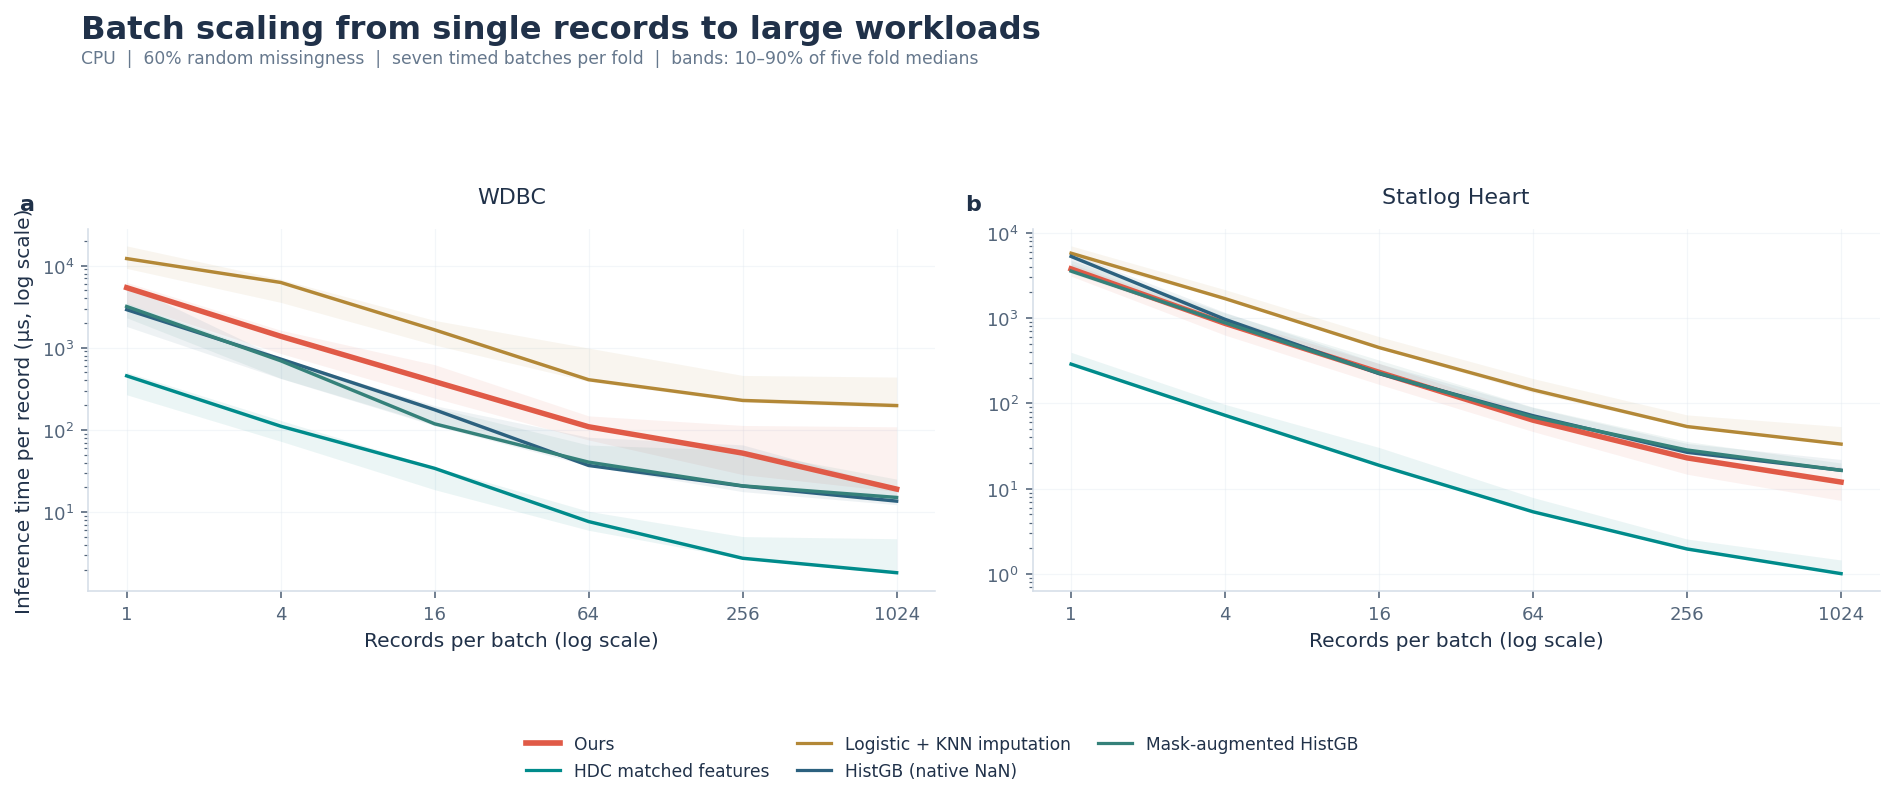

dataset,method,single_record_us,deployment_KiB
Statlog Heart,HDC matched features,288.3940,5.8303
Statlog Heart,HistGB (native NaN),5274.3830,148.4779
Statlog Heart,Logistic + KNN imputation,5752.2840,15.0381
Statlog Heart,Mask-augmented HistGB,3548.9600,150.5744
Statlog Heart,Ours,3769.3340,14.4021
WDBC,HDC matched features,454.9410,17.1807
WDBC,HistGB (native NaN),2908.1790,186.2986
WDBC,Logistic + KNN imputation,12160.4630,123.6973
WDBC,Mask-augmented HistGB,3176.5580,186.4080
WDBC,Ours,5384.0230,39.5473


Runtime: Linux-6.6.159+-x86_64-with-glibc2.39 | NumPy 2.1.3 | SciPy 1.16.3 | scikit-learn 1.6.1


In [ ]:
# CPU inference only; timings include imputation, encoding, calibration and prediction.
BATCH_METHODS = [MAIN,'HDC matched features','Logistic + KNN imputation',
                 'HistGB (native NaN)','Mask-augmented HistGB']
batch_rows = []
for ds in DATASETS:
    for fold in range(OUTER_FOLDS):
        run = RUNS[(ds.name,fold)]
        pool = dict(run['models'],**CONTROL_RUNS[(ds.name,fold)])
        Xsource = next(case[3] for case in masked_cases(ds.X[run['test']],ds.groups,
                         CV_SEED+4000+100*fold,rates=[0.6]) if case[0]=='MCAR')
        rng = np.random.default_rng(EXPERIMENT_PROTOCOL['seed']+fold)
        for size in EXPERIMENT_PROTOCOL['batch_sizes']:
            Xbatch = Xsource[rng.choice(len(Xsource),size=size,replace=True)]
            for name in BATCH_METHODS:
                model = pool[name]
                model.predict_proba(Xbatch)
                times = []
                for _ in range(7):
                    clock = time.perf_counter_ns()
                    model.predict_proba(Xbatch)
                    times.append((time.perf_counter_ns()-clock)/1000/size)
                batch_rows.append({'dataset':ds.name,'fold':fold,'method':name,'batch_size':size,
                    'median_us_per_record':np.median(times),'p10_us_per_record':np.quantile(times,0.1),
                    'p90_us_per_record':np.quantile(times,0.9),'deployment_KiB':len(pickle.dumps(model,protocol=5))/1024})
        print(f'Batch scaling | {ds.name} fold={fold+1}/{OUTER_FOLDS}',flush=True)
BATCH_RESULTS = pd.DataFrame(batch_rows)
fig,axes = plt.subplots(1,2,figsize=(13.5,5.5))
for ax,ds in zip(axes,DATASETS):
    for name in BATCH_METHODS:
        grouped = BATCH_RESULTS[(BATCH_RESULTS.dataset==ds.name)&(BATCH_RESULTS.method==name)].groupby('batch_size').median_us_per_record
        median,low,high = grouped.median(),grouped.quantile(0.1),grouped.quantile(0.9)
        ax.plot(median.index,median,color=EXTRA_COLORS[name],linewidth=2.7 if name==MAIN else 1.7)
        ax.fill_between(median.index,low,high,color=EXTRA_COLORS[name],alpha=0.08,linewidth=0)
    ax.set_xscale('log',base=2);ax.set_yscale('log')
    ax.set_xticks(EXPERIMENT_PROTOCOL['batch_sizes'],[str(n) for n in EXPERIMENT_PROTOCOL['batch_sizes']])
    ax.set_title(ds.name);ax.set_xlabel('Records per batch (log scale)')
axes[0].set_ylabel('Inference time per record (µs, log scale)')
new_figure(fig,'Batch scaling from single records to large workloads',
    'CPU  |  60% random missingness  |  seven timed batches per fold  |  bands: 10–90% of five fold medians',
    BATCH_METHODS,ncol=3)
show_table(BATCH_RESULTS[BATCH_RESULTS.batch_size==1].groupby(['dataset','method'],as_index=False).agg(
    single_record_us=('median_us_per_record','median'),deployment_KiB=('deployment_KiB','mean')),height=300)
print('Runtime:',platform.platform(),'| NumPy',np.__version__,'| SciPy',scipy.__version__,'| scikit-learn',sklearn.__version__)


In [ ]:
# Original methods, data, results, and thresholds remain unchanged after all supplementary tests.
assert hashlib.sha256(pd.util.hash_pandas_object(RESULTS,index=True).values.tobytes()).hexdigest()==ORIGINAL_RESULTS_SHA256
for key,run in RUNS.items():
    assert hashlib.sha256(pickle.dumps(run['models'][MAIN],protocol=5)).hexdigest()==ORIGINAL_MODEL_HASHES[key]
for ds in DATASETS:
    assert hashlib.sha256(ds.X.tobytes()+ds.y.tobytes()).hexdigest()==ORIGINAL_DATA_HASHES[ds.name]
assert hashlib.sha256(json.dumps(EXPERIMENT_PROTOCOL,sort_keys=True).encode()).hexdigest()==EXPERIMENT_PROTOCOL_SHA256
EXPERIMENT_FITS = pd.DataFrame(EXPERIMENT_LOG)
assert EXPERIMENT_FITS.source_only.all()
assert len(EXPERIMENT_FITS)==70
for frame in [CONTROL_RESULTS,DENSE_RESULTS,LEARNING_RESULTS,SOURCE_SPARSE_RESULTS,
              REPEATED_RESULTS,GROUP_BUDGET_RESULTS,DISCRIMINATION_RESULTS,BATCH_RESULTS]:
    assert set(frame.dataset)==set(ds.name for ds in DATASETS)
    assert np.isfinite(frame.select_dtypes('number')).all().all()
SUPPLEMENTARY_AUDIT = pd.DataFrame([
    {'experiment':'Stronger controls','result_rows':len(CONTROL_RESULTS),'unit':'fold × paired mask draw × method'},
    {'experiment':'Missingness shift','result_rows':len(DENSE_RESULTS),'unit':'fold × mechanism × rate × draw × method'},
    {'experiment':'Learning curves','result_rows':len(LEARNING_RESULTS),'unit':'source fraction × fold × paired mask × method'},
    {'experiment':'Incomplete training','result_rows':len(SOURCE_SPARSE_RESULTS),'unit':'source missingness × fold × paired mask × method'},
    {'experiment':'Repeated nested CV','result_rows':len(REPEATED_RESULTS),'unit':'partition × fold × paired mask × method'},
    {'experiment':'Corrected paired comparisons','result_rows':len(CORRECTED_COMPARISONS),'unit':'cohort × metric × baseline; 16-test Holm family'},
    {'experiment':'Sensor-budget paths','result_rows':len(GROUP_BUDGET_RESULTS),'unit':'fold × deletion order × budget × method'},
    {'experiment':'ROC / precision–recall','result_rows':len(DISCRIMINATION_RESULTS),'unit':'cohort × method; conditional bootstrap bands'},
    {'experiment':'Batch scaling','result_rows':len(BATCH_RESULTS),'unit':'fold × batch size × method; seven timing draws'}])
show_table(SUPPLEMENTARY_AUDIT)
print('PASS | original experiments preserved |',len(NEW_FIGURES),'new curve-based figures | PNG and SVG embedded inline')
print('PASS | source-only selection | fixed outer test partitions | no new dataset exclusions')
print('Scope: supplementary internal evidence on two cohorts selected after development; independent validation remains untested.')


experiment,result_rows,unit
Stronger controls,780,fold × paired mask draw × method
Missingness shift,13200,fold × mechanism × rate × draw × method
Learning curves,1920,source fraction × fold × paired mask × method
Incomplete training,1440,source missingness × fold × paired mask × method
Repeated nested CV,1440,partition × fold × paired mask × method
Corrected paired comparisons,16,cohort × metric × baseline; 16-test Holm family
Sensor-budget paths,6460,fold × deletion order × budget × method
ROC / precision–recall,14,cohort × method; conditional bootstrap bands
Batch scaling,300,fold × batch size × method; seven timing draws


PASS | original experiments preserved | 9 new curve-based figures | PNG and SVG embedded inline
PASS | source-only selection | fixed outer test partitions | no new dataset exclusions
Scope: supplementary internal evidence on two cohorts selected after development; independent validation remains untested.
